# Psychometric analysis


Invalid number of bins provided. Defaulting to 4.
Processing data and generating figure...
Done! Figure saved to reverse_pooled_psychometrics.png


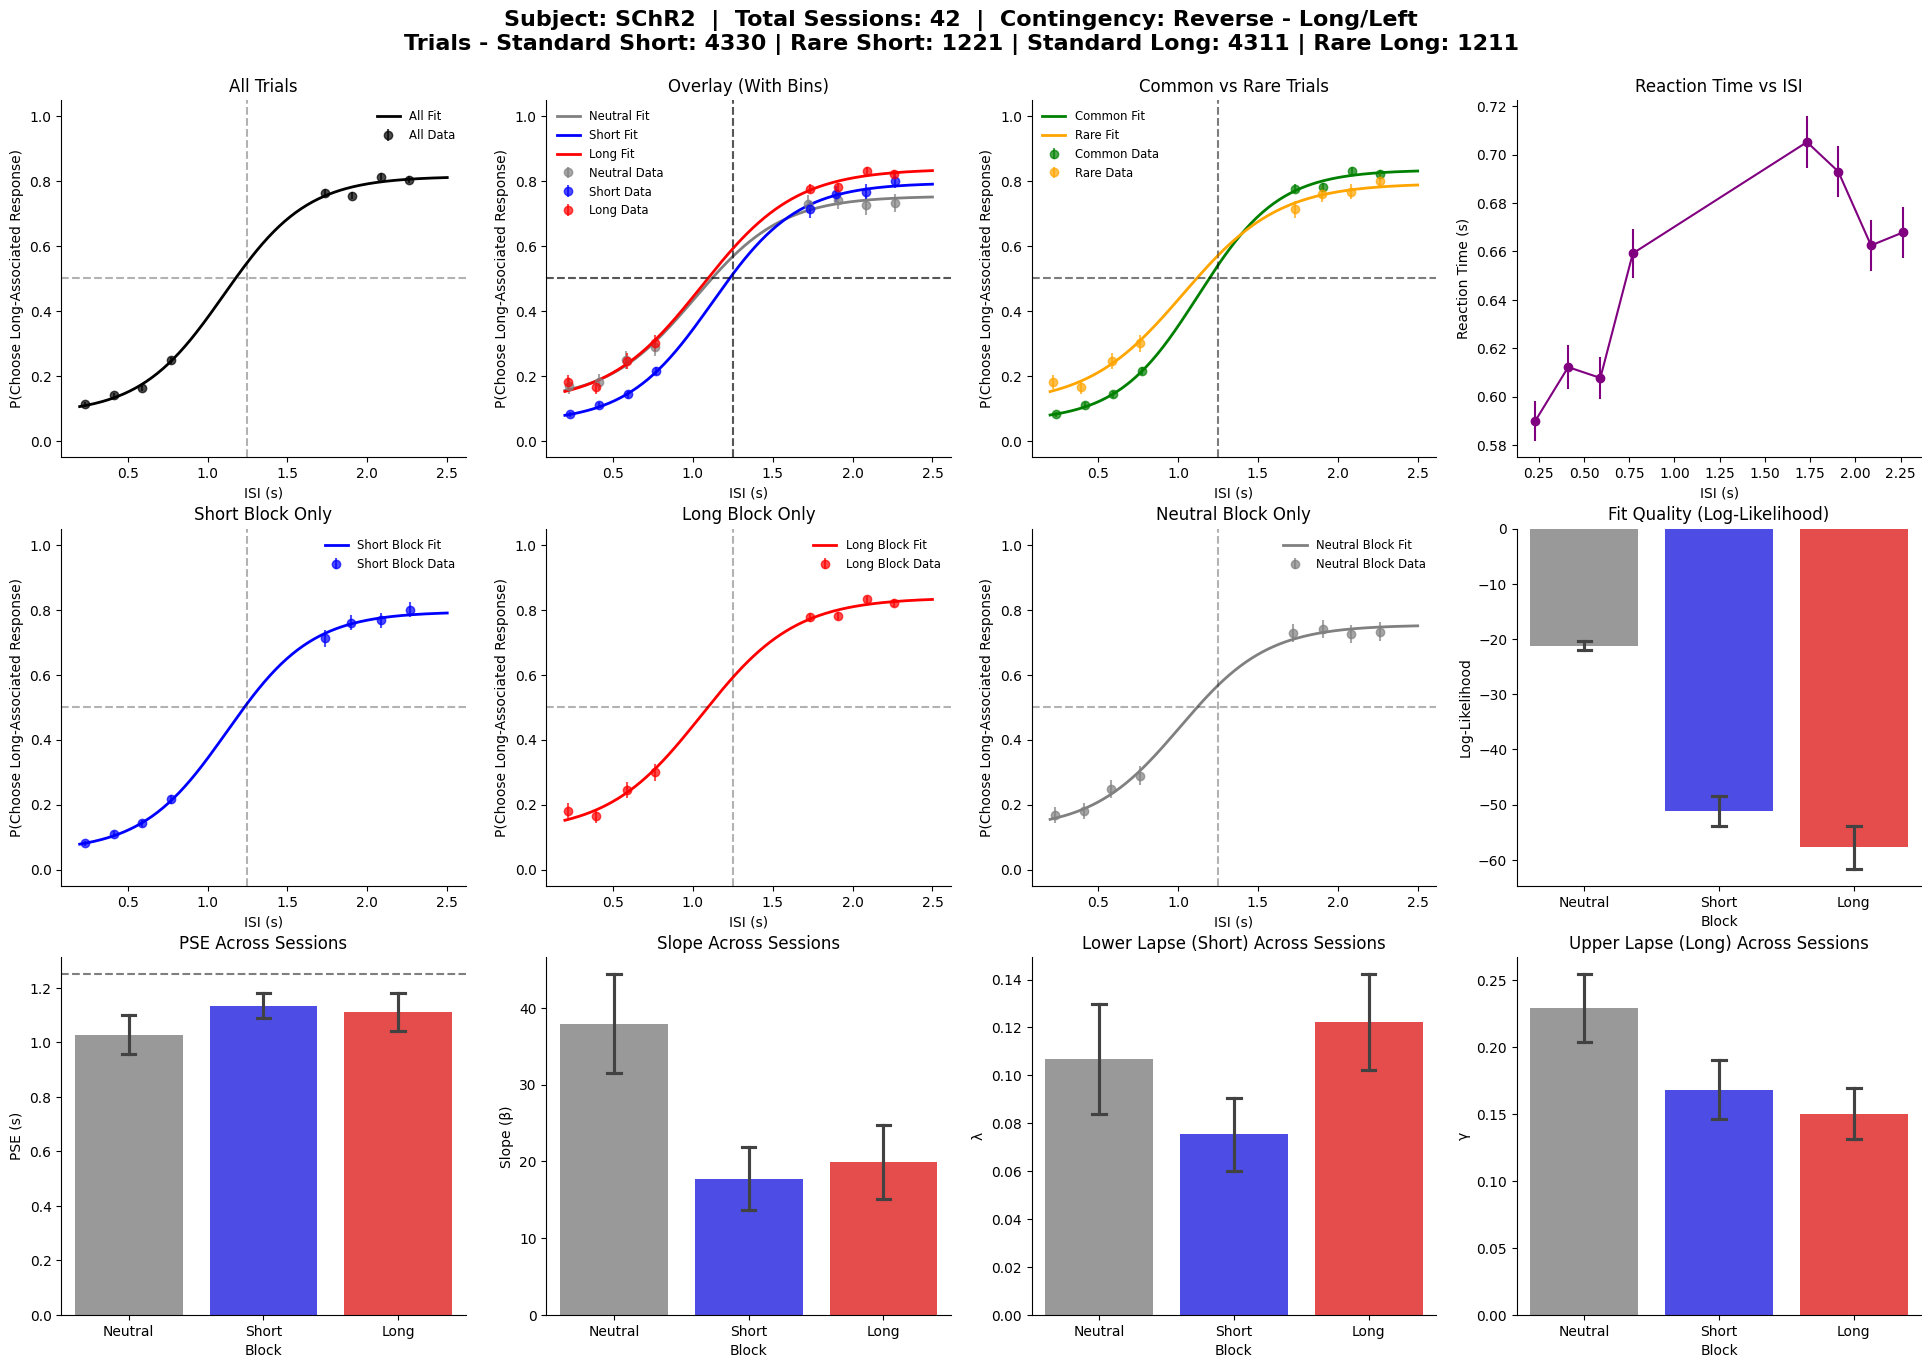

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.optimize import curve_fit
import seaborn as sns
import warnings
import os
import ast

warnings.filterwarnings('ignore')
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["text.usetex"] = False
plt.rcParams["savefig.dpi"] = 600

def logist(x, alpha, beta, lam, gamma):
    return lam + (1 - lam - gamma) / (1 + np.exp(-beta * (x - alpha)))

def fit_data(data):
    if len(data) < 10:
        return np.full(4, np.nan), np.full(4, np.nan), np.nan
    x = data['trial_isi'].values
    
    # Extract the dynamic target choice
    y = data['target_choice'].values 
    
    p0 = [1.25, 10, 0.05, 0.05]
    bounds = ([0.2, 0, 0, 0], [2.5, 100, 0.5, 0.5])
    try:
        popt, pcov = curve_fit(logist, x, y, p0=p0, bounds=bounds, maxfev=10000)
        perr = np.sqrt(np.diag(pcov)) 
        
        y_pred = logist(x, *popt)
        y_pred = np.clip(y_pred, 1e-5, 1 - 1e-5)
        ll = np.sum(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
        return popt, perr, ll
    except Exception:
        return np.full(4, np.nan), np.full(4, np.nan), np.nan

def get_binned_stats(data, n_bins_per_type=4):
    stats = []
    for tt in [1, 2]:
        tt_data = data[data['trial_type'] == tt]
        if len(tt_data) > 0:
            np.random.seed(42)
            jittered_isi = tt_data['trial_isi'] + np.random.normal(0, 1e-6, len(tt_data))
            try:
                bins = pd.qcut(jittered_isi, q=n_bins_per_type, duplicates='drop')
                for _, g in tt_data.groupby(bins, observed=False):
                    if len(g) > 0:
                        stats.append({
                            'isi_mean': g['trial_isi'].mean(),
                            'p_target': g['target_choice'].mean(), 
                            'p_se': g['target_choice'].sem() if len(g) > 1 else 0, 
                            'rt_mean': g['lick_reaction_time'].mean() if 'lick_reaction_time' in g.columns else np.nan,
                            'rt_se': g['lick_reaction_time'].sem() if 'lick_reaction_time' in g.columns and len(g)>1 else 0
                        })
            except Exception:
                pass
    if not stats: return pd.DataFrame()
    return pd.DataFrame(stats).sort_values('isi_mean')

NEGATIVE_LICK_ARRAY_COLUMNS = ['all_lick_reaction_times', 'all_lick_start_times_from_choice']


def has_negative_lick_array(value):
    if value is None:
        return False
    if isinstance(value, float) and np.isnan(value):
        return False

    if isinstance(value, str):
        text = value.strip()
        if not text or text.lower() in {'nan', 'none'}:
            return False
        try:
            values = ast.literal_eval(text)
        except (ValueError, SyntaxError):
            return False
    else:
        values = value

    if isinstance(values, (int, float, np.integer, np.floating)):
        return pd.notna(values) and float(values) < 0

    try:
        iterator = list(values)
    except TypeError:
        return False

    for item in iterator:
        if item is None:
            continue
        try:
            if pd.notna(item) and float(item) < 0:
                return True
        except (TypeError, ValueError):
            continue
    return False


def get_negative_lick_array_mask(data):
    columns = [column for column in NEGATIVE_LICK_ARRAY_COLUMNS if column in data.columns]
    if not columns:
        return pd.Series(False, index=data.index)

    mask = pd.Series(False, index=data.index)
    for column in columns:
        mask = mask | data[column].apply(has_negative_lick_array)
    return mask


def get_rt_binned_stats(data, n_bins_per_type=4):
    rt_data = data.loc[~get_negative_lick_array_mask(data)].copy()
    return get_binned_stats(rt_data, n_bins_per_type=n_bins_per_type)


def _raw_isi_fit_grid(ax, data, n_points=200):
    raw_isi = pd.to_numeric(data['trial_isi'], errors='coerce').dropna()
    if raw_isi.empty:
        return np.array([])
    data_min, data_max = float(raw_isi.min()), float(raw_isi.max())
    panel_min = min(getattr(ax, '_raw_isi_min', data_min), data_min)
    panel_max = max(getattr(ax, '_raw_isi_max', data_max), data_max)
    ax._raw_isi_min, ax._raw_isi_max = panel_min, panel_max
    if panel_min < panel_max:
        ax.set_xlim(panel_min, panel_max)
    return np.linspace(data_min, data_max, n_points) if data_min < data_max else np.array([data_min])

def plot_psycho(ax, data, popt, color, label, n_bins, y_label, plot_data=True):
    if plot_data:
        stats = get_binned_stats(data, n_bins_per_type=n_bins)
        if not stats.empty:
            ax.errorbar(stats['isi_mean'], stats['p_target'], yerr=stats['p_se'], fmt='o', color=color, alpha=0.7, label=f'{label} Data')
            
    x_fit = _raw_isi_fit_grid(ax, data)
    if len(x_fit) and not np.isnan(popt[0]):
        ax.plot(x_fit, logist(x_fit, *popt), color=color, linewidth=2, label=f'{label} Fit')
        
    ax.axvline(1.25, color='k', linestyle='--', alpha=0.3)
    ax.axhline(0.5, color='k', linestyle='--', alpha=0.3)
    ax.set_ylim(-0.05, 1.05)
    
    # Use dynamic Y-axis label based on contingency
    ax.set_ylabel(y_label)
    
    ax.set_xlabel('ISI (s)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)
    ax.legend(loc='best', frameon=False, fontsize='small')

def plot_bar_with_err(ax, df_stats, y_col, err_col, title, ylabel):
    order = ['Neutral', 'Short', 'Long']
    palette = {'Neutral': 'black', 'Short': '#BCAE3E', 'Long': 'blue'}
    if df_stats.empty: return
    
    if df_stats['session'].nunique() > 1:
        sns.barplot(data=df_stats, x='Block', y=y_col, order=order, ax=ax, palette=palette, alpha=0.8, errorbar='se', capsize=0.1)
    else:
        sns.barplot(data=df_stats, x='Block', y=y_col, order=order, ax=ax, palette=palette, alpha=0.8, errorbar=None)
        for i, block in enumerate(order):
            row = df_stats[df_stats['Block'] == block]
            if not row.empty:
                ax.errorbar(i, row[y_col].values[0], yerr=row[err_col].values[0], color='black', capsize=5, elinewidth=2)
    
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)

def main():
    csv_path = input("Enter the path to your CSV file (e.g., sample_data.csv): ").strip()
    if not os.path.exists(csv_path):
        print(f"File not found: {csv_path}. Please check the path and try again.")
        return

    n_bins_input = input("Enter the number of bins to use per trial type (e.g., 4): ").strip()
    try:
        n_bins = int(n_bins_input)
    except ValueError:
        print("Invalid number of bins provided. Defaulting to 4.")
        n_bins = 4

    save_dir = input("Enter the directory to save the figure (e.g., ./plots/): ").strip()
    if save_dir and not os.path.exists(save_dir):
        os.makedirs(save_dir)
        print(f"Created directory: {save_dir}")
    
    if save_dir and not save_dir.endswith(os.sep):
        save_dir += os.sep
        
    print("Processing data and generating figure...")

    df = pd.read_csv(csv_path) 
    df = df.dropna(subset=['lick_side'])
    df = df[df['lick_side'].isin(['Right', 'Left'])].copy()
    
    if len(df) == 0:
        print("No valid data remaining after filtering.")
        return

    # Map choices row-wise so pooled files can include normal and reverse contingencies.
    if 'Contingency' in df.columns:
        contingency_text = df['Contingency'].astype(str)
        contingencies = sorted(df['Contingency'].dropna().astype(str).unique())
    else:
        contingency_text = pd.Series('Normal - Short/Left', index=df.index)
        contingencies = ['Unknown']
    contingency = ' | '.join(contingencies) if contingencies else 'Unknown'

    normal = contingency_text.str.contains('Normal - Short/Left', na=False)
    reverse = contingency_text.str.contains('Reverse - Long/Left', na=False)
    unknown = ~(normal | reverse)
    if unknown.any():
        print(f"Warning: defaulting {unknown.sum()} unknown-contingency rows to P(Choose Right).")
        normal = normal | unknown

    df['target_choice'] = np.nan
    df.loc[normal, 'target_choice'] = (df.loc[normal, 'lick_side'] == 'Right').astype(int)
    df.loc[reverse, 'target_choice'] = (df.loc[reverse, 'lick_side'] == 'Left').astype(int)
    df = df.dropna(subset=['target_choice']).copy()
    df['target_choice'] = df['target_choice'].astype(int)
    y_label = 'P(Choose Long-Associated Response)'

    df['is_common'] = np.nan
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 1), 'is_common'] = 1
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 2), 'is_common'] = 0
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 2), 'is_common'] = 1
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 1), 'is_common'] = 0
    df['block_name'] = df['block_type'].map({0: 'Neutral', 1: 'Short', 2: 'Long'})

    # Tweak figure height up slightly to accommodate super title at top
    fig = plt.figure(figsize=(24, 15))
    
    # --------------------------------------------------------
    # EXTRACT SUMMARY STATS FOR TITLE
    # --------------------------------------------------------
    if 'subject' in df.columns:
        subjects = sorted(df['subject'].dropna().astype(str).unique())
        subject = ', '.join(subjects) if len(subjects) <= 4 else f'{len(subjects)} subjects'
    else:
        subject = "Unknown"
    n_sessions = df['session_idx'].nunique() if 'session_idx' in df.columns else 1
    
    n_std_short = len(df[(df['block_type'] == 1) & (df['is_common'] == 1)])
    n_rare_short = len(df[(df['block_type'] == 1) & (df['is_common'] == 0)])
    n_std_long = len(df[(df['block_type'] == 2) & (df['is_common'] == 1)])
    n_rare_long = len(df[(df['block_type'] == 2) & (df['is_common'] == 0)])
    
    # Add title with requested metadata mapped accurately 
    title_str = (f"Subject: {subject}  |  Total Sessions: {n_sessions}  |  Contingency: {contingency}\n"
                 f"Trials - Standard Short: {n_std_short} | Rare Short: {n_rare_short} | "
                 f"Standard Long: {n_std_long} | Rare Long: {n_rare_long}")
    fig.suptitle(title_str, fontsize=16, fontweight='bold', y=0.98)

    # Compress layout spacing down somewhat to preserve super title room
    gs = gridspec.GridSpec(3, 4, figure=fig, top=0.92)

    # --- ROW 0 ---
    popt_all, _, _ = fit_data(df)
    ax0 = fig.add_subplot(gs[0, 0])
    plot_psycho(ax0, df, popt_all, 'black', 'All', n_bins, y_label)
    ax0.set_title('All Trials')

    popt_n, _, _ = fit_data(df[df['block_type']==0])
    popt_s, _, _ = fit_data(df[df['block_type']==1])
    popt_l, _, _ = fit_data(df[df['block_type']==2])
    ax1 = fig.add_subplot(gs[0, 1])
    plot_psycho(ax1, df[df['block_type']==0], popt_n, 'black', 'Neutral', n_bins, y_label)
    plot_psycho(ax1, df[df['block_type']==1], popt_s, '#BCAE3E', 'Short', n_bins, y_label)
    plot_psycho(ax1, df[df['block_type']==2], popt_l, 'blue', 'Long', n_bins, y_label)
    ax1.set_title('Overlay (With Bins)')

    ax2 = fig.add_subplot(gs[0, 2])
    popt_com, _, _ = fit_data(df[df['is_common']==1])
    popt_rare, _, _ = fit_data(df[df['is_common']==0])
    plot_psycho(ax2, df[df['is_common']==1], popt_com, 'green', 'Common', n_bins, y_label)
    plot_psycho(ax2, df[df['is_common']==0], popt_rare, 'orange', 'Rare', n_bins, y_label)
    ax2.set_title('Common vs Rare Trials')

    ax3 = fig.add_subplot(gs[0, 3])
    stats_all = get_rt_binned_stats(df, n_bins)
    if not stats_all.empty and not stats_all['rt_mean'].isna().all():
        ax3.errorbar(stats_all['isi_mean'], stats_all['rt_mean'], yerr=stats_all['rt_se'], fmt='o-', color='purple')
    ax3.set_ylabel('Reaction Time (s)')
    ax3.set_xlabel('ISI (s)')
    ax3.set_title('Reaction Time vs ISI')
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)
    ax3.grid(False)

    # --- ROW 1 ---
    ax4 = fig.add_subplot(gs[1, 0])
    plot_psycho(ax4, df[df['block_type']==1], popt_s, '#BCAE3E', 'Short Block', n_bins, y_label)
    ax4.set_title('Short Block Only')

    ax5 = fig.add_subplot(gs[1, 1])
    plot_psycho(ax5, df[df['block_type']==2], popt_l, 'blue', 'Long Block', n_bins, y_label)
    ax5.set_title('Long Block Only')

    ax6 = fig.add_subplot(gs[1, 2])
    plot_psycho(ax6, df[df['block_type']==0], popt_n, 'black', 'Neutral Block', n_bins, y_label)
    ax6.set_title('Neutral Block Only')

    # --- ROW 2: CROSS-SESSION STATS ---
    session_res = []
    for sess in df['session_idx'].unique():
        sess_data = df[df['session_idx'] == sess]
        for bt, bname in zip([0, 1, 2], ['Neutral', 'Short', 'Long']):
            b_data = sess_data[sess_data['block_type'] == bt]
            p_opt, p_err, ll = fit_data(b_data)
            if not np.isnan(p_opt[0]):
                session_res.append({
                    'session': sess, 'Block': bname,
                    'PSE': p_opt[0], 'PSE_err': p_err[0],
                    'Slope': p_opt[1], 'Slope_err': p_err[1],
                    'Lam': p_opt[2], 'Lam_err': p_err[2],
                    'Gam': p_opt[3], 'Gam_err': p_err[3],
                    'LogLikelihood': ll
                })
    sdf = pd.DataFrame(session_res)

    ax7 = fig.add_subplot(gs[1, 3])
    plot_bar_with_err(ax7, sdf, 'LogLikelihood', 'PSE_err', 'Fit Quality (Log-Likelihood)', 'Log-Likelihood')

    ax8 = fig.add_subplot(gs[2, 0])
    plot_bar_with_err(ax8, sdf, 'PSE', 'PSE_err', 'PSE Across Sessions', 'PSE (s)')
    ax8.axhline(1.25, color='k', linestyle='--', alpha=0.5, label='Boundary')

    ax9 = fig.add_subplot(gs[2, 1])
    plot_bar_with_err(ax9, sdf, 'Slope', 'Slope_err', 'Slope Across Sessions', 'Slope (β)')

    ax10 = fig.add_subplot(gs[2, 2])
    plot_bar_with_err(ax10, sdf, 'Lam', 'Lam_err', 'Lower Lapse (Short) Across Sessions', 'λ')

    ax11 = fig.add_subplot(gs[2, 3])
    plot_bar_with_err(ax11, sdf, 'Gam', 'Gam_err', 'Upper Lapse (Long) Across Sessions', 'γ')

    # plt.tight_layout() # Omitted due to gridspec managing spacing with Suptitle 
    save_path = os.path.join(save_dir, 'reverse_pooled_psychometrics.pdf')
    plt.savefig(save_path, dpi=600, bbox_inches='tight')
    print(f"Done! Figure saved to {save_path}")
    plt.show()

if __name__ == '__main__':
    main()

# Early vs Late

Invalid number of bins provided. Defaulting to 4.
Processing data and generating Early vs Late figure...
Done! Figure saved to early_late_block_analysis.png


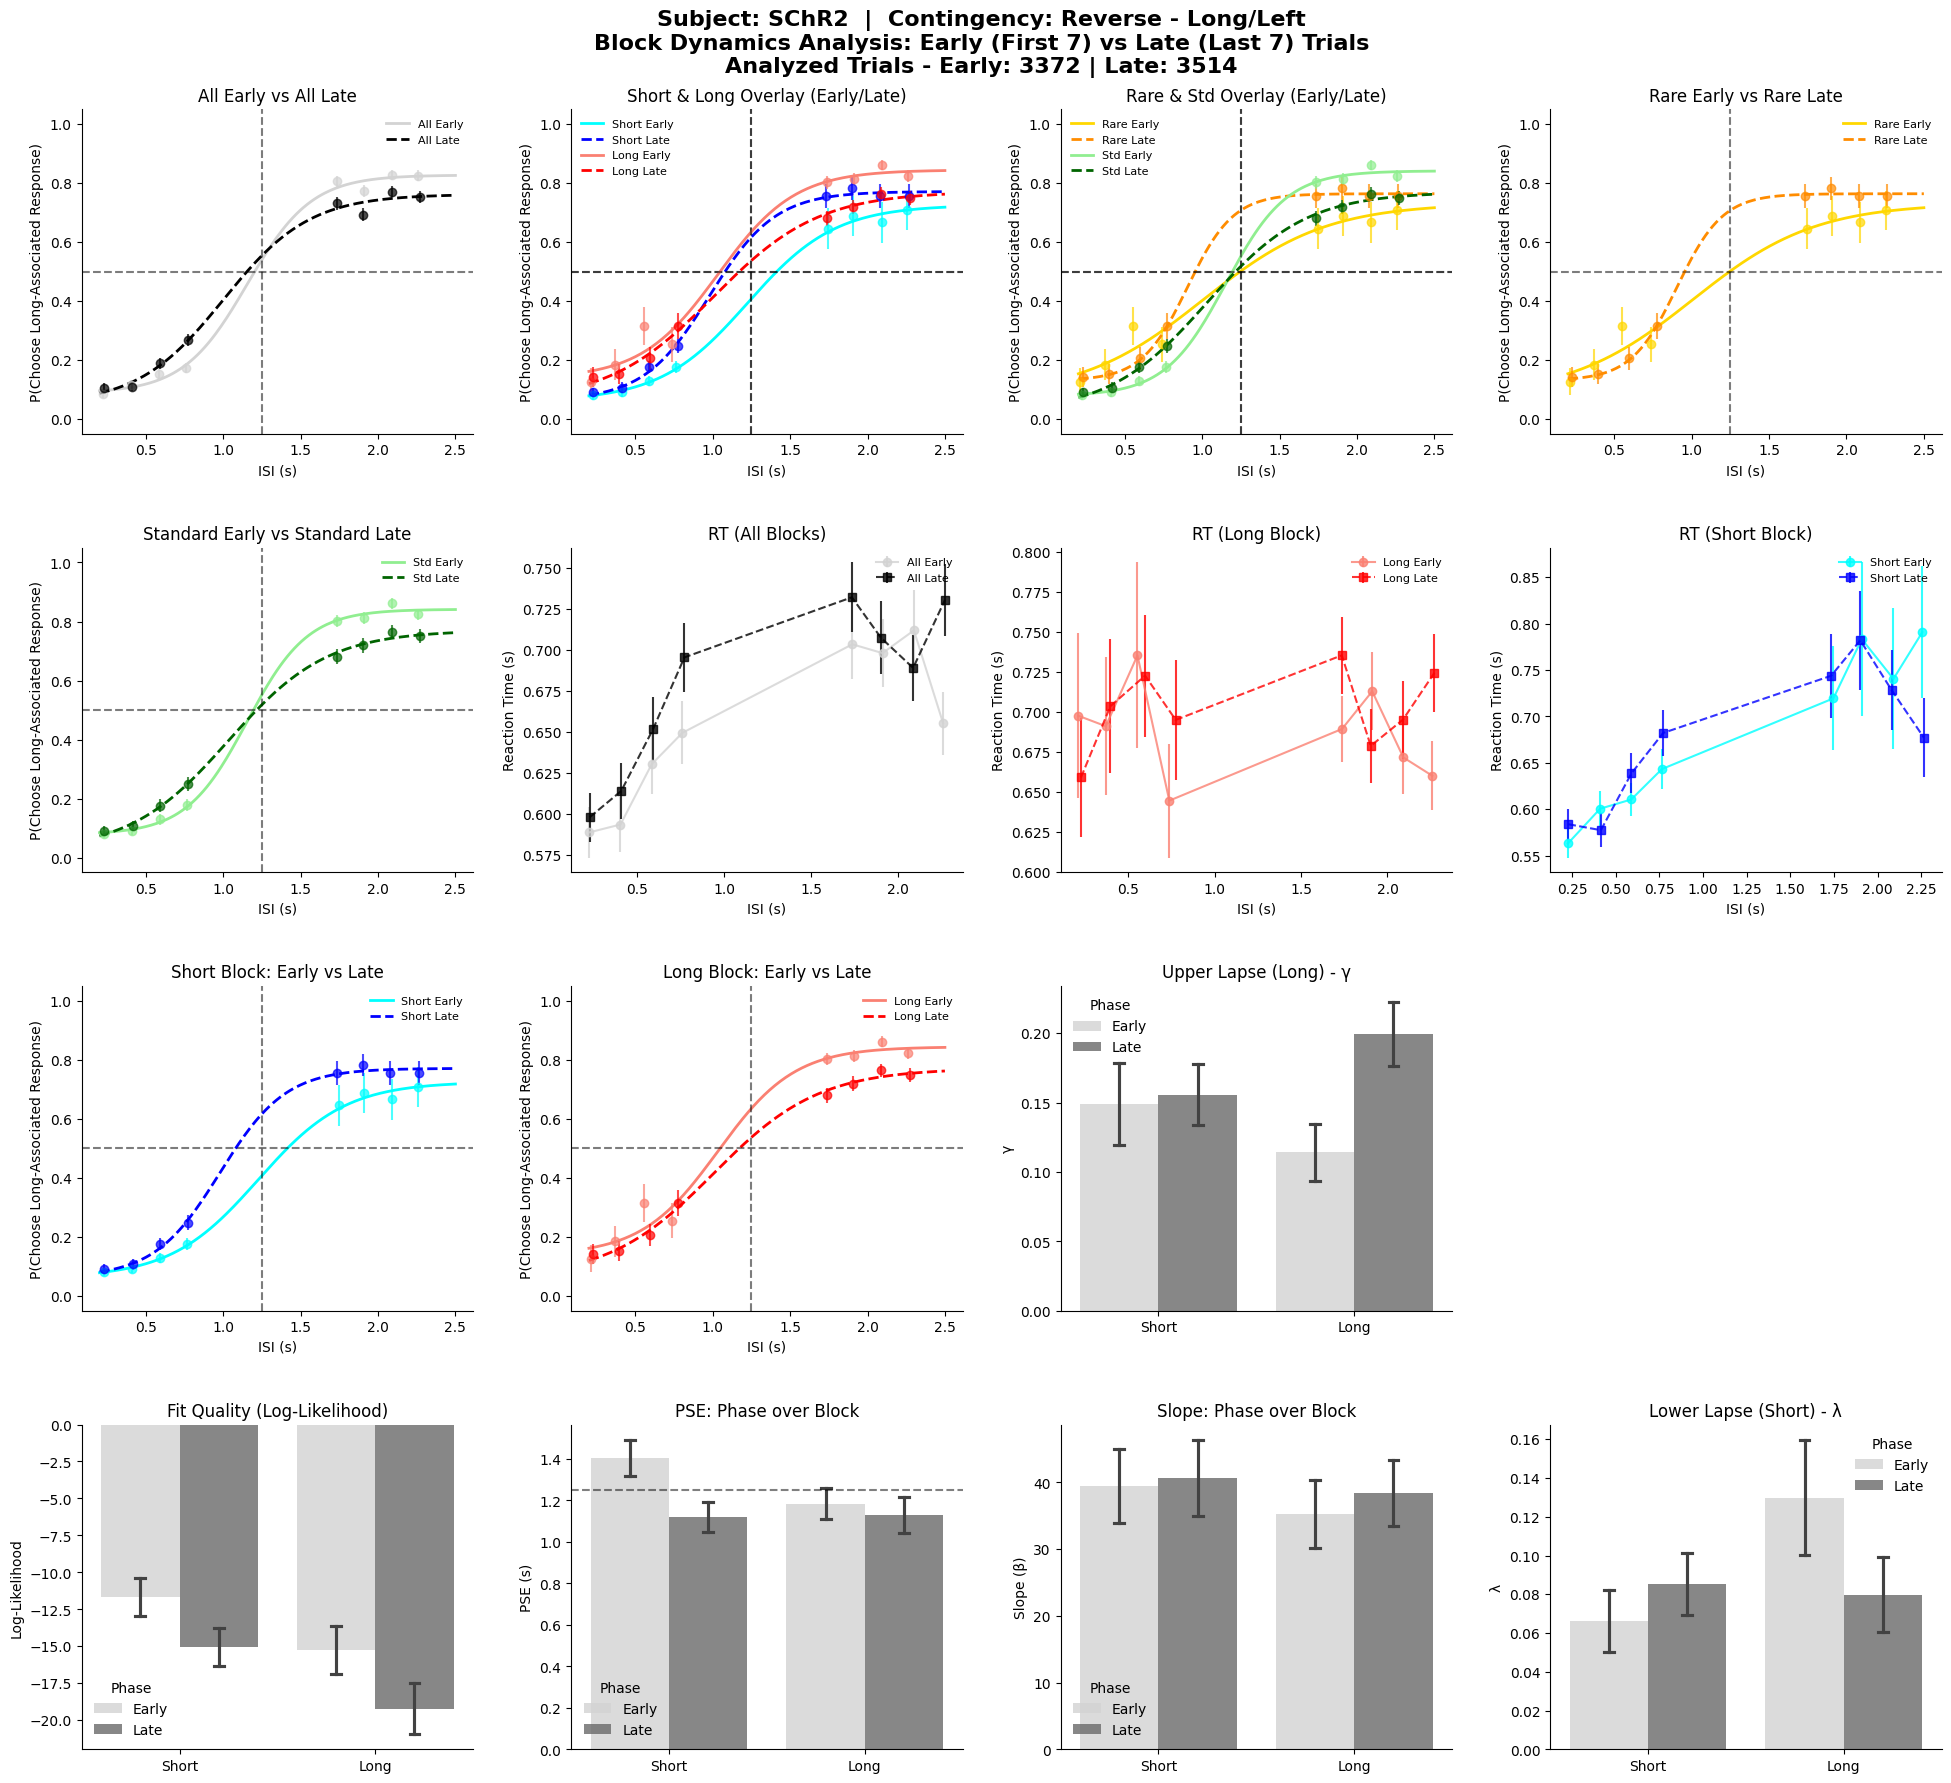

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.optimize import curve_fit
import seaborn as sns
import warnings
import os
import ast

warnings.filterwarnings('ignore')

def logist(x, alpha, beta, lam, gamma):
    return lam + (1 - lam - gamma) / (1 + np.exp(-beta * (x - alpha)))

def fit_data(data):
    # Reduced threshold slightly since split blocks have fewer trials
    if len(data) < 5: 
        return np.full(4, np.nan), np.full(4, np.nan), np.nan
    x = data['trial_isi'].values
    y = data['target_choice'].values 
    
    p0 = [1.25, 10, 0.05, 0.05]
    bounds = ([0.2, 0, 0, 0], [2.5, 100, 0.5, 0.5])
    try:
        popt, pcov = curve_fit(logist, x, y, p0=p0, bounds=bounds, maxfev=10000)
        perr = np.sqrt(np.diag(pcov)) 
        
        y_pred = logist(x, *popt)
        y_pred = np.clip(y_pred, 1e-5, 1 - 1e-5)
        ll = np.sum(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
        return popt, perr, ll
    except Exception:
        return np.full(4, np.nan), np.full(4, np.nan), np.nan

def get_binned_stats(data, n_bins_per_type=4):
    stats = []
    for tt in [1, 2]:
        tt_data = data[data['trial_type'] == tt]
        if len(tt_data) > 0:
            np.random.seed(42) # Ensure reproducible binning
            jittered_isi = tt_data['trial_isi'] + np.random.normal(0, 1e-6, len(tt_data))
            try:
                # Use qcut but fallback to cut if not enough unique values
                bins = pd.qcut(jittered_isi, q=min(n_bins_per_type, len(tt_data)), duplicates='drop')
                for _, g in tt_data.groupby(bins, observed=False):
                    if len(g) > 0:
                        stats.append({
                            'isi_mean': g['trial_isi'].mean(),
                            'p_target': g['target_choice'].mean(), 
                            'p_se': g['target_choice'].sem() if len(g) > 1 else 0, 
                            'rt_mean': g['lick_reaction_time'].mean() if 'lick_reaction_time' in g.columns else np.nan,
                            'rt_se': g['lick_reaction_time'].sem() if 'lick_reaction_time' in g.columns and len(g)>1 else 0
                        })
            except Exception:
                pass
    if not stats: return pd.DataFrame()
    return pd.DataFrame(stats).sort_values('isi_mean')

NEGATIVE_LICK_ARRAY_COLUMNS = ['all_lick_reaction_times', 'all_lick_start_times_from_choice']


def has_negative_lick_array(value):
    if value is None:
        return False
    if isinstance(value, float) and np.isnan(value):
        return False

    if isinstance(value, str):
        text = value.strip()
        if not text or text.lower() in {'nan', 'none'}:
            return False
        try:
            values = ast.literal_eval(text)
        except (ValueError, SyntaxError):
            return False
    else:
        values = value

    if isinstance(values, (int, float, np.integer, np.floating)):
        return pd.notna(values) and float(values) < 0

    try:
        iterator = list(values)
    except TypeError:
        return False

    for item in iterator:
        if item is None:
            continue
        try:
            if pd.notna(item) and float(item) < 0:
                return True
        except (TypeError, ValueError):
            continue
    return False


def get_negative_lick_array_mask(data):
    columns = [column for column in NEGATIVE_LICK_ARRAY_COLUMNS if column in data.columns]
    if not columns:
        return pd.Series(False, index=data.index)

    mask = pd.Series(False, index=data.index)
    for column in columns:
        mask = mask | data[column].apply(has_negative_lick_array)
    return mask


def get_rt_binned_stats(data, n_bins_per_type=4):
    rt_data = data.loc[~get_negative_lick_array_mask(data)].copy()
    return get_binned_stats(rt_data, n_bins_per_type=n_bins_per_type)


def _raw_isi_fit_grid(ax, data, n_points=200):
    raw_isi = pd.to_numeric(data['trial_isi'], errors='coerce').dropna()
    if raw_isi.empty:
        return np.array([])
    data_min, data_max = float(raw_isi.min()), float(raw_isi.max())
    panel_min = min(getattr(ax, '_raw_isi_min', data_min), data_min)
    panel_max = max(getattr(ax, '_raw_isi_max', data_max), data_max)
    ax._raw_isi_min, ax._raw_isi_max = panel_min, panel_max
    if panel_min < panel_max:
        ax.set_xlim(panel_min, panel_max)
    return np.linspace(data_min, data_max, n_points) if data_min < data_max else np.array([data_min])

def plot_psycho(ax, data, popt, color, label, n_bins, y_label, plot_data=True, linestyle='-'):
    if plot_data:
        stats = get_binned_stats(data, n_bins_per_type=n_bins)
        if not stats.empty:
            ax.errorbar(stats['isi_mean'], stats['p_target'], yerr=stats['p_se'], fmt='o', color=color, alpha=0.7)
            
    x_fit = _raw_isi_fit_grid(ax, data)
    if len(x_fit) and not np.isnan(popt[0]):
        ax.plot(x_fit, logist(x_fit, *popt), color=color, linewidth=2, linestyle=linestyle, label=f'{label}')
        
    ax.axvline(1.25, color='k', linestyle='--', alpha=0.3)
    ax.axhline(0.5, color='k', linestyle='--', alpha=0.3)
    ax.set_ylim(-0.05, 1.05)
    ax.set_ylabel(y_label)
    ax.set_xlabel('ISI (s)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)
    ax.legend(loc='best', frameon=False, fontsize='8')

def plot_rt(ax, d_early, c_early, l_early, d_late, c_late, l_late, title, n_bins):
    s_early = get_rt_binned_stats(d_early, n_bins)
    s_late = get_rt_binned_stats(d_late, n_bins)
    
    if not s_early.empty and not s_early['rt_mean'].isna().all():
        ax.errorbar(s_early['isi_mean'], s_early['rt_mean'], yerr=s_early['rt_se'], fmt='o-', color=c_early, label=l_early, alpha=0.8)
    if not s_late.empty and not s_late['rt_mean'].isna().all():
        ax.errorbar(s_late['isi_mean'], s_late['rt_mean'], yerr=s_late['rt_se'], fmt='s--', color=c_late, label=l_late, alpha=0.8)
        
    ax.set_ylabel('Reaction Time (s)')
    ax.set_xlabel('ISI (s)')
    ax.set_title(title)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(loc='best', frameon=False, fontsize='8')
    ax.grid(False)

def plot_grouped_bar(ax, df_stats, y_col, title, ylabel):
    if df_stats.empty: return
    # Order so Short and Long form distinct groups on the x-axis, separated nicely by hue
    sns.barplot(data=df_stats, x='Block', y=y_col, hue='Phase', 
                hue_order=['Early', 'Late'], order=['Short', 'Long'], 
                palette={'Early': 'lightgray', 'Late': 'dimgray'}, 
                ax=ax, alpha=0.8, errorbar='se', capsize=0.1)
    
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(title='Phase', frameon=False, loc='best')

def main():
    csv_path = input("Enter the path to your CSV file (e.g., sample_data.csv): ").strip()
    if not os.path.exists(csv_path):
        print(f"File not found: {csv_path}. Please check the path and try again.")
        return

    # --- ADDED: Interactive n_bins logic back in ---
    n_bins_input = input("Enter the number of bins to use per trial type (e.g., 4): ").strip()
    try:
        n_bins = int(n_bins_input)
    except ValueError:
        print("Invalid number of bins provided. Defaulting to 4.")
        n_bins = 4

    save_dir = input("Enter the directory to save the figure (e.g., ./plots/): ").strip()
    if save_dir and not os.path.exists(save_dir):
        os.makedirs(save_dir)
        print(f"Created directory: {save_dir}")
    
    if save_dir and not save_dir.endswith(os.sep):
        save_dir += os.sep
        
    print("Processing data and generating Early vs Late figure...")

    df = pd.read_csv(csv_path) 
    df = df.dropna(subset=['lick_side'])
    df = df[df['lick_side'].isin(['Right', 'Left'])].copy()
    
    if len(df) == 0:
        print("No valid data remaining after filtering.")
        return

    # Map choices row-wise so pooled files can include normal and reverse contingencies.
    if 'Contingency' in df.columns:
        contingency_text = df['Contingency'].astype(str)
        contingencies = sorted(df['Contingency'].dropna().astype(str).unique())
    else:
        contingency_text = pd.Series('Normal - Short/Left', index=df.index)
        contingencies = ['Unknown']
    contingency = ' | '.join(contingencies) if contingencies else 'Unknown'

    normal = contingency_text.str.contains('Normal - Short/Left', na=False)
    reverse = contingency_text.str.contains('Reverse - Long/Left', na=False)
    unknown = ~(normal | reverse)
    if unknown.any():
        print(f"Warning: defaulting {unknown.sum()} unknown-contingency rows to P(Choose Right).")
        normal = normal | unknown

    df['target_choice'] = np.nan
    df.loc[normal, 'target_choice'] = (df.loc[normal, 'lick_side'] == 'Right').astype(int)
    df.loc[reverse, 'target_choice'] = (df.loc[reverse, 'lick_side'] == 'Left').astype(int)
    df = df.dropna(subset=['target_choice']).copy()
    df['target_choice'] = df['target_choice'].astype(int)
    y_label = 'P(Choose Long-Associated Response)'

    # Standard / Rare Mapping
    df['is_common'] = np.nan
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 1), 'is_common'] = 1
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 2), 'is_common'] = 0
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 2), 'is_common'] = 1
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 1), 'is_common'] = 0

    # Group by Continuous Blocks to tag Early vs Late
    df['block_instance'] = (df['block_type'] != df['block_type'].shift(1)).cumsum()
    df['Phase'] = pd.Series(pd.NA, index=df.index, dtype='object')

    for _, group in df.groupby('block_instance'):
        # Only tag if block belongs to Short(1) or Long(2) to exclude Neutral from Phase metrics
        if group['block_type'].iloc[0] in [1, 2]:
            df.loc[group.head(7).index, 'Phase'] = 'Early'
            df.loc[group.tail(7).index, 'Phase'] = 'Late'

    fig = plt.figure(figsize=(24, 20))
    
    # Generate Titling Metdata 
    if 'subject' in df.columns:
        subjects = sorted(df['subject'].dropna().astype(str).unique())
        subject = ', '.join(subjects) if len(subjects) <= 4 else f'{len(subjects)} subjects'
    else:
        subject = "Unknown"
    n_early = len(df[df['Phase'] == 'Early'])
    n_late = len(df[df['Phase'] == 'Late'])
    
    fig.suptitle(f"Subject: {subject}  |  Contingency: {contingency}\n"
                 f"Block Dynamics Analysis: Early (First 7) vs Late (Last 7) Trials\n"
                 f"Analyzed Trials - Early: {n_early} | Late: {n_late}", 
                 fontsize=16, fontweight='bold', y=0.98)

    gs = gridspec.GridSpec(4, 4, figure=fig, top=0.93, hspace=0.35, wspace=0.25)

    # Useful filtered subsets
    df_early = df[df['Phase'] == 'Early']
    df_late  = df[df['Phase'] == 'Late']

    # --- ROW 0: Psychometrics ---
    # Plot 1: All Early vs All Late
    ax1 = fig.add_subplot(gs[0, 0])
    pe, _, _ = fit_data(df_early)
    pl, _, _ = fit_data(df_late)
    plot_psycho(ax1, df_early, pe, 'lightgray', 'All Early', n_bins, y_label)
    plot_psycho(ax1, df_late, pl, 'black', 'All Late', n_bins, y_label, linestyle='--')
    ax1.set_title('All Early vs All Late')

    # Plot 2: Overlay Short & Long (Early & Late)
    ax2 = fig.add_subplot(gs[0, 1])
    pe_s, _, _ = fit_data(df_early[df_early['block_type']==1])
    pl_s, _, _ = fit_data(df_late[df_late['block_type']==1])
    pe_l, _, _ = fit_data(df_early[df_early['block_type']==2])
    pl_l, _, _ = fit_data(df_late[df_late['block_type']==2])
    plot_psycho(ax2, df_early[df_early['block_type']==1], pe_s, '#BCAE3E', 'Short Early', n_bins, y_label)
    plot_psycho(ax2, df_late[df_late['block_type']==1], pl_s, '#BCAE3E', 'Short Late', n_bins, y_label, linestyle='--')
    plot_psycho(ax2, df_early[df_early['block_type']==2], pe_l, 'blue', 'Long Early', n_bins, y_label)
    plot_psycho(ax2, df_late[df_late['block_type']==2], pl_l, 'blue', 'Long Late', n_bins, y_label, linestyle='--')
    ax2.set_title('Short & Long Overlay (Early/Late)')

    # Plot 3: Rare vs Std (All Early/Late)
    ax3 = fig.add_subplot(gs[0, 2])
    pe_r, _, _ = fit_data(df_early[df_early['is_common']==0])
    pl_r, _, _ = fit_data(df_late[df_late['is_common']==0])
    pe_std, _, _ = fit_data(df_early[df_early['is_common']==1])
    pl_std, _, _ = fit_data(df_late[df_late['is_common']==1])
    plot_psycho(ax3, df_early[df_early['is_common']==0], pe_r, 'gold', 'Rare Early', n_bins, y_label)
    plot_psycho(ax3, df_late[df_late['is_common']==0], pl_r, 'darkorange', 'Rare Late', n_bins, y_label, linestyle='--')
    plot_psycho(ax3, df_early[df_early['is_common']==1], pe_std, 'lightgreen', 'Std Early', n_bins, y_label)
    plot_psycho(ax3, df_late[df_late['is_common']==1], pl_std, 'darkgreen', 'Std Late', n_bins, y_label, linestyle='--')
    ax3.set_title('Rare & Std Overlay (Early/Late)')

    # Plot 4: Rare Early vs Late only
    ax4 = fig.add_subplot(gs[0, 3])
    plot_psycho(ax4, df_early[df_early['is_common']==0], pe_r, 'gold', 'Rare Early', n_bins, y_label)
    plot_psycho(ax4, df_late[df_late['is_common']==0], pl_r, 'darkorange', 'Rare Late', n_bins, y_label, linestyle='--')
    ax4.set_title('Rare Early vs Rare Late')

    # --- ROW 1: Standard Psycho & RTs ---
    # Plot 5: Std Early vs Late only
    ax5 = fig.add_subplot(gs[1, 0])
    plot_psycho(ax5, df_early[df_early['is_common']==1], pe_std, 'lightgreen', 'Std Early', n_bins, y_label)
    plot_psycho(ax5, df_late[df_late['is_common']==1], pl_std, 'darkgreen', 'Std Late', n_bins, y_label, linestyle='--')
    ax5.set_title('Standard Early vs Standard Late')

    # Plot 6: RT All Early vs Late
    ax6 = fig.add_subplot(gs[1, 1])
    plot_rt(ax6, df_early, 'lightgray', 'All Early', df_late, 'black', 'All Late', 'RT (All Blocks)', n_bins)

    # Plot 7: RT Long Early vs Late
    ax7 = fig.add_subplot(gs[1, 2])
    plot_rt(ax7, df_early[df_early['block_type']==2], 'blue', 'Long Early', 
            df_late[df_late['block_type']==2], 'blue', 'Long Late', 'RT (Long Block)', n_bins)

    # Plot 8: RT Short Early vs Late
    ax8 = fig.add_subplot(gs[1, 3])
    plot_rt(ax8, df_early[df_early['block_type']==1], '#BCAE3E', 'Short Early', 
            df_late[df_late['block_type']==1], '#BCAE3E', 'Short Late', 'RT (Short Block)', n_bins)

    # --- ROW 2: Specific Block Psychometrics ---
    # Plot 9: Short Block Psycho
    ax9 = fig.add_subplot(gs[2, 0])
    plot_psycho(ax9, df_early[df_early['block_type']==1], pe_s, '#BCAE3E', 'Short Early', n_bins, y_label)
    plot_psycho(ax9, df_late[df_late['block_type']==1], pl_s, '#BCAE3E', 'Short Late', n_bins, y_label, linestyle='--')
    ax9.set_title('Short Block: Early vs Late')

    # Plot 10: Long Block Psycho
    ax10 = fig.add_subplot(gs[2, 1])
    plot_psycho(ax10, df_early[df_early['block_type']==2], pe_l, 'blue', 'Long Early', n_bins, y_label)
    plot_psycho(ax10, df_late[df_late['block_type']==2], pl_l, 'blue', 'Long Late', n_bins, y_label, linestyle='--')
    ax10.set_title('Long Block: Early vs Late')

    # --- ROW 3: Parameter Metrics (Grouped Bar Plots) ---
    session_res = []
    # Calculate for each unique session index
    for sess in df['session_idx'].unique():
        sess_data = df[df['session_idx'] == sess]
        for phase in ['Early', 'Late']:
            ph_data = sess_data[sess_data['Phase'] == phase]
            for bt, bname in zip([1, 2], ['Short', 'Long']):
                b_data = ph_data[ph_data['block_type'] == bt]
                p_opt, _, ll = fit_data(b_data)
                
                # Only save if model successfully fit
                if not np.isnan(p_opt[0]):
                    session_res.append({
                        'session': sess, 'Block': bname, 'Phase': phase,
                        'PSE': p_opt[0], 'Slope': p_opt[1], 
                        'Lam': p_opt[2], 'Gam': p_opt[3], 'LogLikelihood': ll
                    })
                    
    sdf = pd.DataFrame(session_res)

    ax11 = fig.add_subplot(gs[3, 0])
    plot_grouped_bar(ax11, sdf, 'LogLikelihood', 'Fit Quality (Log-Likelihood)', 'Log-Likelihood')

    ax12 = fig.add_subplot(gs[3, 1])
    plot_grouped_bar(ax12, sdf, 'PSE', 'PSE: Phase over Block', 'PSE (s)')
    ax12.axhline(1.25, color='k', linestyle='--', alpha=0.5) # Add 1.25 boundary

    ax13 = fig.add_subplot(gs[3, 2])
    plot_grouped_bar(ax13, sdf, 'Slope', 'Slope: Phase over Block', 'Slope (β)')

    # Shared axis for Lapses 
    ax14 = fig.add_subplot(gs[3, 3])
    plot_grouped_bar(ax14, sdf, 'Lam', 'Lower Lapse (Short) - λ', 'λ')

    ax15 = fig.add_subplot(gs[2, 2])
    plot_grouped_bar(ax15, sdf, 'Gam', 'Upper Lapse (Long) - γ', 'γ')

    save_path = os.path.join(save_dir, 'early_late_block_analysis.pdf')
    plt.savefig(save_path, dpi=600, bbox_inches='tight')
    print(f"Done! Figure saved to {save_path}")
    plt.show()

if __name__ == '__main__':
    main()

## Bootstrapping


Invalid number of bins provided. Defaulting to 4.
Processing data and generating Early vs Late figure...
Done! Figure saved to early_late_block_analysis_balanced.png


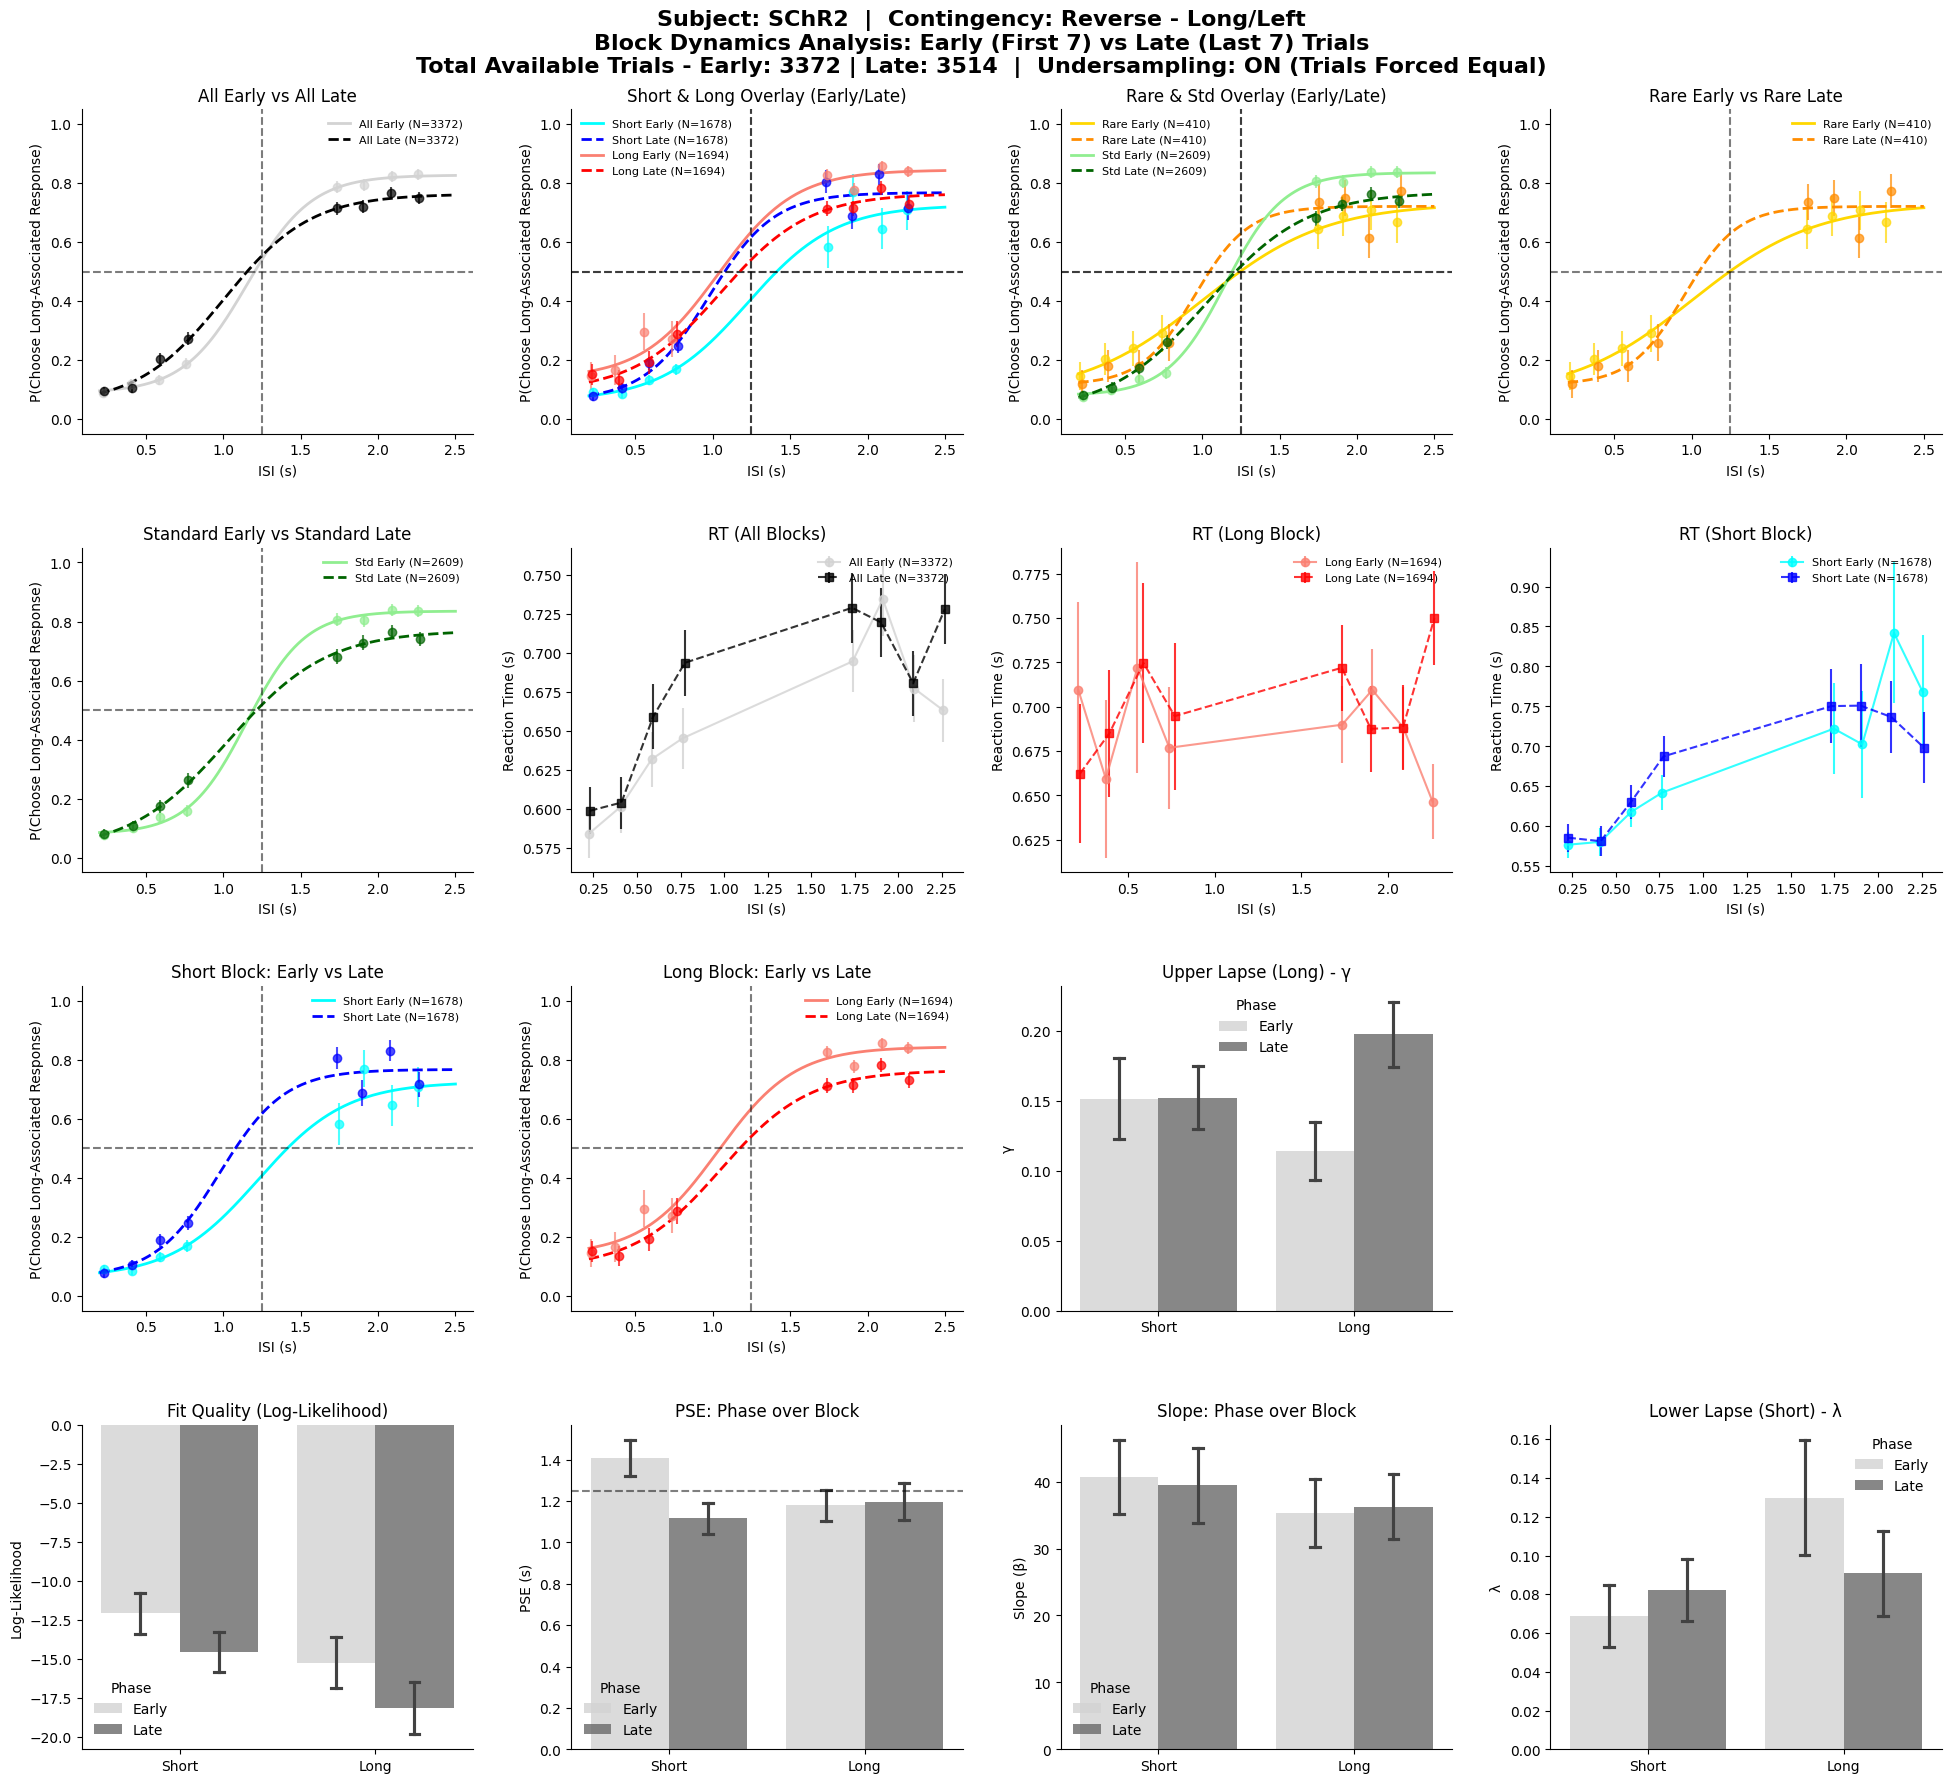

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.optimize import curve_fit
import seaborn as sns
import warnings
import os
import ast

warnings.filterwarnings('ignore')

# ==========================================
# SETTING: Toggle Data Balancing On or Off
# ==========================================
USE_UNDERSAMPLING = True  # Set to False to return to normal weighting
# ==========================================

def logist(x, alpha, beta, lam, gamma):
    return lam + (1 - lam - gamma) / (1 + np.exp(-beta * (x - alpha)))

def balance_datasets(df1, df2, seed=42):
    """
    Finds the smaller of the two dataframes and randomly downsamples 
    the larger dataframe to match its exact size.
    """
    if not USE_UNDERSAMPLING:
        return df1, df2
        
    min_len = min(len(df1), len(df2))
    
    # If one of the groups has 0 trials, return empty dataframes to prevent crashes
    if min_len == 0:
        return df1.iloc[0:0], df2.iloc[0:0]
        
    # Randomly sample 'min_len' trials from both to ensure perfect balance
    df1_balanced = df1.sample(n=min_len, random_state=seed)
    df2_balanced = df2.sample(n=min_len, random_state=seed)
    
    return df1_balanced, df2_balanced

def fit_data(data):
    if len(data) < 5: 
        return np.full(4, np.nan), np.full(4, np.nan), np.nan
    x = data['trial_isi'].values
    y = data['target_choice'].values 
    
    p0 = [1.25, 10, 0.05, 0.05]
    bounds = ([0.2, 0, 0, 0], [2.5, 100, 0.5, 0.5])
    try:
        popt, pcov = curve_fit(logist, x, y, p0=p0, bounds=bounds, maxfev=10000)
        perr = np.sqrt(np.diag(pcov)) 
        
        y_pred = logist(x, *popt)
        y_pred = np.clip(y_pred, 1e-5, 1 - 1e-5)
        ll = np.sum(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
        return popt, perr, ll
    except Exception:
        return np.full(4, np.nan), np.full(4, np.nan), np.nan

def get_binned_stats(data, n_bins_per_type=4):
    stats = []
    for tt in [1, 2]:
        tt_data = data[data['trial_type'] == tt]
        if len(tt_data) > 0:
            np.random.seed(42) 
            jittered_isi = tt_data['trial_isi'] + np.random.normal(0, 1e-6, len(tt_data))
            try:
                bins = pd.qcut(jittered_isi, q=min(n_bins_per_type, len(tt_data)), duplicates='drop')
                for _, g in tt_data.groupby(bins, observed=False):
                    if len(g) > 0:
                        stats.append({
                            'isi_mean': g['trial_isi'].mean(),
                            'p_target': g['target_choice'].mean(), 
                            'p_se': g['target_choice'].sem() if len(g) > 1 else 0, 
                            'rt_mean': g['lick_reaction_time'].mean() if 'lick_reaction_time' in g.columns else np.nan,
                            'rt_se': g['lick_reaction_time'].sem() if 'lick_reaction_time' in g.columns and len(g)>1 else 0
                        })
            except Exception:
                pass
    if not stats: return pd.DataFrame()
    return pd.DataFrame(stats).sort_values('isi_mean')

NEGATIVE_LICK_ARRAY_COLUMNS = ['all_lick_reaction_times', 'all_lick_start_times_from_choice']


def has_negative_lick_array(value):
    if value is None:
        return False
    if isinstance(value, float) and np.isnan(value):
        return False

    if isinstance(value, str):
        text = value.strip()
        if not text or text.lower() in {'nan', 'none'}:
            return False
        try:
            values = ast.literal_eval(text)
        except (ValueError, SyntaxError):
            return False
    else:
        values = value

    if isinstance(values, (int, float, np.integer, np.floating)):
        return pd.notna(values) and float(values) < 0

    try:
        iterator = list(values)
    except TypeError:
        return False

    for item in iterator:
        if item is None:
            continue
        try:
            if pd.notna(item) and float(item) < 0:
                return True
        except (TypeError, ValueError):
            continue
    return False


def get_negative_lick_array_mask(data):
    columns = [column for column in NEGATIVE_LICK_ARRAY_COLUMNS if column in data.columns]
    if not columns:
        return pd.Series(False, index=data.index)

    mask = pd.Series(False, index=data.index)
    for column in columns:
        mask = mask | data[column].apply(has_negative_lick_array)
    return mask


def get_rt_binned_stats(data, n_bins_per_type=4):
    rt_data = data.loc[~get_negative_lick_array_mask(data)].copy()
    return get_binned_stats(rt_data, n_bins_per_type=n_bins_per_type)


def _raw_isi_fit_grid(ax, data, n_points=200):
    raw_isi = pd.to_numeric(data['trial_isi'], errors='coerce').dropna()
    if raw_isi.empty:
        return np.array([])
    data_min, data_max = float(raw_isi.min()), float(raw_isi.max())
    panel_min = min(getattr(ax, '_raw_isi_min', data_min), data_min)
    panel_max = max(getattr(ax, '_raw_isi_max', data_max), data_max)
    ax._raw_isi_min, ax._raw_isi_max = panel_min, panel_max
    if panel_min < panel_max:
        ax.set_xlim(panel_min, panel_max)
    return np.linspace(data_min, data_max, n_points) if data_min < data_max else np.array([data_min])

def plot_psycho(ax, data, popt, color, label, n_bins, y_label, plot_data=True, linestyle='-'):
    if plot_data:
        stats = get_binned_stats(data, n_bins_per_type=n_bins)
        if not stats.empty:
            ax.errorbar(stats['isi_mean'], stats['p_target'], yerr=stats['p_se'], fmt='o', color=color, alpha=0.7)
            
    x_fit = _raw_isi_fit_grid(ax, data)
    if len(x_fit) and not np.isnan(popt[0]):
        # Added N to the label so you can verify the balancing is working
        ax.plot(x_fit, logist(x_fit, *popt), color=color, linewidth=2, linestyle=linestyle, label=f'{label} (N={len(data)})')
        
    ax.axvline(1.25, color='k', linestyle='--', alpha=0.3)
    ax.axhline(0.5, color='k', linestyle='--', alpha=0.3)
    ax.set_ylim(-0.05, 1.05)
    ax.set_ylabel(y_label)
    ax.set_xlabel('ISI (s)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)
    ax.legend(loc='best', frameon=False, fontsize='8')

def plot_rt(ax, d_early, c_early, l_early, d_late, c_late, l_late, title, n_bins):
    s_early = get_rt_binned_stats(d_early, n_bins)
    s_late = get_rt_binned_stats(d_late, n_bins)
    
    if not s_early.empty and not s_early['rt_mean'].isna().all():
        ax.errorbar(s_early['isi_mean'], s_early['rt_mean'], yerr=s_early['rt_se'], fmt='o-', color=c_early, label=f"{l_early} (N={len(d_early)})", alpha=0.8)
    if not s_late.empty and not s_late['rt_mean'].isna().all():
        ax.errorbar(s_late['isi_mean'], s_late['rt_mean'], yerr=s_late['rt_se'], fmt='s--', color=c_late, label=f"{l_late} (N={len(d_late)})", alpha=0.8)
        
    ax.set_ylabel('Reaction Time (s)')
    ax.set_xlabel('ISI (s)')
    ax.set_title(title)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(loc='best', frameon=False, fontsize='8')
    ax.grid(False)

def plot_grouped_bar(ax, df_stats, y_col, title, ylabel):
    if df_stats.empty: return
    sns.barplot(data=df_stats, x='Block', y=y_col, hue='Phase', 
                hue_order=['Early', 'Late'], order=['Short', 'Long'], 
                palette={'Early': 'lightgray', 'Late': 'dimgray'}, 
                ax=ax, alpha=0.8, errorbar='se', capsize=0.1)
    
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(title='Phase', frameon=False, loc='best')

def main():
    csv_path = input("Enter the path to your CSV file (e.g., sample_data.csv): ").strip()
    if not os.path.exists(csv_path):
        print(f"File not found: {csv_path}. Please check the path and try again.")
        return

    n_bins_input = input("Enter the number of bins to use per trial type (e.g., 4): ").strip()
    try:
        n_bins = int(n_bins_input)
    except ValueError:
        print("Invalid number of bins provided. Defaulting to 4.")
        n_bins = 4

    save_dir = input("Enter the directory to save the figure (e.g., ./plots/): ").strip()
    if save_dir and not os.path.exists(save_dir):
        os.makedirs(save_dir)
        print(f"Created directory: {save_dir}")
    
    if save_dir and not save_dir.endswith(os.sep):
        save_dir += os.sep
        
    print("Processing data and generating Early vs Late figure...")

    df = pd.read_csv(csv_path) 
    df = df.dropna(subset=['lick_side'])
    df = df[df['lick_side'].isin(['Right', 'Left'])].copy()
    
    if len(df) == 0:
        print("No valid data remaining after filtering.")
        return

    # Map choices row-wise so pooled files can include normal and reverse contingencies.
    if 'Contingency' in df.columns:
        contingency_text = df['Contingency'].astype(str)
        contingencies = sorted(df['Contingency'].dropna().astype(str).unique())
    else:
        contingency_text = pd.Series('Normal - Short/Left', index=df.index)
        contingencies = ['Unknown']
    contingency = ' | '.join(contingencies) if contingencies else 'Unknown'

    normal = contingency_text.str.contains('Normal - Short/Left', na=False)
    reverse = contingency_text.str.contains('Reverse - Long/Left', na=False)
    unknown = ~(normal | reverse)
    if unknown.any():
        print(f"Warning: defaulting {unknown.sum()} unknown-contingency rows to P(Choose Right).")
        normal = normal | unknown

    df['target_choice'] = np.nan
    df.loc[normal, 'target_choice'] = (df.loc[normal, 'lick_side'] == 'Right').astype(int)
    df.loc[reverse, 'target_choice'] = (df.loc[reverse, 'lick_side'] == 'Left').astype(int)
    df = df.dropna(subset=['target_choice']).copy()
    df['target_choice'] = df['target_choice'].astype(int)
    y_label = 'P(Choose Long-Associated Response)'

    df['is_common'] = np.nan
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 1), 'is_common'] = 1
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 2), 'is_common'] = 0
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 2), 'is_common'] = 1
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 1), 'is_common'] = 0

    df['block_instance'] = (df['block_type'] != df['block_type'].shift(1)).cumsum()
    df['Phase'] = pd.Series(pd.NA, index=df.index, dtype='object')

    for _, group in df.groupby('block_instance'):
        if group['block_type'].iloc[0] in [1, 2]:
            df.loc[group.head(7).index, 'Phase'] = 'Early'
            df.loc[group.tail(7).index, 'Phase'] = 'Late'

    fig = plt.figure(figsize=(24, 20))
    
    if 'subject' in df.columns:
        subjects = sorted(df['subject'].dropna().astype(str).unique())
        subject = ', '.join(subjects) if len(subjects) <= 4 else f'{len(subjects)} subjects'
    else:
        subject = "Unknown"
    n_early = len(df[df['Phase'] == 'Early'])
    n_late = len(df[df['Phase'] == 'Late'])
    
    balance_str = "ON (Trials Forced Equal)" if USE_UNDERSAMPLING else "OFF (Using Statistical Weighting)"
    fig.suptitle(f"Subject: {subject}  |  Contingency: {contingency}\n"
                 f"Block Dynamics Analysis: Early (First 7) vs Late (Last 7) Trials\n"
                 f"Total Available Trials - Early: {n_early} | Late: {n_late}  |  Undersampling: {balance_str}", 
                 fontsize=16, fontweight='bold', y=0.98)

    gs = gridspec.GridSpec(4, 4, figure=fig, top=0.93, hspace=0.35, wspace=0.25)

    df_early = df[df['Phase'] == 'Early']
    df_late  = df[df['Phase'] == 'Late']

    # --- ROW 0: Psychometrics ---
    ax1 = fig.add_subplot(gs[0, 0])
    # Apply balancing function before plotting
    d1_e, d1_l = balance_datasets(df_early, df_late)
    pe, _, _ = fit_data(d1_e)
    pl, _, _ = fit_data(d1_l)
    plot_psycho(ax1, d1_e, pe, 'lightgray', 'All Early', n_bins, y_label)
    plot_psycho(ax1, d1_l, pl, 'black', 'All Late', n_bins, y_label, linestyle='--')
    ax1.set_title('All Early vs All Late')

    ax2 = fig.add_subplot(gs[0, 1])
    d2_es, d2_ls = balance_datasets(df_early[df_early['block_type']==1], df_late[df_late['block_type']==1])
    d2_el, d2_ll = balance_datasets(df_early[df_early['block_type']==2], df_late[df_late['block_type']==2])
    pe_s, _, _ = fit_data(d2_es)
    pl_s, _, _ = fit_data(d2_ls)
    pe_l, _, _ = fit_data(d2_el)
    pl_l, _, _ = fit_data(d2_ll)
    plot_psycho(ax2, d2_es, pe_s, '#BCAE3E', 'Short Early', n_bins, y_label)
    plot_psycho(ax2, d2_ls, pl_s, '#BCAE3E', 'Short Late', n_bins, y_label, linestyle='--')
    plot_psycho(ax2, d2_el, pe_l, 'blue', 'Long Early', n_bins, y_label)
    plot_psycho(ax2, d2_ll, pl_l, 'blue', 'Long Late', n_bins, y_label, linestyle='--')
    ax2.set_title('Short & Long Overlay (Early/Late)')

    ax3 = fig.add_subplot(gs[0, 2])
    d3_er, d3_lr = balance_datasets(df_early[df_early['is_common']==0], df_late[df_late['is_common']==0])
    d3_estd, d3_lstd = balance_datasets(df_early[df_early['is_common']==1], df_late[df_late['is_common']==1])
    pe_r, _, _ = fit_data(d3_er)
    pl_r, _, _ = fit_data(d3_lr)
    pe_std, _, _ = fit_data(d3_estd)
    pl_std, _, _ = fit_data(d3_lstd)
    plot_psycho(ax3, d3_er, pe_r, 'gold', 'Rare Early', n_bins, y_label)
    plot_psycho(ax3, d3_lr, pl_r, 'darkorange', 'Rare Late', n_bins, y_label, linestyle='--')
    plot_psycho(ax3, d3_estd, pe_std, 'lightgreen', 'Std Early', n_bins, y_label)
    plot_psycho(ax3, d3_lstd, pl_std, 'darkgreen', 'Std Late', n_bins, y_label, linestyle='--')
    ax3.set_title('Rare & Std Overlay (Early/Late)')

    ax4 = fig.add_subplot(gs[0, 3])
    plot_psycho(ax4, d3_er, pe_r, 'gold', 'Rare Early', n_bins, y_label)
    plot_psycho(ax4, d3_lr, pl_r, 'darkorange', 'Rare Late', n_bins, y_label, linestyle='--')
    ax4.set_title('Rare Early vs Rare Late')

    # --- ROW 1: Standard Psycho & RTs ---
    ax5 = fig.add_subplot(gs[1, 0])
    plot_psycho(ax5, d3_estd, pe_std, 'lightgreen', 'Std Early', n_bins, y_label)
    plot_psycho(ax5, d3_lstd, pl_std, 'darkgreen', 'Std Late', n_bins, y_label, linestyle='--')
    ax5.set_title('Standard Early vs Standard Late')

    ax6 = fig.add_subplot(gs[1, 1])
    plot_rt(ax6, d1_e, 'lightgray', 'All Early', d1_l, 'black', 'All Late', 'RT (All Blocks)', n_bins)

    ax7 = fig.add_subplot(gs[1, 2])
    plot_rt(ax7, d2_el, 'blue', 'Long Early', d2_ll, 'blue', 'Long Late', 'RT (Long Block)', n_bins)

    ax8 = fig.add_subplot(gs[1, 3])
    plot_rt(ax8, d2_es, '#BCAE3E', 'Short Early', d2_ls, '#BCAE3E', 'Short Late', 'RT (Short Block)', n_bins)

    # --- ROW 2: Specific Block Psychometrics ---
    ax9 = fig.add_subplot(gs[2, 0])
    plot_psycho(ax9, d2_es, pe_s, '#BCAE3E', 'Short Early', n_bins, y_label)
    plot_psycho(ax9, d2_ls, pl_s, '#BCAE3E', 'Short Late', n_bins, y_label, linestyle='--')
    ax9.set_title('Short Block: Early vs Late')

    ax10 = fig.add_subplot(gs[2, 1])
    plot_psycho(ax10, d2_el, pe_l, 'blue', 'Long Early', n_bins, y_label)
    plot_psycho(ax10, d2_ll, pl_l, 'blue', 'Long Late', n_bins, y_label, linestyle='--')
    ax10.set_title('Long Block: Early vs Late')

    # --- ROW 3: Parameter Metrics (Grouped Bar Plots) ---
    session_res = []
    for sess in df['session_idx'].unique():
        sess_data = df[df['session_idx'] == sess]
        
        # Balance early and late on a per-session basis to ensure metrics don't skew
        s_early = sess_data[sess_data['Phase'] == 'Early']
        s_late = sess_data[sess_data['Phase'] == 'Late']
        
        for bt, bname in zip([1, 2], ['Short', 'Long']):
            # Isolate the blocks
            b_e = s_early[s_early['block_type'] == bt]
            b_l = s_late[s_late['block_type'] == bt]
            
            # Balance them against each other
            b_e_bal, b_l_bal = balance_datasets(b_e, b_l)
            
            for phase, ph_data in zip(['Early', 'Late'], [b_e_bal, b_l_bal]):
                p_opt, _, ll = fit_data(ph_data)
                
                if not np.isnan(p_opt[0]):
                    session_res.append({
                        'session': sess, 'Block': bname, 'Phase': phase,
                        'PSE': p_opt[0], 'Slope': p_opt[1], 
                        'Lam': p_opt[2], 'Gam': p_opt[3], 'LogLikelihood': ll
                    })
                    
    sdf = pd.DataFrame(session_res)

    ax11 = fig.add_subplot(gs[3, 0])
    plot_grouped_bar(ax11, sdf, 'LogLikelihood', 'Fit Quality (Log-Likelihood)', 'Log-Likelihood')

    ax12 = fig.add_subplot(gs[3, 1])
    plot_grouped_bar(ax12, sdf, 'PSE', 'PSE: Phase over Block', 'PSE (s)')
    ax12.axhline(1.25, color='k', linestyle='--', alpha=0.5)

    ax13 = fig.add_subplot(gs[3, 2])
    plot_grouped_bar(ax13, sdf, 'Slope', 'Slope: Phase over Block', 'Slope (β)')

    ax14 = fig.add_subplot(gs[3, 3])
    plot_grouped_bar(ax14, sdf, 'Lam', 'Lower Lapse (Short) - λ', 'λ')

    ax15 = fig.add_subplot(gs[2, 2])
    plot_grouped_bar(ax15, sdf, 'Gam', 'Upper Lapse (Long) - γ', 'γ')

    save_path = os.path.join(save_dir, 'early_late_block_analysis_balanced.pdf')
    plt.savefig(save_path, dpi=600, bbox_inches='tight')
    print(f"Done! Figure saved to {save_path}")
    plt.show()

if __name__ == '__main__':
    main()

Processing first same-block next trials after Rare vs Standard anchors...
Done! Figure saved to ./next_trial_after_rare_standard_psychometrics.png

Usable same-block next-trial counts
Block   Anchor  Trials
 Long     Rare    5439
 Long Standard   18914
Short     Rare    5527
Short Standard   19185


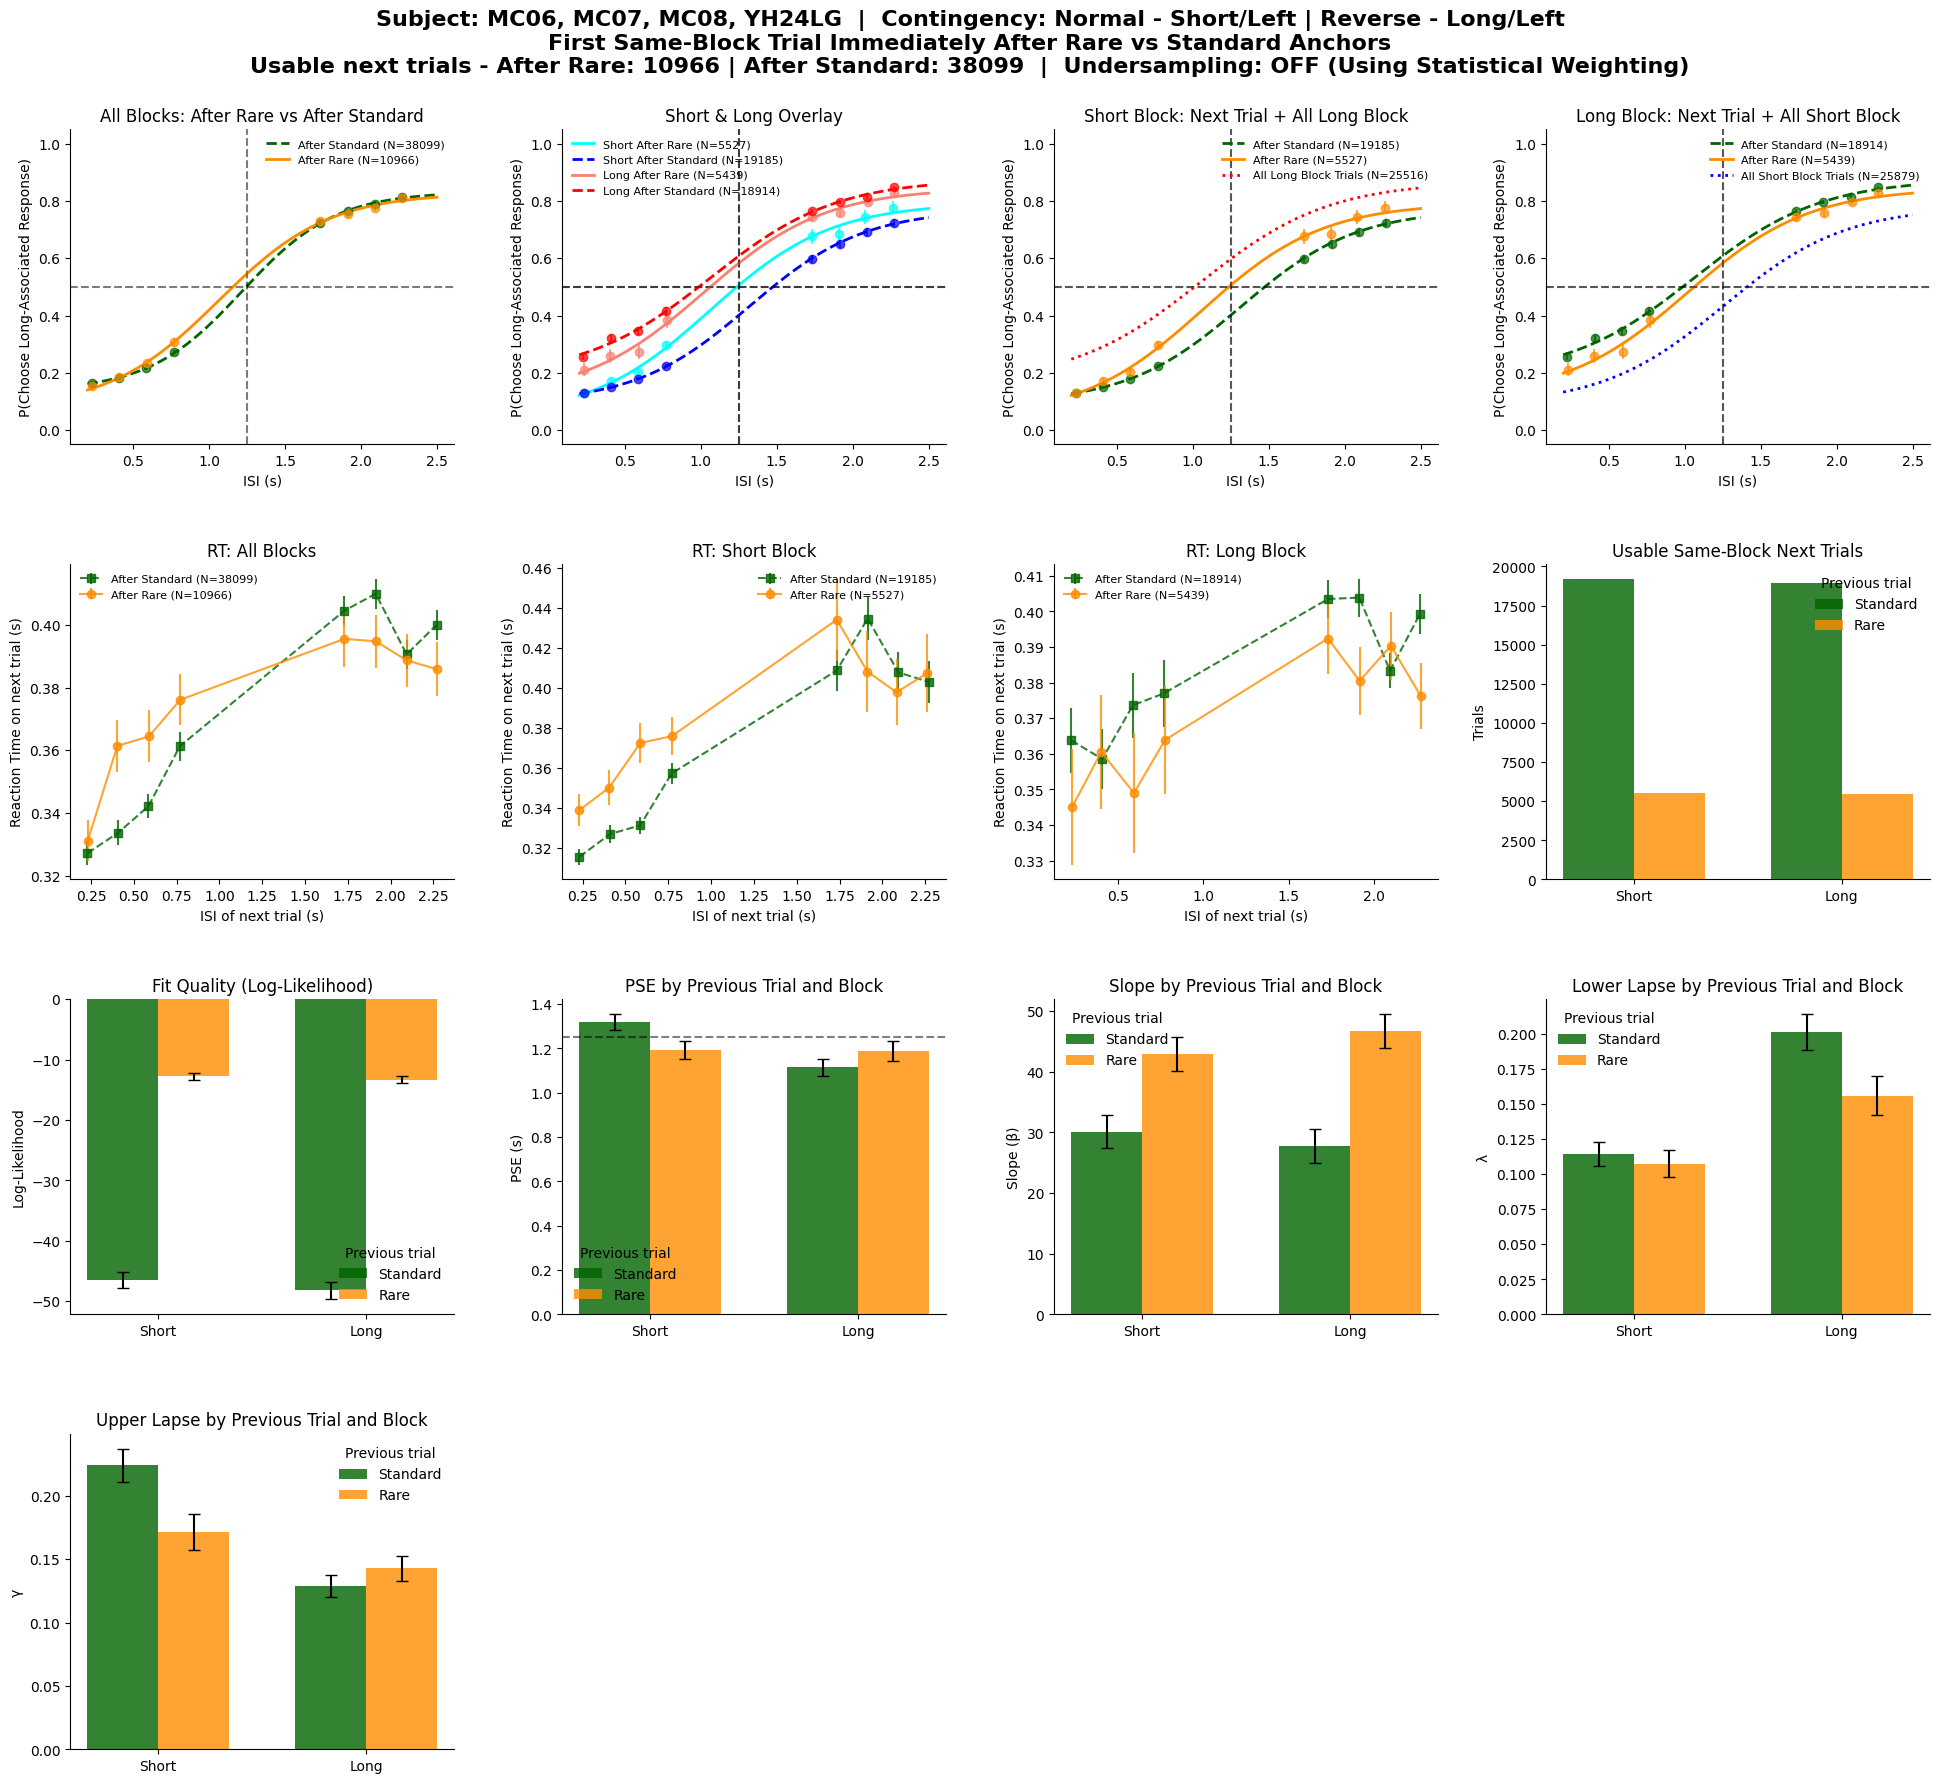

In [1]:
# First trial immediately after Rare vs Standard anchors, restricted to same contiguous block
import os
import ast
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.optimize import curve_fit

warnings.filterwarnings('ignore')

# ==========================================
# SETTING: Toggle Data Balancing On or Off
# ==========================================
USE_UNDERSAMPLING_NEXT_TRIAL = False
# ==========================================

ANCHOR_ORDER = ['Standard', 'Rare']
ANCHOR_PALETTE = {'Standard': 'darkgreen', 'Rare': 'darkorange'}
BLOCK_ORDER = ['Short', 'Long']
BLOCK_LABELS = {1: 'Short', 2: 'Long'}


def logist(x, alpha, beta, lam, gamma):
    return lam + (1 - lam - gamma) / (1 + np.exp(-beta * (x - alpha)))


def balance_datasets(df1, df2, seed=42):
    if not USE_UNDERSAMPLING_NEXT_TRIAL:
        return df1, df2

    min_len = min(len(df1), len(df2))
    if min_len == 0:
        return df1.iloc[0:0], df2.iloc[0:0]

    return df1.sample(n=min_len, random_state=seed), df2.sample(n=min_len, random_state=seed)


def fit_data(data):
    data = data.dropna(subset=['trial_isi', 'target_choice']).copy()
    if len(data) < 5 or data['target_choice'].nunique() < 2:
        return np.full(4, np.nan), np.full(4, np.nan), np.nan

    x = data['trial_isi'].to_numpy(dtype=float)
    y = data['target_choice'].to_numpy(dtype=float)

    p0 = [1.25, 10, 0.05, 0.05]
    bounds = ([0.2, 0, 0, 0], [2.5, 100, 0.5, 0.5])
    try:
        popt, pcov = curve_fit(logist, x, y, p0=p0, bounds=bounds, maxfev=10000)
        perr = np.sqrt(np.diag(pcov))

        y_pred = np.clip(logist(x, *popt), 1e-5, 1 - 1e-5)
        ll = np.sum(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
        return popt, perr, ll
    except Exception:
        return np.full(4, np.nan), np.full(4, np.nan), np.nan


def get_binned_stats(data, n_bins_per_type=4):
    stats = []
    data = data.dropna(subset=['trial_isi', 'target_choice']).copy()

    for tt in [1, 2]:
        tt_data = data[data['trial_type'] == tt]
        if len(tt_data) == 0:
            continue

        np.random.seed(42)
        jittered_isi = tt_data['trial_isi'] + np.random.normal(0, 1e-6, len(tt_data))
        try:
            bins = pd.qcut(jittered_isi, q=min(n_bins_per_type, len(tt_data)), duplicates='drop')
        except Exception:
            continue

        for _, g in tt_data.groupby(bins, observed=False):
            if len(g) == 0:
                continue

            stats.append({
                'isi_mean': g['trial_isi'].mean(),
                'p_target': g['target_choice'].mean(),
                'p_se': g['target_choice'].sem() if len(g) > 1 else 0,
                'rt_mean': g['lick_reaction_time'].mean() if 'lick_reaction_time' in g.columns else np.nan,
                'rt_se': g['lick_reaction_time'].sem() if 'lick_reaction_time' in g.columns and len(g) > 1 else 0,
            })

    if not stats:
        return pd.DataFrame()
    return pd.DataFrame(stats).sort_values('isi_mean')

NEGATIVE_LICK_ARRAY_COLUMNS = ['all_lick_reaction_times', 'all_lick_start_times_from_choice']


def has_negative_lick_array(value):
    if value is None:
        return False
    if isinstance(value, float) and np.isnan(value):
        return False

    if isinstance(value, str):
        text = value.strip()
        if not text or text.lower() in {'nan', 'none'}:
            return False
        try:
            values = ast.literal_eval(text)
        except (ValueError, SyntaxError):
            return False
    else:
        values = value

    if isinstance(values, (int, float, np.integer, np.floating)):
        return pd.notna(values) and float(values) < 0

    try:
        iterator = list(values)
    except TypeError:
        return False

    for item in iterator:
        if item is None:
            continue
        try:
            if pd.notna(item) and float(item) < 0:
                return True
        except (TypeError, ValueError):
            continue
    return False


def get_negative_lick_array_mask(data):
    columns = [column for column in NEGATIVE_LICK_ARRAY_COLUMNS if column in data.columns]
    if not columns:
        return pd.Series(False, index=data.index)

    mask = pd.Series(False, index=data.index)
    for column in columns:
        mask = mask | data[column].apply(has_negative_lick_array)
    return mask


def get_rt_binned_stats(data, n_bins_per_type=4):
    rt_data = data.loc[~get_negative_lick_array_mask(data)].copy()
    return get_binned_stats(rt_data, n_bins_per_type=n_bins_per_type)



def _raw_isi_fit_grid(ax, data, n_points=200):
    raw_isi = pd.to_numeric(data['trial_isi'], errors='coerce').dropna()
    if raw_isi.empty:
        return np.array([])
    data_min, data_max = float(raw_isi.min()), float(raw_isi.max())
    panel_min = min(getattr(ax, '_raw_isi_min', data_min), data_min)
    panel_max = max(getattr(ax, '_raw_isi_max', data_max), data_max)
    ax._raw_isi_min, ax._raw_isi_max = panel_min, panel_max
    if panel_min < panel_max:
        ax.set_xlim(panel_min, panel_max)
    return np.linspace(data_min, data_max, n_points) if data_min < data_max else np.array([data_min])

def clean_axis(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)


def plot_psycho(ax, data, popt, color, label, n_bins, y_label, plot_data=True, linestyle='-'):
    if plot_data:
        stats = get_binned_stats(data, n_bins_per_type=n_bins)
        if not stats.empty:
            ax.errorbar(
                stats['isi_mean'],
                stats['p_target'],
                yerr=stats['p_se'],
                fmt='o',
                color=color,
                alpha=0.7,
            )

    x_fit = _raw_isi_fit_grid(ax, data)
    if len(x_fit) and not np.isnan(popt[0]):
        ax.plot(
            x_fit,
            logist(x_fit, *popt),
            color=color,
            linewidth=2,
            linestyle=linestyle,
            label=f'{label} (N={len(data)})',
        )

    ax.axvline(1.25, color='k', linestyle='--', alpha=0.3)
    ax.axhline(0.5, color='k', linestyle='--', alpha=0.3)
    ax.set_ylim(-0.05, 1.05)
    ax.set_ylabel(y_label)
    ax.set_xlabel('ISI (s)')
    clean_axis(ax)
    ax.legend(loc='best', frameon=False, fontsize='8')


def plot_rt(ax, d_rare, d_standard, title, n_bins):
    s_rare = get_rt_binned_stats(d_rare, n_bins)
    s_standard = get_rt_binned_stats(d_standard, n_bins)

    if not s_standard.empty and not s_standard['rt_mean'].isna().all():
        ax.errorbar(
            s_standard['isi_mean'],
            s_standard['rt_mean'],
            yerr=s_standard['rt_se'],
            fmt='s--',
            color=ANCHOR_PALETTE['Standard'],
            label=f'After Standard (N={len(d_standard)})',
            alpha=0.8,
        )
    if not s_rare.empty and not s_rare['rt_mean'].isna().all():
        ax.errorbar(
            s_rare['isi_mean'],
            s_rare['rt_mean'],
            yerr=s_rare['rt_se'],
            fmt='o-',
            color=ANCHOR_PALETTE['Rare'],
            label=f'After Rare (N={len(d_rare)})',
            alpha=0.8,
        )

    ax.set_ylabel('Reaction Time on next trial (s)')
    ax.set_xlabel('ISI (s)')
    ax.set_title(title)
    clean_axis(ax)
    ax.legend(loc='best', frameon=False, fontsize='8')


def plot_grouped_bar(ax, df_stats, y_col, title, ylabel):
    x = np.arange(len(BLOCK_ORDER))
    width = 0.34

    if df_stats.empty or y_col not in df_stats.columns:
        ax.text(0.5, 0.5, 'No fitted data', transform=ax.transAxes, ha='center', va='center')
    else:
        plotted = False
        for i, anchor in enumerate(ANCHOR_ORDER):
            anchor_data = df_stats[df_stats['Anchor'].eq(anchor)]
            grouped = anchor_data.groupby('Block')[y_col]
            means = grouped.mean().reindex(BLOCK_ORDER)
            sems = grouped.sem().reindex(BLOCK_ORDER).fillna(0)
            valid = means.notna().to_numpy()
            if not valid.any():
                continue

            offset = (i - (len(ANCHOR_ORDER) - 1) / 2) * width
            ax.bar(
                x[valid] + offset,
                means.to_numpy()[valid],
                width=width,
                yerr=sems.to_numpy()[valid],
                color=ANCHOR_PALETTE[anchor],
                alpha=0.8,
                capsize=4,
                label=anchor,
            )
            plotted = True

        if plotted:
            ax.legend(title='Previous trial', frameon=False, loc='best')
        else:
            ax.text(0.5, 0.5, 'No fitted data', transform=ax.transAxes, ha='center', va='center')

    ax.set_xticks(x)
    ax.set_xticklabels(BLOCK_ORDER)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('')
    clean_axis(ax)


def plot_grouped_counts(ax, count_data):
    x = np.arange(len(BLOCK_ORDER))
    width = 0.34
    plotted = False

    for i, anchor in enumerate(ANCHOR_ORDER):
        anchor_counts = (
            count_data[count_data['Anchor'].eq(anchor)]
            .set_index('Block')['Trials']
            .reindex(BLOCK_ORDER)
        )
        valid = anchor_counts.notna().to_numpy()
        if not valid.any():
            continue

        offset = (i - (len(ANCHOR_ORDER) - 1) / 2) * width
        ax.bar(
            x[valid] + offset,
            anchor_counts.to_numpy()[valid],
            width=width,
            color=ANCHOR_PALETTE[anchor],
            alpha=0.8,
            label=anchor,
        )
        plotted = True

    ax.set_xticks(x)
    ax.set_xticklabels(BLOCK_ORDER)
    ax.set_title('Usable Same-Block Next Trials')
    ax.set_ylabel('Trials')
    ax.set_xlabel('')
    clean_axis(ax)
    if plotted:
        ax.legend(title='Previous trial', frameon=False, loc='best')
    else:
        ax.text(0.5, 0.5, 'No usable trials', transform=ax.transAxes, ha='center', va='center')


def add_session_key(df):
    df = df.copy()
    if 'session_uid' in df.columns:
        df['session_key'] = df['session_uid'].astype(str)
    elif {'subject', 'session_idx'}.issubset(df.columns):
        df['session_key'] = df['subject'].astype(str) + '_S' + df['session_idx'].astype(str)
    elif 'session_idx' in df.columns:
        df['session_key'] = 'S' + df['session_idx'].astype(str)
    else:
        df['session_key'] = 'S1'
    return df


def add_target_choice(df):
    df = df.copy()
    choice = df['lick_side'].astype(str).str.strip().str.lower()
    valid_choice = choice.isin(['right', 'left'])

    if 'Contingency' in df.columns:
        contingency_text = df['Contingency'].astype(str)
        normal = contingency_text.str.contains('Normal - Short/Left', na=False)
        reverse = contingency_text.str.contains('Reverse - Long/Left', na=False)
    elif 'Contingency_idx' in df.columns:
        contingency_idx = pd.to_numeric(df['Contingency_idx'], errors='coerce')
        normal = contingency_idx.eq(1)
        reverse = contingency_idx.eq(2)
    else:
        normal = pd.Series(True, index=df.index)
        reverse = pd.Series(False, index=df.index)

    unknown = ~(normal | reverse)
    if unknown.any():
        print(f"Warning: defaulting {unknown.sum()} unknown-contingency rows to normal/right-long mapping.")
        normal = normal | unknown

    df['target_choice'] = np.nan
    df.loc[normal & valid_choice, 'target_choice'] = choice[normal & valid_choice].eq('right').astype(int)
    df.loc[reverse & valid_choice, 'target_choice'] = choice[reverse & valid_choice].eq('left').astype(int)
    return df


def prepare_next_trial_dataframe(csv_path):
    df = pd.read_csv(csv_path).copy()
    required = ['trial_type', 'trial_isi', 'block_type', 'lick_side']
    missing = [column for column in required if column not in df.columns]
    if missing:
        raise ValueError(f"Missing required column(s): {', '.join(missing)}")

    df['_source_row'] = np.arange(len(df))
    df = add_session_key(df)

    for column in ['trial_type', 'trial_isi', 'block_type', 'lick_reaction_time']:
        if column in df.columns:
            df[column] = pd.to_numeric(df[column], errors='coerce')

    df = add_target_choice(df)

    df['is_common'] = np.nan
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 1), 'is_common'] = 1
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 2), 'is_common'] = 0
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 2), 'is_common'] = 1
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 1), 'is_common'] = 0

    # Contiguous block identity is computed inside each session before any choice filtering.
    df['block_instance'] = (
        df.groupby('session_key', sort=False)['block_type']
        .transform(lambda s: s.ne(s.shift()).cumsum())
    )

    rows = []
    block_rows = df[df['block_type'].isin([1, 2])].copy()
    for (session_key, block_instance), block_df in block_rows.groupby(['session_key', 'block_instance'], sort=False):
        block_df = block_df.sort_values('_source_row')
        if len(block_df) < 2:
            continue

        for position in range(len(block_df) - 1):
            anchor = block_df.iloc[position]
            next_trial = block_df.iloc[position + 1]

            if pd.isna(anchor['is_common']):
                continue

            row = next_trial.to_dict()
            row['Anchor'] = 'Standard' if int(anchor['is_common']) == 1 else 'Rare'
            row['anchor_block_type'] = int(anchor['block_type'])
            row['Block'] = BLOCK_LABELS.get(int(anchor['block_type']), str(anchor['block_type']))
            row['anchor_trial_type'] = anchor['trial_type']
            row['anchor_trial_isi'] = anchor['trial_isi']
            row['anchor_source_row'] = int(anchor['_source_row'])
            row['next_source_row'] = int(next_trial['_source_row'])
            rows.append(row)

    next_trials = pd.DataFrame(rows)
    if next_trials.empty:
        return next_trials, df

    usable_next_trials = next_trials.dropna(subset=['trial_isi', 'target_choice']).copy()
    usable_next_trials['target_choice'] = usable_next_trials['target_choice'].astype(int)
    return usable_next_trials, df


def fit_pair(rare_df, standard_df):
    rare_balanced, standard_balanced = balance_datasets(rare_df, standard_df)
    p_rare, _, _ = fit_data(rare_balanced)
    p_standard, _, _ = fit_data(standard_balanced)
    return rare_balanced, standard_balanced, p_rare, p_standard


def plot_pair(ax, rare_df, standard_df, title, n_bins, y_label):
    rare_balanced, standard_balanced, p_rare, p_standard = fit_pair(rare_df, standard_df)
    plot_psycho(ax, standard_balanced, p_standard, ANCHOR_PALETTE['Standard'], 'After Standard', n_bins, y_label, linestyle='--')
    plot_psycho(ax, rare_balanced, p_rare, ANCHOR_PALETTE['Rare'], 'After Rare', n_bins, y_label)
    ax.set_title(title)
    return rare_balanced, standard_balanced, p_rare, p_standard


def make_next_trial_anchor_figure(next_trials, full_df, n_bins, save_dir):
    if next_trials.empty:
        raise ValueError('No usable same-block next trials found.')

    y_label = 'P(Choose Long-Associated Response)'
    balance_str = 'ON (Trials Forced Equal)' if USE_UNDERSAMPLING_NEXT_TRIAL else 'OFF (Using Statistical Weighting)'

    if 'subject' in full_df.columns:
        subjects = sorted(full_df['subject'].dropna().astype(str).unique())
        subject = ', '.join(subjects) if len(subjects) <= 4 else f'{len(subjects)} subjects'
    else:
        subject = 'Unknown'

    if 'Contingency' in full_df.columns:
        contingencies = sorted(full_df['Contingency'].dropna().astype(str).unique())
        contingency = ' | '.join(contingencies) if contingencies else 'Unknown'
    elif 'Contingency_idx' in full_df.columns:
        contingencies = sorted(pd.to_numeric(full_df['Contingency_idx'], errors='coerce').dropna().astype(int).unique())
        contingency = ' | '.join([f'idx={value}' for value in contingencies]) if contingencies else 'Unknown'
    else:
        contingency = 'Unknown'

    after_rare = next_trials[next_trials['Anchor'].eq('Rare')]
    after_standard = next_trials[next_trials['Anchor'].eq('Standard')]
    short_after_rare = after_rare[after_rare['anchor_block_type'].eq(1)]
    short_after_standard = after_standard[after_standard['anchor_block_type'].eq(1)]
    long_after_rare = after_rare[after_rare['anchor_block_type'].eq(2)]
    long_after_standard = after_standard[after_standard['anchor_block_type'].eq(2)]
    full_short_block = full_df[full_df['block_type'].eq(1)].dropna(subset=['trial_isi', 'target_choice']).copy()
    full_long_block = full_df[full_df['block_type'].eq(2)].dropna(subset=['trial_isi', 'target_choice']).copy()
    p_full_short, _, _ = fit_data(full_short_block)
    p_full_long, _, _ = fit_data(full_long_block)

    fig = plt.figure(figsize=(24, 20))
    fig.suptitle(
        f'Subject: {subject}  |  Contingency: {contingency}\n'
        f'First Same-Block Trial Immediately After Rare vs Standard Anchors\n'
        f'Usable next trials - After Rare: {len(after_rare)} | After Standard: {len(after_standard)}  |  Undersampling: {balance_str}',
        fontsize=16,
        fontweight='bold',
        y=0.98,
    )
    gs = gridspec.GridSpec(4, 4, figure=fig, top=0.92, hspace=0.38, wspace=0.28)

    ax1 = fig.add_subplot(gs[0, 0])
    d_all_rare, d_all_standard, p_all_rare, p_all_standard = plot_pair(
        ax1, after_rare, after_standard, 'All Blocks: After Rare vs After Standard', n_bins, y_label
    )

    ax2 = fig.add_subplot(gs[0, 1])
    d_short_rare, d_short_standard, p_short_rare, p_short_standard = fit_pair(short_after_rare, short_after_standard)
    d_long_rare, d_long_standard, p_long_rare, p_long_standard = fit_pair(long_after_rare, long_after_standard)
    plot_psycho(ax2, d_short_rare, p_short_rare, '#BCAE3E', 'Short After Rare', n_bins, y_label)
    plot_psycho(ax2, d_short_standard, p_short_standard, '#BCAE3E', 'Short After Standard', n_bins, y_label, linestyle='--')
    plot_psycho(ax2, d_long_rare, p_long_rare, 'blue', 'Long After Rare', n_bins, y_label)
    plot_psycho(ax2, d_long_standard, p_long_standard, 'blue', 'Long After Standard', n_bins, y_label, linestyle='--')
    ax2.set_title('Short & Long Overlay')

    ax3 = fig.add_subplot(gs[0, 2])
    plot_psycho(ax3, d_short_standard, p_short_standard, ANCHOR_PALETTE['Standard'], 'After Standard', n_bins, y_label, linestyle='--')
    plot_psycho(ax3, d_short_rare, p_short_rare, ANCHOR_PALETTE['Rare'], 'After Rare', n_bins, y_label)
    plot_psycho(ax3, full_long_block, p_full_long, 'blue', 'All Long Block Trials', n_bins, y_label, plot_data=False, linestyle=':')
    ax3.set_title('Short Block: Next Trial + All Long Block')

    ax4 = fig.add_subplot(gs[0, 3])
    plot_psycho(ax4, d_long_standard, p_long_standard, ANCHOR_PALETTE['Standard'], 'After Standard', n_bins, y_label, linestyle='--')
    plot_psycho(ax4, d_long_rare, p_long_rare, ANCHOR_PALETTE['Rare'], 'After Rare', n_bins, y_label)
    plot_psycho(ax4, full_short_block, p_full_short, '#BCAE3E', 'All Short Block Trials', n_bins, y_label, plot_data=False, linestyle=':')
    ax4.set_title('Long Block: Next Trial + All Short Block')

    ax5 = fig.add_subplot(gs[1, 0])
    plot_rt(ax5, d_all_rare, d_all_standard, 'RT: All Blocks', n_bins)

    ax6 = fig.add_subplot(gs[1, 1])
    plot_rt(ax6, d_short_rare, d_short_standard, 'RT: Short Block', n_bins)

    ax7 = fig.add_subplot(gs[1, 2])
    plot_rt(ax7, d_long_rare, d_long_standard, 'RT: Long Block', n_bins)

    ax8 = fig.add_subplot(gs[1, 3])
    count_data = (
        next_trials.groupby(['Block', 'Anchor'])
        .size()
        .rename('Trials')
        .reset_index()
    )
    plot_grouped_counts(ax8, count_data)

    session_res = []
    for sess in next_trials['session_key'].dropna().unique():
        sess_data = next_trials[next_trials['session_key'].eq(sess)]
        for block_type, block_name in [(1, 'Short'), (2, 'Long')]:
            block_data = sess_data[sess_data['anchor_block_type'].eq(block_type)]
            rare_data = block_data[block_data['Anchor'].eq('Rare')]
            standard_data = block_data[block_data['Anchor'].eq('Standard')]
            rare_balanced, standard_balanced = balance_datasets(rare_data, standard_data)

            for anchor_label, anchor_data in [('Standard', standard_balanced), ('Rare', rare_balanced)]:
                p_opt, _, ll = fit_data(anchor_data)
                if not np.isnan(p_opt[0]):
                    session_res.append({
                        'session': sess,
                        'Block': block_name,
                        'Anchor': anchor_label,
                        'PSE': p_opt[0],
                        'Slope': p_opt[1],
                        'Lam': p_opt[2],
                        'Gam': p_opt[3],
                        'LogLikelihood': ll,
                    })

    sdf = pd.DataFrame(session_res)

    ax9 = fig.add_subplot(gs[2, 0])
    plot_grouped_bar(ax9, sdf, 'LogLikelihood', 'Fit Quality (Log-Likelihood)', 'Log-Likelihood')

    ax10 = fig.add_subplot(gs[2, 1])
    plot_grouped_bar(ax10, sdf, 'PSE', 'PSE by Previous Trial and Block', 'PSE (s)')
    ax10.axhline(1.25, color='k', linestyle='--', alpha=0.5)

    ax11 = fig.add_subplot(gs[2, 2])
    plot_grouped_bar(ax11, sdf, 'Slope', 'Slope by Previous Trial and Block', 'Slope (β)')

    ax12 = fig.add_subplot(gs[2, 3])
    plot_grouped_bar(ax12, sdf, 'Lam', 'Lower Lapse by Previous Trial and Block', 'λ')

    ax13 = fig.add_subplot(gs[3, 0])
    plot_grouped_bar(ax13, sdf, 'Gam', 'Upper Lapse by Previous Trial and Block', 'γ')

    for empty_position in [(3, 1), (3, 2), (3, 3)]:
        empty_ax = fig.add_subplot(gs[empty_position])
        empty_ax.axis('off')

    save_path = os.path.join(save_dir, 'next_trial_after_rare_standard_psychometrics.pdf')
    plt.savefig(save_path, dpi=600, bbox_inches='tight')
    print(f'Done! Figure saved to {save_path}')
    print('\nUsable same-block next-trial counts')
    print(count_data.to_string(index=False))
    return fig, next_trials, sdf


def main_next_trial_after_anchor():
    csv_path = input('Enter the path to your CSV file [all_subjects_final_data.csv]: ').strip() or 'all_subjects_final_data.csv'
    if not os.path.exists(csv_path):
        print(f'File not found: {csv_path}. Please check the path and try again.')
        return

    n_bins_input = input('Enter the number of bins to use per trial type [4]: ').strip()
    try:
        n_bins = int(n_bins_input) if n_bins_input else 4
    except ValueError:
        print('Invalid number of bins provided. Defaulting to 4.')
        n_bins = 4

    save_dir = input('Enter the directory to save the figure [current directory]: ').strip() or '.'
    if save_dir and not os.path.exists(save_dir):
        os.makedirs(save_dir)
        print(f'Created directory: {save_dir}')

    print('Processing first same-block next trials after Rare vs Standard anchors...')
    next_trials, full_df = prepare_next_trial_dataframe(csv_path)
    fig, next_trials_used, session_fit_stats = make_next_trial_anchor_figure(next_trials, full_df, n_bins, save_dir)
    plt.show()
    return fig, next_trials_used, session_fit_stats


if __name__ == '__main__':
    next_trial_anchor_result = main_next_trial_after_anchor()


Processing sliding-window first same-block next trials after Rare vs Standard anchors...
Done! Figure saved to ./sliding_window_after_rare_standard_psychometrics.png

Usable sliding-window same-block next-trial counts
Block   Anchor window_label  Trials
 Long     Rare          1-7     215
 Long     Rare        11-17     428
 Long     Rare        13-19     429
 Long     Rare        15-21     276
 Long     Rare        17-23     174
 Long     Rare        19-25     102
 Long     Rare        21-27      38
 Long     Rare          3-9     375
 Long     Rare         5-11     476
 Long     Rare         7-13     465
 Long     Rare         9-15     406
 Long Standard          1-7    1491
 Long Standard        11-17    1202
 Long Standard        13-19    1191
 Long Standard        15-21     814
 Long Standard        17-23     576
 Long Standard        19-25     317
 Long Standard        21-27     119
 Long Standard          3-9    1309
 Long Standard         5-11    1182
 Long Standard         7-1

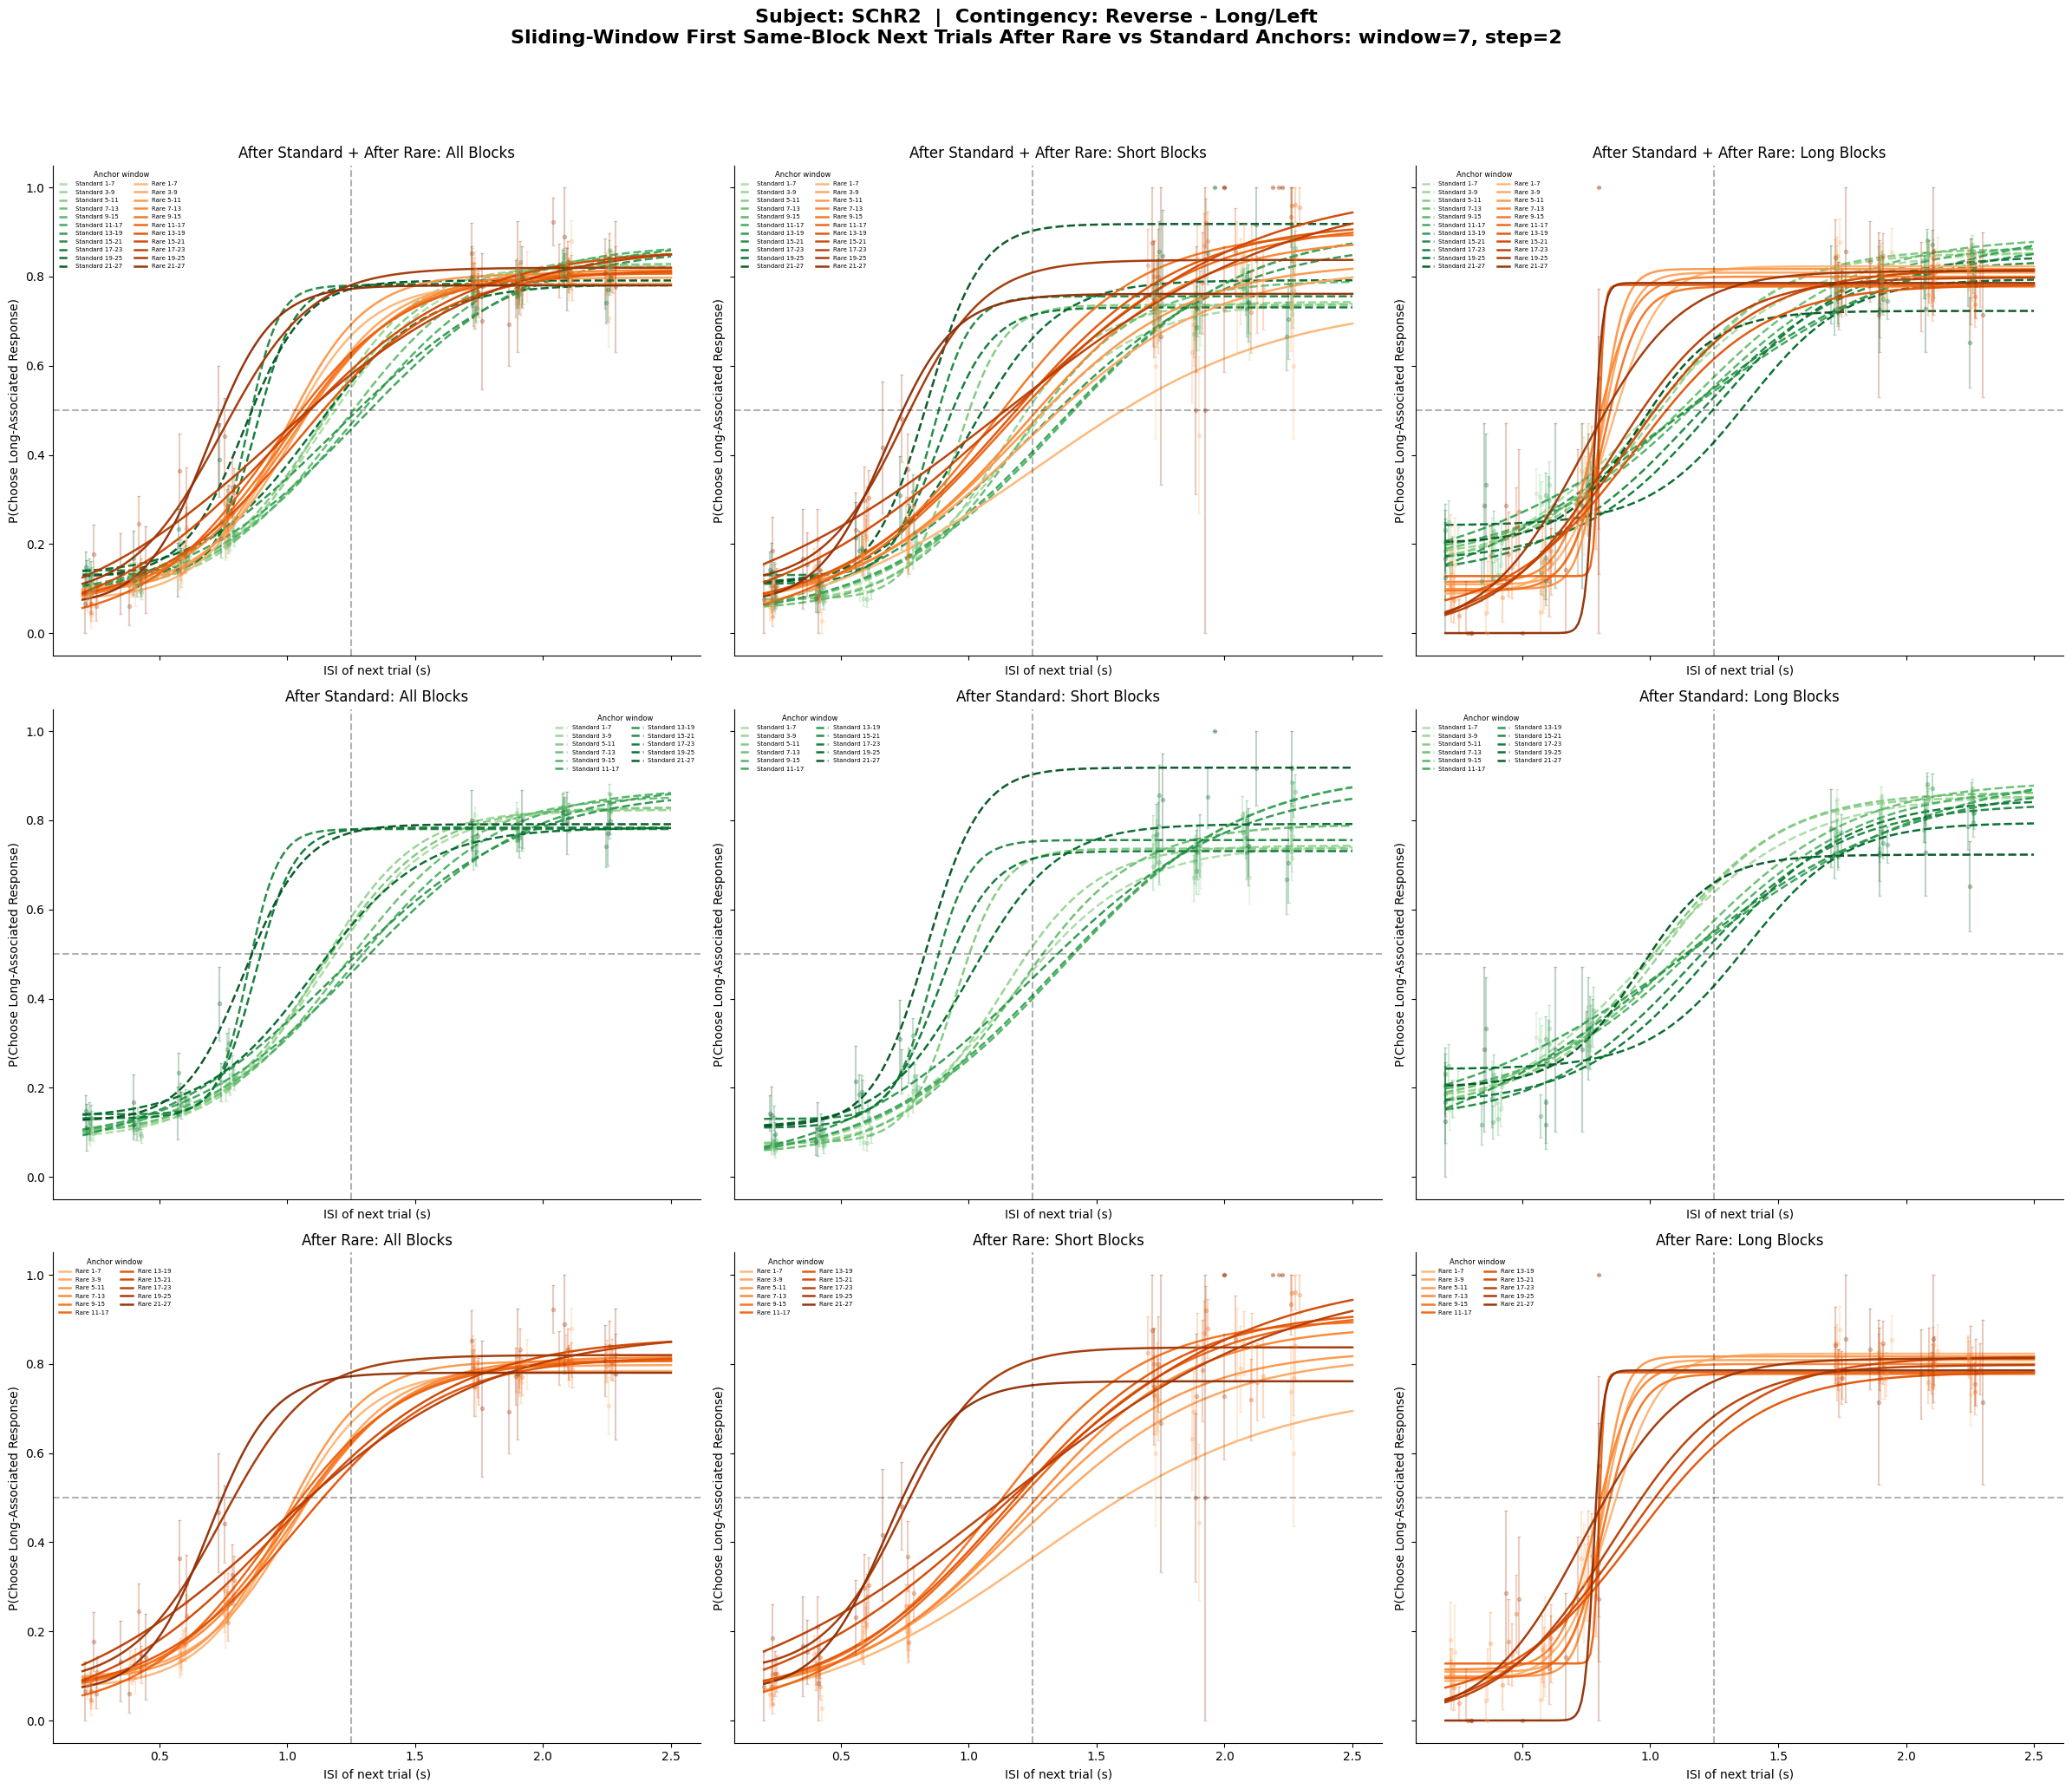

In [20]:
# Sliding-window psychometrics after Rare vs Standard anchors within each Short/Long block
import os
import warnings
from matplotlib.lines import Line2D

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

warnings.filterwarnings('ignore')

SLIDING_WINDOW_SIZE = 7
SLIDING_WINDOW_STEP = 2
ANCHOR_ORDER = ['Standard', 'Rare']
ANCHOR_CMAPS = {'Standard': 'Greens', 'Rare': 'Oranges'}
ANCHOR_LINESTYLES = {'Standard': '--', 'Rare': '-'}
BLOCK_LABELS = {1: 'Short', 2: 'Long'}
COLUMN_ORDER = ['All', 'Short', 'Long']
ROW_ORDER = [
    ('Overlay', ['Standard', 'Rare'], 'After Standard + After Rare'),
    ('Standard', ['Standard'], 'After Standard'),
    ('Rare', ['Rare'], 'After Rare'),
]


def logist(x, alpha, beta, lam, gamma):
    return lam + (1 - lam - gamma) / (1 + np.exp(-beta * (x - alpha)))


def fit_data(data):
    data = data.dropna(subset=['trial_isi', 'target_choice']).copy()
    if len(data) < 5 or data['target_choice'].nunique() < 2:
        return np.full(4, np.nan), np.full(4, np.nan), np.nan

    x = data['trial_isi'].to_numpy(dtype=float)
    y = data['target_choice'].to_numpy(dtype=float)

    p0 = [1.25, 10, 0.05, 0.05]
    bounds = ([0.2, 0, 0, 0], [2.5, 100, 0.5, 0.5])
    try:
        popt, pcov = curve_fit(logist, x, y, p0=p0, bounds=bounds, maxfev=10000)
        perr = np.sqrt(np.diag(pcov))
        y_pred = np.clip(logist(x, *popt), 1e-5, 1 - 1e-5)
        ll = np.sum(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
        return popt, perr, ll
    except Exception:
        return np.full(4, np.nan), np.full(4, np.nan), np.nan


def get_binned_stats(data, n_bins_per_type=4):
    stats = []
    data = data.dropna(subset=['trial_isi', 'target_choice']).copy()

    for tt in [1, 2]:
        tt_data = data[data['trial_type'] == tt]
        if len(tt_data) == 0:
            continue

        np.random.seed(42)
        jittered_isi = tt_data['trial_isi'] + np.random.normal(0, 1e-6, len(tt_data))
        try:
            bins = pd.qcut(jittered_isi, q=min(n_bins_per_type, len(tt_data)), duplicates='drop')
        except Exception:
            continue

        for _, g in tt_data.groupby(bins, observed=False):
            if len(g) == 0:
                continue

            stats.append({
                'isi_mean': g['trial_isi'].mean(),
                'p_target': g['target_choice'].mean(),
                'p_se': g['target_choice'].sem() if len(g) > 1 else 0,
            })

    if not stats:
        return pd.DataFrame()
    return pd.DataFrame(stats).sort_values('isi_mean')


def clean_axis(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)


def add_session_key(df):
    df = df.copy()
    if 'session_uid' in df.columns:
        df['session_key'] = df['session_uid'].astype(str)
    elif {'subject', 'session_idx'}.issubset(df.columns):
        df['session_key'] = df['subject'].astype(str) + '_S' + df['session_idx'].astype(str)
    elif 'session_idx' in df.columns:
        df['session_key'] = 'S' + df['session_idx'].astype(str)
    else:
        df['session_key'] = 'S1'
    return df


def add_target_choice(df):
    df = df.copy()
    choice = df['lick_side'].astype(str).str.strip().str.lower()
    valid_choice = choice.isin(['right', 'left'])

    if 'Contingency' in df.columns:
        contingency_text = df['Contingency'].astype(str)
        normal = contingency_text.str.contains('Normal - Short/Left', na=False)
        reverse = contingency_text.str.contains('Reverse - Long/Left', na=False)
    elif 'Contingency_idx' in df.columns:
        contingency_idx = pd.to_numeric(df['Contingency_idx'], errors='coerce')
        normal = contingency_idx.eq(1)
        reverse = contingency_idx.eq(2)
    else:
        normal = pd.Series(True, index=df.index)
        reverse = pd.Series(False, index=df.index)

    unknown = ~(normal | reverse)
    if unknown.any():
        print(f"Warning: defaulting {unknown.sum()} unknown-contingency rows to normal/right-long mapping.")
        normal = normal | unknown

    df['target_choice'] = np.nan
    df.loc[normal & valid_choice, 'target_choice'] = choice[normal & valid_choice].eq('right').astype(int)
    df.loc[reverse & valid_choice, 'target_choice'] = choice[reverse & valid_choice].eq('left').astype(int)
    return df


def prepare_sliding_window_dataframe(csv_path, window_size=SLIDING_WINDOW_SIZE, step_size=SLIDING_WINDOW_STEP):
    required = ['trial_type', 'trial_isi', 'block_type', 'lick_side']
    optional = ['session_uid', 'subject', 'session_idx', 'Contingency', 'Contingency_idx']
    header = pd.read_csv(csv_path, nrows=0).columns
    usecols = [column for column in required + optional if column in header]
    df = pd.read_csv(csv_path, usecols=usecols).copy()

    missing = [column for column in required if column not in df.columns]
    if missing:
        raise ValueError(f"Missing required column(s): {', '.join(missing)}")

    df['_source_row'] = np.arange(len(df))
    df = add_session_key(df)

    for column in ['trial_type', 'trial_isi', 'block_type']:
        df[column] = pd.to_numeric(df[column], errors='coerce')

    df = add_target_choice(df)
    df['is_common'] = np.nan
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 1), 'is_common'] = 1
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 2), 'is_common'] = 0
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 2), 'is_common'] = 1
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 1), 'is_common'] = 0

    df['block_instance'] = (
        df.groupby('session_key', sort=False)['block_type']
        .transform(lambda s: s.ne(s.shift()).cumsum())
    )

    rows = []
    block_rows = df[df['block_type'].isin([1, 2])].copy()
    for (session_key, block_instance), block_df in block_rows.groupby(['session_key', 'block_instance'], sort=False):
        block_df = block_df.sort_values('_source_row')
        n_anchor_positions = len(block_df) - 1
        if n_anchor_positions < window_size:
            continue

        block_type = int(block_df['block_type'].iloc[0])
        for start in range(0, n_anchor_positions - window_size + 1, step_size):
            for offset in range(window_size):
                anchor_position = start + offset
                anchor = block_df.iloc[anchor_position]
                next_trial = block_df.iloc[anchor_position + 1]

                if pd.isna(anchor['is_common']):
                    continue

                row = next_trial.to_dict()
                row['Anchor'] = 'Standard' if int(anchor['is_common']) == 1 else 'Rare'
                row['anchor_block_type'] = block_type
                row['Block'] = BLOCK_LABELS.get(block_type, str(block_type))
                row['anchor_trial_type'] = anchor['trial_type']
                row['anchor_trial_isi'] = anchor['trial_isi']
                row['anchor_source_row'] = int(anchor['_source_row'])
                row['next_source_row'] = int(next_trial['_source_row'])
                row['anchor_position_in_block'] = anchor_position + 1
                row['next_position_in_block'] = anchor_position + 2
                row['window_start_position'] = start + 1
                row['window_end_position'] = start + window_size
                row['window_label'] = f'{start + 1}-{start + window_size}'
                row['window_size'] = window_size
                row['window_step'] = step_size
                rows.append(row)

    window_trials = pd.DataFrame(rows)
    if window_trials.empty:
        return window_trials, df

    usable_window_trials = window_trials.dropna(subset=['trial_isi', 'target_choice']).copy()
    usable_window_trials['target_choice'] = usable_window_trials['target_choice'].astype(int)
    return usable_window_trials, df


def _window_colors(window_starts, anchor):
    cmap = plt.get_cmap(ANCHOR_CMAPS[anchor])
    color_values = np.linspace(0.35, 0.95, max(len(window_starts), 1))
    return dict(zip(window_starts, cmap(color_values)))


def plot_sliding_window_anchor_psychometrics(ax, data, title, n_bins, anchors, fixed_ylim=True):
    if data.empty:
        ax.text(0.5, 0.5, 'No usable trials', transform=ax.transAxes, ha='center', va='center')
        ax.set_title(title)
        clean_axis(ax)
        return []

    window_starts = sorted(data['window_start_position'].dropna().unique())
    raw_isi = pd.to_numeric(data['trial_isi'], errors='coerce').dropna()
    x_min, x_max = float(raw_isi.min()), float(raw_isi.max())
    x_fit = np.linspace(x_min, x_max, 200) if x_min < x_max else np.array([x_min])
    if x_min < x_max:
        ax.set_xlim(x_min, x_max)
    fit_rows = []
    plotted_labels = set()

    for anchor in anchors:
        anchor_data = data[data['Anchor'].eq(anchor)]
        if anchor_data.empty:
            continue

        colors = _window_colors(window_starts, anchor)
        for window_start in window_starts:
            window_data = anchor_data[anchor_data['window_start_position'].eq(window_start)]
            if window_data.empty:
                continue

            window_label = window_data['window_label'].iloc[0]
            popt, _, ll = fit_data(window_data)
            stats = get_binned_stats(window_data, n_bins_per_type=n_bins)
            color = colors[window_start]
            linestyle = ANCHOR_LINESTYLES[anchor]
            label = f'{anchor} {window_label}'

            if not stats.empty:
                ax.errorbar(
                    stats['isi_mean'],
                    stats['p_target'],
                    yerr=stats['p_se'],
                    fmt='o',
                    color=color,
                    alpha=0.25,
                    markersize=3,
                    capsize=1.5,
                )

            if not np.isnan(popt[0]):
                ax.plot(
                    x_fit,
                    logist(x_fit, *popt),
                    color=color,
                    linewidth=1.8,
                    linestyle=linestyle,
                    alpha=0.95,
                    label=label if label not in plotted_labels else None,
                )
                plotted_labels.add(label)
                fit_rows.append({
                    'Anchor': anchor,
                    'Window': window_label,
                    'window_start_position': window_start,
                    'N': len(window_data),
                    'PSE': popt[0],
                    'Slope': popt[1],
                    'Lam': popt[2],
                    'Gam': popt[3],
                    'LogLikelihood': ll,
                })

    ax.axvline(1.25, color='k', linestyle='--', alpha=0.3)
    ax.axhline(0.5, color='k', linestyle='--', alpha=0.3)
    if fixed_ylim:
        ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel('ISI (s)')
    ax.set_ylabel('P(Choose Long-Associated Response)')
    ax.set_title(title)
    clean_axis(ax)

    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ncol = 2 if len(handles) > 8 else 1
        ax.legend(handles, labels, title='Anchor window', loc='best', frameon=False, fontsize='5', title_fontsize='6', ncol=ncol)
    return fit_rows


def _subset_for_column(window_trials, column_name):
    if column_name == 'All':
        return window_trials.copy()
    if column_name == 'Short':
        return window_trials[window_trials['anchor_block_type'].eq(1)]
    if column_name == 'Long':
        return window_trials[window_trials['anchor_block_type'].eq(2)]
    raise ValueError(f'Unknown column: {column_name}')


def make_sliding_window_psychometric_figure(window_trials, full_df, n_bins, save_dir):
    if window_trials.empty:
        raise ValueError('No usable sliding-window trials found.')

    if 'subject' in full_df.columns:
        subjects = sorted(full_df['subject'].dropna().astype(str).unique())
        subject = ', '.join(subjects) if len(subjects) <= 4 else f'{len(subjects)} subjects'
    else:
        subject = 'Unknown'

    if 'Contingency' in full_df.columns:
        contingencies = sorted(full_df['Contingency'].dropna().astype(str).unique())
        contingency = ' | '.join(contingencies) if contingencies else 'Unknown'
    elif 'Contingency_idx' in full_df.columns:
        contingencies = sorted(pd.to_numeric(full_df['Contingency_idx'], errors='coerce').dropna().astype(int).unique())
        contingency = ' | '.join([f'idx={value}' for value in contingencies]) if contingencies else 'Unknown'
    else:
        contingency = 'Unknown'

    fig, axes = plt.subplots(3, 3, figsize=(24, 21), sharex=True, sharey='row')
    fig.suptitle(
        f'Subject: {subject}  |  Contingency: {contingency}\n'
        f'Sliding-Window First Same-Block Next Trials After Rare vs Standard Anchors: window={SLIDING_WINDOW_SIZE}, step={SLIDING_WINDOW_STEP}',
        fontsize=16,
        fontweight='bold',
        y=0.98,
    )

    fit_rows = []
    for row_index, (row_key, anchors, row_title) in enumerate(ROW_ORDER):
        for col_index, column_name in enumerate(COLUMN_ORDER):
            ax = axes[row_index, col_index]
            subset = _subset_for_column(window_trials, column_name)
            subset = subset[subset['Anchor'].isin(anchors)]
            title = f'{row_title}: {column_name} Blocks'
            fixed_ylim = row_index == len(ROW_ORDER) - 1
            rows = plot_sliding_window_anchor_psychometrics(ax, subset, title, n_bins, anchors, fixed_ylim=fixed_ylim)
            for row in rows:
                row['Row'] = row_key
                row['Column'] = column_name
            fit_rows.extend(rows)

    fig.tight_layout(rect=[0, 0, 1, 0.94])

    save_path = os.path.join(save_dir, 'sliding_window_after_rare_standard_psychometrics.pdf')
    plt.savefig(save_path, dpi=600, bbox_inches='tight')
    print(f'Done! Figure saved to {save_path}')

    count_data = (
        window_trials.groupby(['Block', 'Anchor', 'window_label'])
        .size()
        .rename('Trials')
        .reset_index()
    )
    print('\nUsable sliding-window same-block next-trial counts')
    print(count_data.to_string(index=False))

    fit_stats = pd.DataFrame(fit_rows)
    return fig, window_trials, fit_stats


def main_sliding_window_psychometrics():
    csv_path = input('Enter the path to your CSV file [all_subjects_final_data.csv]: ').strip() or 'all_subjects_final_data.csv'
    if not os.path.exists(csv_path):
        print(f'File not found: {csv_path}. Please check the path and try again.')
        return

    n_bins_input = input('Enter the number of bins to use per trial type [4]: ').strip()
    try:
        n_bins = int(n_bins_input) if n_bins_input else 4
    except ValueError:
        print('Invalid number of bins provided. Defaulting to 4.')
        n_bins = 4

    save_dir = input('Enter the directory to save the figure [current directory]: ').strip() or '.'
    if save_dir and not os.path.exists(save_dir):
        os.makedirs(save_dir)
        print(f'Created directory: {save_dir}')

    print('Processing sliding-window first same-block next trials after Rare vs Standard anchors...')
    window_trials, full_df = prepare_sliding_window_dataframe(csv_path)
    fig, window_trials_used, window_fit_stats = make_sliding_window_psychometric_figure(window_trials, full_df, n_bins, save_dir)
    plt.show()
    return fig, window_trials_used, window_fit_stats


if __name__ == '__main__':
    sliding_window_result = main_sliding_window_psychometrics()


Processing immediately following same-block trials after rewarded/punished rare anchors...
Done! Figure saved to ./rare_reward_punish_early_late_sliding_psychometrics.png

All immediate usable next-trial counts
OutcomeClass Block  Trials
    Punished  Long    1732
    Punished Short    1754
    Rewarded  Long    3657
    Rewarded Short    3717

Early/late usable next-trial counts
OutcomeClass Block Phase  Trials
    Punished  Long Early     329
    Punished  Long  Late     656
    Punished Short Early     363
    Punished Short  Late     677
    Rewarded  Long Early     759
    Rewarded  Long  Late    1384
    Rewarded Short Early     726
    Rewarded Short  Late    1442

Sliding-window usable next-trial counts
OutcomeClass Block window_label  Trials
    Punished  Long          1-7     329
    Punished  Long        11-17     629
    Punished  Long        13-19     641
    Punished  Long        15-21     362
    Punished  Long        17-23     296
    Punished  Long        19-25     109

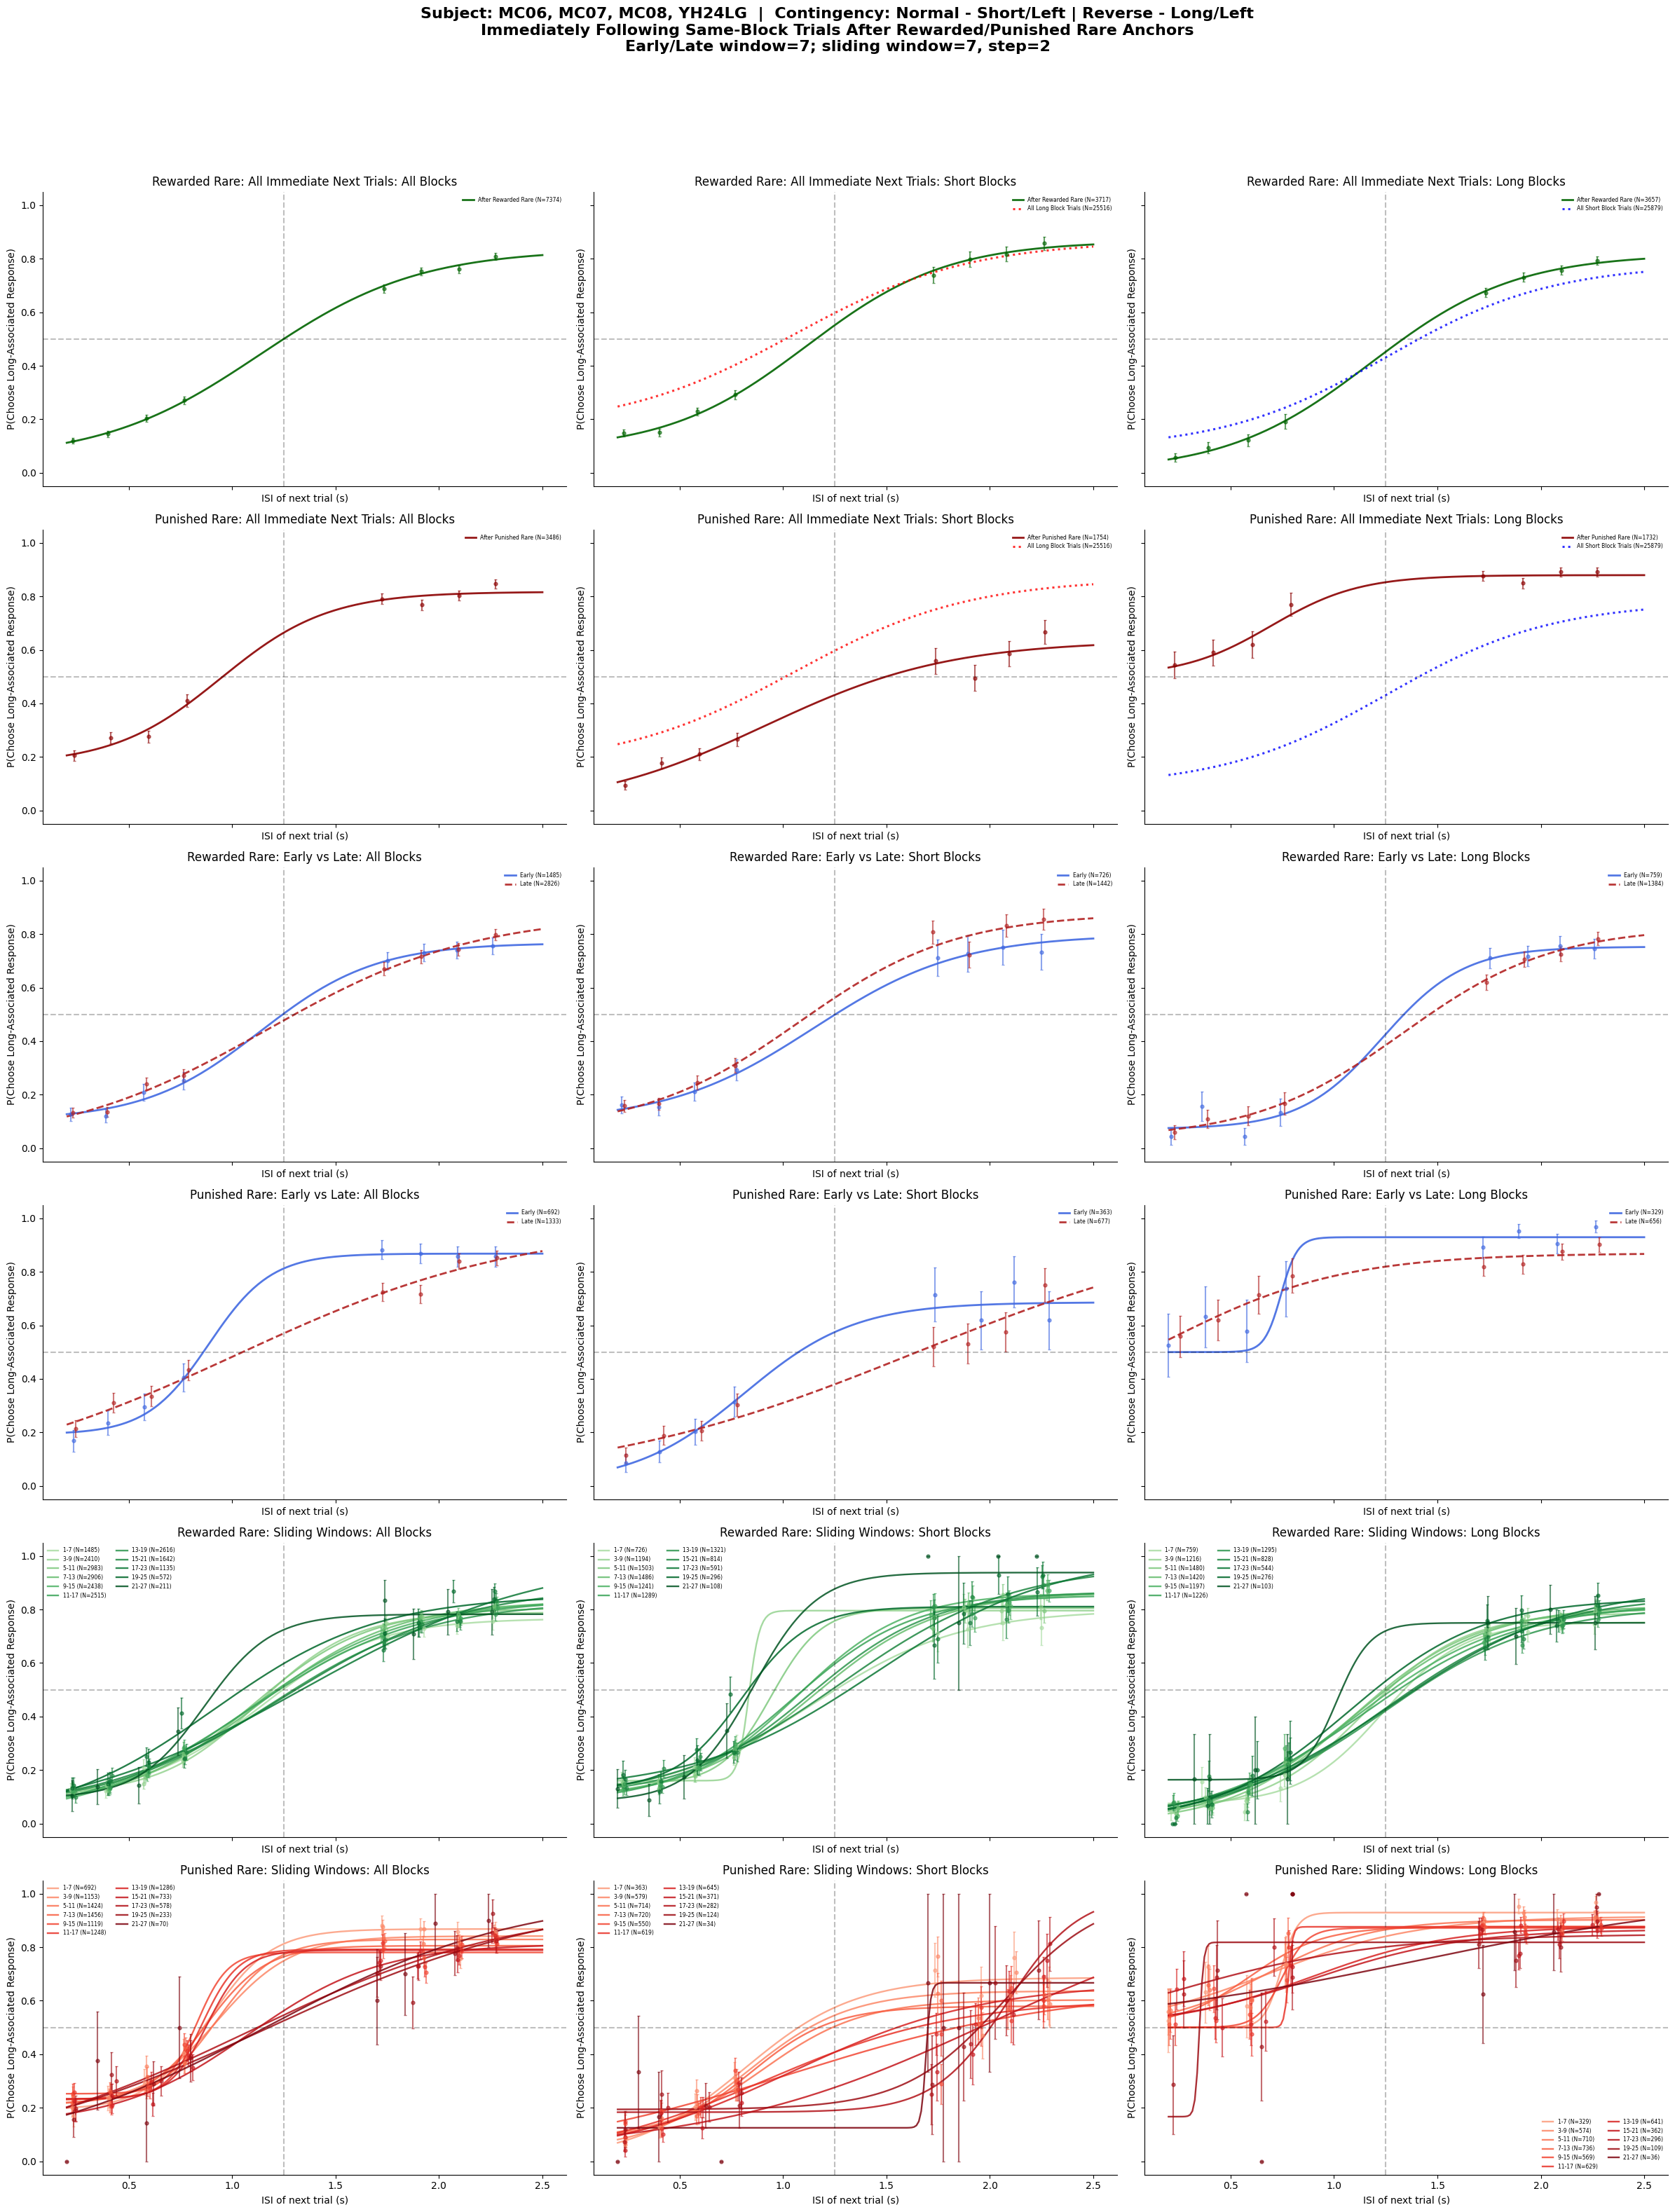

In [1]:
# Rare rewarded/punished anchors: early-vs-late and sliding-window next-trial psychometrics
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

warnings.filterwarnings('ignore')

RARE_OUTCOME_WINDOW_SIZE = 7
RARE_OUTCOME_WINDOW_STEP = 2
REWARD_OUTCOMES = {'Reward', 'RewardNaive'}
PUNISH_OUTCOMES = {'Punish', 'PunishNaive'}
OUTCOME_ROWS = [
    ('Rewarded', 'All', 'Rewarded Rare: All Immediate Next Trials'),
    ('Punished', 'All', 'Punished Rare: All Immediate Next Trials'),
    ('Rewarded', 'EarlyLate', 'Rewarded Rare: Early vs Late'),
    ('Punished', 'EarlyLate', 'Punished Rare: Early vs Late'),
    ('Rewarded', 'Sliding', 'Rewarded Rare: Sliding Windows'),
    ('Punished', 'Sliding', 'Punished Rare: Sliding Windows'),
]
COLUMN_ORDER = ['All', 'Short', 'Long']
BLOCK_LABELS = {1: 'Short', 2: 'Long'}
PHASE_COLORS = {'Early': 'royalblue', 'Late': 'firebrick'}
PHASE_LINESTYLES = {'Early': '-', 'Late': '--'}
OUTCOME_CMAPS = {'Rewarded': 'Greens', 'Punished': 'Reds'}


def logist(x, alpha, beta, lam, gamma):
    return lam + (1 - lam - gamma) / (1 + np.exp(-beta * (x - alpha)))


def fit_data(data):
    data = data.dropna(subset=['trial_isi', 'target_choice']).copy()
    if len(data) < 5 or data['target_choice'].nunique() < 2:
        return np.full(4, np.nan), np.full(4, np.nan), np.nan

    x = data['trial_isi'].to_numpy(dtype=float)
    y = data['target_choice'].to_numpy(dtype=float)

    p0 = [1.25, 10, 0.05, 0.05]
    bounds = ([0.2, 0, 0, 0], [2.5, 100, 0.5, 0.5])
    try:
        popt, pcov = curve_fit(logist, x, y, p0=p0, bounds=bounds, maxfev=10000)
        perr = np.sqrt(np.diag(pcov))
        y_pred = np.clip(logist(x, *popt), 1e-5, 1 - 1e-5)
        ll = np.sum(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
        return popt, perr, ll
    except Exception:
        return np.full(4, np.nan), np.full(4, np.nan), np.nan


def get_binned_stats(data, n_bins_per_type=4):
    stats = []
    data = data.dropna(subset=['trial_isi', 'target_choice']).copy()

    for trial_type in [1, 2]:
        tt_data = data[data['trial_type'].eq(trial_type)]
        if tt_data.empty:
            continue

        np.random.seed(42)
        jittered_isi = tt_data['trial_isi'] + np.random.normal(0, 1e-6, len(tt_data))
        try:
            bins = pd.qcut(jittered_isi, q=min(n_bins_per_type, len(tt_data)), duplicates='drop')
        except Exception:
            continue

        for _, group in tt_data.groupby(bins, observed=False):
            if group.empty:
                continue
            stats.append({
                'isi_mean': group['trial_isi'].mean(),
                'p_target': group['target_choice'].mean(),
                'p_se': group['target_choice'].sem() if len(group) > 1 else 0,
            })

    if not stats:
        return pd.DataFrame()
    return pd.DataFrame(stats).sort_values('isi_mean')


def clean_axis(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)


def add_session_key(df):
    df = df.copy()
    if 'session_uid' in df.columns:
        df['session_key'] = df['session_uid'].astype(str)
    elif {'subject', 'session_idx'}.issubset(df.columns):
        df['session_key'] = df['subject'].astype(str) + '_S' + df['session_idx'].astype(str)
    elif 'session_idx' in df.columns:
        df['session_key'] = 'S' + df['session_idx'].astype(str)
    else:
        df['session_key'] = 'S1'
    return df


def add_target_choice(df):
    df = df.copy()
    choice = df['lick_side'].astype(str).str.strip().str.lower()
    valid_choice = choice.isin(['right', 'left'])

    if 'Contingency' in df.columns:
        contingency_text = df['Contingency'].astype(str)
        normal = contingency_text.str.contains('Normal - Short/Left', na=False)
        reverse = contingency_text.str.contains('Reverse - Long/Left', na=False)
    elif 'Contingency_idx' in df.columns:
        contingency_idx = pd.to_numeric(df['Contingency_idx'], errors='coerce')
        normal = contingency_idx.eq(1)
        reverse = contingency_idx.eq(2)
    else:
        normal = pd.Series(True, index=df.index)
        reverse = pd.Series(False, index=df.index)

    unknown = ~(normal | reverse)
    if unknown.any():
        print(f"Warning: defaulting {unknown.sum()} unknown-contingency rows to normal/right-long mapping.")
        normal = normal | unknown

    df['target_choice'] = np.nan
    df.loc[normal & valid_choice, 'target_choice'] = choice[normal & valid_choice].eq('right').astype(int)
    df.loc[reverse & valid_choice, 'target_choice'] = choice[reverse & valid_choice].eq('left').astype(int)
    return df


def outcome_class(outcome):
    if outcome in REWARD_OUTCOMES:
        return 'Rewarded'
    if outcome in PUNISH_OUTCOMES:
        return 'Punished'
    return None


def prepare_rare_outcome_next_trial_dataframe(csv_path, window_size=RARE_OUTCOME_WINDOW_SIZE, step_size=RARE_OUTCOME_WINDOW_STEP):
    required = ['trial_type', 'trial_isi', 'block_type', 'lick_side', 'outcome']
    optional = ['session_uid', 'subject', 'session_idx', 'Contingency', 'Contingency_idx']
    header = pd.read_csv(csv_path, nrows=0).columns
    usecols = [column for column in required + optional if column in header]
    df = pd.read_csv(csv_path, usecols=usecols).copy()

    missing = [column for column in required if column not in df.columns]
    if missing:
        raise ValueError(f"Missing required column(s): {', '.join(missing)}")

    df['_source_row'] = np.arange(len(df))
    df = add_session_key(df)

    for column in ['trial_type', 'trial_isi', 'block_type']:
        df[column] = pd.to_numeric(df[column], errors='coerce')

    df = add_target_choice(df)
    df['is_common'] = np.nan
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 1), 'is_common'] = 1
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 2), 'is_common'] = 0
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 2), 'is_common'] = 1
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 1), 'is_common'] = 0

    df['block_instance'] = (
        df.groupby('session_key', sort=False)['block_type']
        .transform(lambda s: s.ne(s.shift()).cumsum())
    )

    all_rows = []
    early_late_rows = []
    sliding_rows = []
    block_rows = df[df['block_type'].isin([1, 2])].copy()

    for (session_key, block_instance), block_df in block_rows.groupby(['session_key', 'block_instance'], sort=False):
        block_df = block_df.sort_values('_source_row').reset_index(drop=True)
        n_anchor_positions = len(block_df) - 1
        if n_anchor_positions < window_size:
            continue

        block_type = int(block_df['block_type'].iloc[0])
        late_start = max(window_size, n_anchor_positions - window_size)

        for anchor_position in range(n_anchor_positions):
            anchor = block_df.iloc[anchor_position]
            next_trial = block_df.iloc[anchor_position + 1]

            if anchor['is_common'] != 0:
                continue

            anchor_outcome = outcome_class(anchor['outcome'])
            if anchor_outcome is None:
                continue

            base_row = next_trial.to_dict()
            base_row['OutcomeClass'] = anchor_outcome
            base_row['anchor_block_type'] = block_type
            base_row['Block'] = BLOCK_LABELS.get(block_type, str(block_type))
            base_row['anchor_trial_type'] = anchor['trial_type']
            base_row['anchor_trial_isi'] = anchor['trial_isi']
            base_row['anchor_outcome'] = anchor['outcome']
            base_row['anchor_source_row'] = int(anchor['_source_row'])
            base_row['next_source_row'] = int(next_trial['_source_row'])
            base_row['anchor_position_in_block'] = anchor_position + 1
            base_row['next_position_in_block'] = anchor_position + 2

            all_rows.append(base_row.copy())

            if anchor_position < window_size:
                row = base_row.copy()
                row['Phase'] = 'Early'
                row['phase_window_label'] = f'1-{window_size}'
                early_late_rows.append(row)
            elif anchor_position >= late_start:
                row = base_row.copy()
                row['Phase'] = 'Late'
                row['phase_window_label'] = f'{late_start + 1}-{n_anchor_positions}'
                early_late_rows.append(row)

        for start in range(0, n_anchor_positions - window_size + 1, step_size):
            for offset in range(window_size):
                anchor_position = start + offset
                anchor = block_df.iloc[anchor_position]
                next_trial = block_df.iloc[anchor_position + 1]

                if anchor['is_common'] != 0:
                    continue

                anchor_outcome = outcome_class(anchor['outcome'])
                if anchor_outcome is None:
                    continue

                row = next_trial.to_dict()
                row['OutcomeClass'] = anchor_outcome
                row['anchor_block_type'] = block_type
                row['Block'] = BLOCK_LABELS.get(block_type, str(block_type))
                row['anchor_trial_type'] = anchor['trial_type']
                row['anchor_trial_isi'] = anchor['trial_isi']
                row['anchor_outcome'] = anchor['outcome']
                row['anchor_source_row'] = int(anchor['_source_row'])
                row['next_source_row'] = int(next_trial['_source_row'])
                row['anchor_position_in_block'] = anchor_position + 1
                row['next_position_in_block'] = anchor_position + 2
                row['window_start_position'] = start + 1
                row['window_end_position'] = start + window_size
                row['window_label'] = f'{start + 1}-{start + window_size}'
                row['window_size'] = window_size
                row['window_step'] = step_size
                sliding_rows.append(row)

    all_trials = pd.DataFrame(all_rows)
    early_late_trials = pd.DataFrame(early_late_rows)
    sliding_trials = pd.DataFrame(sliding_rows)

    for trials in [all_trials, early_late_trials, sliding_trials]:
        if trials.empty:
            continue
        trials.dropna(subset=['trial_isi', 'target_choice'], inplace=True)
        trials['target_choice'] = trials['target_choice'].astype(int)

    return all_trials, early_late_trials, sliding_trials, df


def subset_for_column(data, column_name):
    if data.empty:
        return data
    if column_name == 'All':
        return data.copy()
    if column_name == 'Short':
        return data[data['anchor_block_type'].eq(1)].copy()
    if column_name == 'Long':
        return data[data['anchor_block_type'].eq(2)].copy()
    raise ValueError(f'Unknown column: {column_name}')


def _raw_isi_fit_grid(ax, data, n_points=200):
    raw_isi = pd.to_numeric(data['trial_isi'], errors='coerce').dropna()
    if raw_isi.empty:
        return np.array([])
    data_min, data_max = float(raw_isi.min()), float(raw_isi.max())
    panel_min = min(getattr(ax, '_raw_isi_min', data_min), data_min)
    panel_max = max(getattr(ax, '_raw_isi_max', data_max), data_max)
    ax._raw_isi_min, ax._raw_isi_max = panel_min, panel_max
    if panel_min < panel_max:
        ax.set_xlim(panel_min, panel_max)
    return np.linspace(data_min, data_max, n_points) if data_min < data_max else np.array([data_min])

def plot_psychometric_curve(ax, data, popt, color, label, n_bins, linestyle='-', plot_data=True, alpha=0.85, linewidth=2):
    if plot_data:
        stats = get_binned_stats(data, n_bins_per_type=n_bins)
        if not stats.empty:
            ax.errorbar(
                stats['isi_mean'],
                stats['p_target'],
                yerr=stats['p_se'],
                fmt='o',
                color=color,
                alpha=min(alpha, 0.6),
                markersize=3.5,
                capsize=1.5,
            )

    x_fit = _raw_isi_fit_grid(ax, data)
    if len(x_fit) and not np.isnan(popt[0]):
        ax.plot(
            x_fit,
            logist(x_fit, *popt),
            color=color,
            linestyle=linestyle,
            linewidth=linewidth,
            alpha=alpha,
            label=f'{label} (N={len(data)})',
        )


def finish_psychometric_axis(ax, title, show_legend=True):
    ax.axvline(1.25, color='k', linestyle='--', alpha=0.25)
    ax.axhline(0.5, color='k', linestyle='--', alpha=0.25)
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(title)
    ax.set_xlabel('ISI of next trial (s)')
    ax.set_ylabel('P(Choose Long-Associated Response)')
    clean_axis(ax)
    if show_legend:
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ncol = 2 if len(handles) > 6 else 1
            ax.legend(handles, labels, frameon=False, loc='best', fontsize='5.5', ncol=ncol)


def plot_all_outcome_panel(ax, data, outcome_label, column_name, title, n_bins, full_short_block, p_full_short, full_long_block, p_full_long):
    subset = subset_for_column(data[data['OutcomeClass'].eq(outcome_label)], column_name)
    outcome_color = 'darkgreen' if outcome_label == 'Rewarded' else 'darkred'
    if subset.empty:
        ax.text(0.5, 0.5, 'No usable trials', transform=ax.transAxes, ha='center', va='center')
    else:
        popt, _, ll = fit_data(subset)
        plot_psychometric_curve(
            ax,
            subset,
            popt,
            outcome_color,
            f'After {outcome_label} Rare',
            n_bins,
            linestyle='-',
            plot_data=True,
            alpha=0.9,
        )

    if column_name in ['Short', 'Long']:
        plot_psychometric_curve(
            ax,
            full_short_block,
            p_full_short,
            '#BCAE3E',
            'All Short Block Trials',
            n_bins,
            linestyle=':',
            plot_data=False,
            alpha=0.8,
            linewidth=2.2,
        )
        plot_psychometric_curve(
            ax,
            full_long_block,
            p_full_long,
            'blue',
            'All Long Block Trials',
            n_bins,
            linestyle=':',
            plot_data=False,
            alpha=0.8,
            linewidth=2.2,
        )

    finish_psychometric_axis(ax, title)
    if subset.empty:
        return []
    if np.isnan(popt[0]):
        return []
    return [{
        'OutcomeClass': outcome_label,
        'Analysis': 'All',
        'Column': column_name,
        'N': len(subset),
        'PSE': popt[0],
        'Slope': popt[1],
        'Lam': popt[2],
        'Gam': popt[3],
        'LogLikelihood': ll,
    }]


def plot_early_late_panel(ax, data, outcome_label, column_name, title, n_bins):
    subset = subset_for_column(data[data['OutcomeClass'].eq(outcome_label)], column_name)
    if subset.empty:
        ax.text(0.5, 0.5, 'No usable trials', transform=ax.transAxes, ha='center', va='center')
        finish_psychometric_axis(ax, title, show_legend=False)
        return []

    fit_rows = []
    for phase in ['Early', 'Late']:
        phase_data = subset[subset['Phase'].eq(phase)]
        popt, _, ll = fit_data(phase_data)
        plot_psychometric_curve(
            ax,
            phase_data,
            popt,
            PHASE_COLORS[phase],
            phase,
            n_bins,
            linestyle=PHASE_LINESTYLES[phase],
            plot_data=True,
            alpha=0.9,
        )
        if not np.isnan(popt[0]):
            fit_rows.append({
                'OutcomeClass': outcome_label,
                'Analysis': 'EarlyLate',
                'Column': column_name,
                'Phase': phase,
                'N': len(phase_data),
                'PSE': popt[0],
                'Slope': popt[1],
                'Lam': popt[2],
                'Gam': popt[3],
                'LogLikelihood': ll,
            })

    finish_psychometric_axis(ax, title)
    return fit_rows


def window_colors(window_starts, outcome_label):
    cmap = plt.get_cmap(OUTCOME_CMAPS[outcome_label])
    values = np.linspace(0.35, 0.95, max(len(window_starts), 1))
    return dict(zip(window_starts, cmap(values)))


def plot_sliding_panel(ax, data, outcome_label, column_name, title, n_bins):
    subset = subset_for_column(data[data['OutcomeClass'].eq(outcome_label)], column_name)
    if subset.empty:
        ax.text(0.5, 0.5, 'No usable trials', transform=ax.transAxes, ha='center', va='center')
        finish_psychometric_axis(ax, title, show_legend=False)
        return []

    fit_rows = []
    window_starts = sorted(subset['window_start_position'].dropna().unique())
    colors = window_colors(window_starts, outcome_label)

    for window_start in window_starts:
        window_data = subset[subset['window_start_position'].eq(window_start)]
        if window_data.empty:
            continue
        window_label = window_data['window_label'].iloc[0]
        popt, _, ll = fit_data(window_data)
        plot_psychometric_curve(
            ax,
            window_data,
            popt,
            colors[window_start],
            window_label,
            n_bins,
            linestyle='-',
            plot_data=True,
            alpha=0.85,
            linewidth=1.7,
        )
        if not np.isnan(popt[0]):
            fit_rows.append({
                'OutcomeClass': outcome_label,
                'Analysis': 'Sliding',
                'Column': column_name,
                'Window': window_label,
                'window_start_position': window_start,
                'N': len(window_data),
                'PSE': popt[0],
                'Slope': popt[1],
                'Lam': popt[2],
                'Gam': popt[3],
                'LogLikelihood': ll,
            })

    finish_psychometric_axis(ax, title)
    return fit_rows


def make_rare_outcome_early_late_sliding_figure(all_trials, early_late_trials, sliding_trials, full_df, n_bins, save_dir):
    if all_trials.empty and early_late_trials.empty and sliding_trials.empty:
        raise ValueError('No usable same-block next trials after rewarded/punished rare anchors found.')

    if 'subject' in full_df.columns:
        subjects = sorted(full_df['subject'].dropna().astype(str).unique())
        subject = ', '.join(subjects) if len(subjects) <= 4 else f'{len(subjects)} subjects'
    else:
        subject = 'Unknown'

    if 'Contingency' in full_df.columns:
        contingencies = sorted(full_df['Contingency'].dropna().astype(str).unique())
        contingency = ' | '.join(contingencies) if contingencies else 'Unknown'
    elif 'Contingency_idx' in full_df.columns:
        contingencies = sorted(pd.to_numeric(full_df['Contingency_idx'], errors='coerce').dropna().astype(int).unique())
        contingency = ' | '.join([f'idx={value}' for value in contingencies]) if contingencies else 'Unknown'
    else:
        contingency = 'Unknown'

    full_short_block = full_df[full_df['block_type'].eq(1)].dropna(subset=['trial_isi', 'target_choice']).copy()
    full_long_block = full_df[full_df['block_type'].eq(2)].dropna(subset=['trial_isi', 'target_choice']).copy()
    p_full_short, _, _ = fit_data(full_short_block)
    p_full_long, _, _ = fit_data(full_long_block)

    fig, axes = plt.subplots(len(OUTCOME_ROWS), 3, figsize=(24, 32), sharex=True, sharey=True)
    fig.suptitle(
        f'Subject: {subject}  |  Contingency: {contingency}\n'
        f'Immediately Following Same-Block Trials After Rewarded/Punished Rare Anchors\n'
        f'Early/Late window={RARE_OUTCOME_WINDOW_SIZE}; sliding window={RARE_OUTCOME_WINDOW_SIZE}, step={RARE_OUTCOME_WINDOW_STEP}',
        fontsize=16,
        fontweight='bold',
        y=0.985,
    )

    fit_rows = []
    for row_index, (outcome_label, analysis_type, row_title) in enumerate(OUTCOME_ROWS):
        for col_index, column_name in enumerate(COLUMN_ORDER):
            ax = axes[row_index, col_index]
            title = f'{row_title}: {column_name} Blocks'
            if analysis_type == 'All':
                rows = plot_all_outcome_panel(
                    ax,
                    all_trials,
                    outcome_label,
                    column_name,
                    title,
                    n_bins,
                    full_short_block,
                    p_full_short,
                    full_long_block,
                    p_full_long,
                )
            elif analysis_type == 'EarlyLate':
                rows = plot_early_late_panel(ax, early_late_trials, outcome_label, column_name, title, n_bins)
            else:
                rows = plot_sliding_panel(ax, sliding_trials, outcome_label, column_name, title, n_bins)
            fit_rows.extend(rows)

    fig.tight_layout(rect=[0, 0, 1, 0.94])

    save_dir = save_dir or '.'
    os.makedirs(save_dir, exist_ok=True)
    save_path = os.path.join(save_dir, 'rare_reward_punish_early_late_sliding_psychometrics.pdf')
    plt.savefig(save_path, dpi=600, bbox_inches='tight')
    print(f'Done! Figure saved to {save_path}')

    if not all_trials.empty:
        all_counts = (
            all_trials.groupby(['OutcomeClass', 'Block'])
            .size()
            .rename('Trials')
            .reset_index()
        )
        print('\nAll immediate usable next-trial counts')
        print(all_counts.to_string(index=False))

    if not early_late_trials.empty:
        early_counts = (
            early_late_trials.groupby(['OutcomeClass', 'Block', 'Phase'])
            .size()
            .rename('Trials')
            .reset_index()
        )
        print('\nEarly/late usable next-trial counts')
        print(early_counts.to_string(index=False))

    if not sliding_trials.empty:
        sliding_counts = (
            sliding_trials.groupby(['OutcomeClass', 'Block', 'window_label'])
            .size()
            .rename('Trials')
            .reset_index()
        )
        print('\nSliding-window usable next-trial counts')
        print(sliding_counts.to_string(index=False))

    fit_stats = pd.DataFrame(fit_rows)
    return fig, all_trials, early_late_trials, sliding_trials, fit_stats


def main_rare_outcome_early_late_sliding():
    csv_path = input('Enter the path to your CSV file [all_subjects_final_data.csv]: ').strip() or 'all_subjects_final_data.csv'
    if not os.path.exists(csv_path):
        print(f'File not found: {csv_path}. Please check the path and try again.')
        return

    n_bins_input = input('Enter the number of bins to use per trial type [4]: ').strip()
    try:
        n_bins = int(n_bins_input) if n_bins_input else 4
    except ValueError:
        print('Invalid number of bins provided. Defaulting to 4.')
        n_bins = 4

    save_dir = input('Enter the directory to save the figure [current directory]: ').strip() or '.'

    print('Processing immediately following same-block trials after rewarded/punished rare anchors...')
    all_trials, early_late_trials, sliding_trials, full_df = prepare_rare_outcome_next_trial_dataframe(csv_path)
    fig, all_used, early_late_used, sliding_used, fit_stats = make_rare_outcome_early_late_sliding_figure(
        all_trials,
        early_late_trials,
        sliding_trials,
        full_df,
        n_bins,
        save_dir,
    )
    plt.show()
    return fig, all_used, early_late_used, sliding_used, fit_stats


if __name__ == '__main__':
    rare_outcome_result = main_rare_outcome_early_late_sliding()



In [ ]:
# Consecutive rare/standard outcome streaks: immediate same-block next-trial psychometrics
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy.optimize import curve_fit

warnings.filterwarnings('ignore')

REWARD_OUTCOMES = {'Reward', 'RewardNaive'}
PUNISH_OUTCOMES = {'Punish', 'PunishNaive'}
COLUMN_ORDER = ['All', 'Short', 'Long']
BLOCK_LABELS = {1: 'Short', 2: 'Long'}
BLOCK_COLORS = {'Short': '#BCAE3E', 'Long': 'blue'}
STREAK_COLORS = {1: 'black', 2: 'royalblue', 3: 'darkorange', 4: 'crimson'}
OUTCOME_STREAK_COLORS = {
    'Rewarded': {1: '#7CA982', 2: '#35734A', 3: '#14361F'},
    'Punished': {1: '#BF6F63', 2: '#8E2F2A', 3: '#3D1211'},
}
STREAK_LINESTYLES = {1: '-', 2: '--', 3: '-.', 4: ':'}
SUBJECT_PAGE_ORDER = [
    ('YH24', 'YH24LG'),
    ('MC06', 'MC06'),
    ('MC07', 'MC07'),
    ('MC08', 'MC08'),
]

ROW_SETTINGS = [
    {
        'key': 'rare_any',
        'title': 'After Exactly N Rare Trials',
        'label': 'Rare',
        'base': 'Rare',
        'outcome': None,
        'streak_lengths': [1, 2, 3, 4],
    },
    {
        'key': 'standard_any',
        'title': 'After Exactly N Standard Trials',
        'label': 'Standard',
        'base': 'Standard',
        'outcome': None,
        'streak_lengths': [1, 2, 3, 4],
    },
    {
        'key': 'rewarded_rare',
        'title': 'After Exactly N Rewarded Rare Trials',
        'label': 'Rewarded Rare',
        'base': 'Rare',
        'outcome': 'Rewarded',
        'streak_lengths': [1, 2, 3],
    },
    {
        'key': 'punished_rare',
        'title': 'After Exactly N Punished Rare Trials',
        'label': 'Punished Rare',
        'base': 'Rare',
        'outcome': 'Punished',
        'streak_lengths': [1, 2, 3],
    },
    {
        'key': 'rewarded_standard',
        'title': 'After Exactly N Rewarded Standard Trials',
        'label': 'Rewarded Standard',
        'base': 'Standard',
        'outcome': 'Rewarded',
        'streak_lengths': [1, 2, 3],
    },
    {
        'key': 'punished_standard',
        'title': 'After Exactly N Punished Standard Trials',
        'label': 'Punished Standard',
        'base': 'Standard',
        'outcome': 'Punished',
        'streak_lengths': [1, 2, 3],
    },
]
ROW_BY_KEY = {setting['key']: setting for setting in ROW_SETTINGS}


def logist(x, alpha, beta, lam, gamma):
    return lam + (1 - lam - gamma) / (1 + np.exp(-beta * (x - alpha)))


def fit_data(data):
    data = data.dropna(subset=['trial_isi', 'target_choice']).copy()
    if len(data) < 5 or data['target_choice'].nunique() < 2:
        return np.full(4, np.nan), np.full(4, np.nan), np.nan

    x = data['trial_isi'].to_numpy(dtype=float)
    y = data['target_choice'].to_numpy(dtype=float)

    p0 = [1.25, 10, 0.05, 0.05]
    bounds = ([0.2, 0, 0, 0], [2.5, 100, 0.5, 0.5])
    try:
        popt, pcov = curve_fit(logist, x, y, p0=p0, bounds=bounds, maxfev=10000)
        perr = np.sqrt(np.diag(pcov))
        y_pred = np.clip(logist(x, *popt), 1e-5, 1 - 1e-5)
        ll = np.sum(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
        return popt, perr, ll
    except Exception:
        return np.full(4, np.nan), np.full(4, np.nan), np.nan


def get_binned_stats(data, n_bins_per_type=4):
    stats = []
    data = data.dropna(subset=['trial_isi', 'target_choice']).copy()

    for trial_type in [1, 2]:
        tt_data = data[data['trial_type'].eq(trial_type)]
        if tt_data.empty:
            continue

        np.random.seed(42)
        jittered_isi = tt_data['trial_isi'] + np.random.normal(0, 1e-6, len(tt_data))
        try:
            bins = pd.qcut(jittered_isi, q=min(n_bins_per_type, len(tt_data)), duplicates='drop')
        except Exception:
            continue

        for _, group in tt_data.groupby(bins, observed=False):
            if group.empty:
                continue
            stats.append({
                'isi_mean': group['trial_isi'].mean(),
                'p_target': group['target_choice'].mean(),
                'p_se': group['target_choice'].sem() if len(group) > 1 else 0,
            })

    if not stats:
        return pd.DataFrame()
    return pd.DataFrame(stats).sort_values('isi_mean')


def clean_axis(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)


def add_session_key(df):
    df = df.copy()
    if 'session_uid' in df.columns:
        df['session_key'] = df['session_uid'].astype(str)
    elif {'subject', 'session_idx'}.issubset(df.columns):
        df['session_key'] = df['subject'].astype(str) + '_S' + df['session_idx'].astype(str)
    elif 'session_idx' in df.columns:
        df['session_key'] = 'S' + df['session_idx'].astype(str)
    else:
        df['session_key'] = 'S1'
    return df


def add_target_choice(df):
    df = df.copy()
    choice = df['lick_side'].astype(str).str.strip().str.lower()
    valid_choice = choice.isin(['right', 'left'])

    if 'Contingency' in df.columns:
        contingency_text = df['Contingency'].astype(str)
        normal = contingency_text.str.contains('Normal - Short/Left', na=False)
        reverse = contingency_text.str.contains('Reverse - Long/Left', na=False)
    elif 'Contingency_idx' in df.columns:
        contingency_idx = pd.to_numeric(df['Contingency_idx'], errors='coerce')
        normal = contingency_idx.eq(1)
        reverse = contingency_idx.eq(2)
    else:
        normal = pd.Series(True, index=df.index)
        reverse = pd.Series(False, index=df.index)

    unknown = ~(normal | reverse)
    if unknown.any():
        print(f"Warning: defaulting {unknown.sum()} unknown-contingency rows to normal/right-long mapping.")
        normal = normal | unknown

    df['target_choice'] = np.nan
    df.loc[normal & valid_choice, 'target_choice'] = choice[normal & valid_choice].eq('right').astype(int)
    df.loc[reverse & valid_choice, 'target_choice'] = choice[reverse & valid_choice].eq('left').astype(int)
    return df


def get_outcome_class(outcome):
    if outcome in REWARD_OUTCOMES:
        return 'Rewarded'
    if outcome in PUNISH_OUTCOMES:
        return 'Punished'
    return None


def anchor_matches(anchor, setting):
    if setting['base'] == 'Rare' and anchor['is_common'] != 0:
        return False
    if setting['base'] == 'Standard' and anchor['is_common'] != 1:
        return False
    if setting['outcome'] is None:
        return True
    return get_outcome_class(anchor['outcome']) == setting['outcome']


def prepare_consecutive_streak_dataframe(csv_path):
    required = ['trial_type', 'trial_isi', 'block_type', 'lick_side', 'outcome']
    optional = ['session_uid', 'subject', 'session_idx', 'Contingency', 'Contingency_idx']
    header = pd.read_csv(csv_path, nrows=0).columns
    usecols = [column for column in required + optional if column in header]
    df = pd.read_csv(csv_path, usecols=usecols).copy()

    missing = [column for column in required if column not in df.columns]
    if missing:
        raise ValueError(f"Missing required column(s): {', '.join(missing)}")

    df['_source_row'] = np.arange(len(df))
    df = add_session_key(df)

    for column in ['trial_type', 'trial_isi', 'block_type']:
        df[column] = pd.to_numeric(df[column], errors='coerce')

    df = add_target_choice(df)
    df['is_common'] = np.nan
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 1), 'is_common'] = 1
    df.loc[(df['block_type'] == 1) & (df['trial_type'] == 2), 'is_common'] = 0
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 2), 'is_common'] = 1
    df.loc[(df['block_type'] == 2) & (df['trial_type'] == 1), 'is_common'] = 0

    df['block_instance'] = (
        df.groupby('session_key', sort=False)['block_type']
        .transform(lambda s: s.ne(s.shift()).cumsum())
    )

    rows = []
    block_rows = df[df['block_type'].isin([1, 2])].copy()

    for (session_key, block_instance), block_df in block_rows.groupby(['session_key', 'block_instance'], sort=False):
        block_df = block_df.sort_values('_source_row').reset_index(drop=True)
        if len(block_df) < 2:
            continue

        run_lengths = {setting['key']: 0 for setting in ROW_SETTINGS}
        block_type = int(block_df['block_type'].iloc[0])

        for anchor_position in range(len(block_df) - 1):
            anchor = block_df.iloc[anchor_position]
            next_trial = block_df.iloc[anchor_position + 1]

            for setting in ROW_SETTINGS:
                key = setting['key']
                if anchor_matches(anchor, setting):
                    run_lengths[key] += 1
                else:
                    run_lengths[key] = 0

                streak_length = run_lengths[key]
                if streak_length == 0 or streak_length not in setting['streak_lengths']:
                    continue

                row = next_trial.to_dict()
                row['RowKey'] = key
                row['RowLabel'] = setting['label']
                row['BaseType'] = setting['base']
                row['OutcomeFilter'] = setting['outcome'] or 'Any'
                row['StreakLength'] = streak_length
                row['ExactLabel'] = f'Exactly {streak_length}'
                row['anchor_block_type'] = block_type
                row['Block'] = BLOCK_LABELS.get(block_type, str(block_type))
                row['anchor_trial_type'] = anchor['trial_type']
                row['anchor_trial_isi'] = anchor['trial_isi']
                row['anchor_outcome'] = anchor['outcome']
                row['anchor_is_common'] = anchor['is_common']
                row['anchor_source_row'] = int(anchor['_source_row'])
                row['next_source_row'] = int(next_trial['_source_row'])
                row['anchor_position_in_block'] = anchor_position + 1
                row['next_position_in_block'] = anchor_position + 2
                row['qualifying_run_length'] = streak_length
                rows.append(row)

    streak_trials = pd.DataFrame(rows)
    if streak_trials.empty:
        return streak_trials, df

    streak_trials = streak_trials.dropna(subset=['trial_isi', 'target_choice']).copy()
    streak_trials['target_choice'] = streak_trials['target_choice'].astype(int)
    return streak_trials, df


def subset_for_column(data, column_name):
    if data.empty:
        return data
    if column_name == 'All':
        return data.copy()
    if column_name == 'Short':
        return data[data['anchor_block_type'].eq(1)].copy()
    if column_name == 'Long':
        return data[data['anchor_block_type'].eq(2)].copy()
    raise ValueError(f'Unknown column: {column_name}')


def _raw_isi_fit_grid(ax, data, n_points=200):
    raw_isi = pd.to_numeric(data['trial_isi'], errors='coerce').dropna()
    if raw_isi.empty:
        return np.array([])
    data_min, data_max = float(raw_isi.min()), float(raw_isi.max())
    panel_min = min(getattr(ax, '_raw_isi_min', data_min), data_min)
    panel_max = max(getattr(ax, '_raw_isi_max', data_max), data_max)
    ax._raw_isi_min, ax._raw_isi_max = panel_min, panel_max
    if panel_min < panel_max:
        ax.set_xlim(panel_min, panel_max)
    return np.linspace(data_min, data_max, n_points) if data_min < data_max else np.array([data_min])

def plot_streak_trace(
    ax, data, streak_length, label_prefix, n_bins, outcome_filter=None
):
    color_map = OUTCOME_STREAK_COLORS.get(outcome_filter, STREAK_COLORS)
    color = color_map[streak_length]
    linestyle = STREAK_LINESTYLES[streak_length]
    label = f'{label_prefix} = {streak_length}'

    stats = get_binned_stats(data, n_bins_per_type=n_bins)
    if not stats.empty:
        ax.errorbar(
            stats['isi_mean'],
            stats['p_target'],
            yerr=stats['p_se'],
            fmt='o',
            color=color,
            alpha=0.45,
            markersize=3.5,
            capsize=1.5,
        )

    popt, _, ll = fit_data(data)
    x_fit = _raw_isi_fit_grid(ax, data)
    if len(x_fit) and not np.isnan(popt[0]):
        ax.plot(
            x_fit,
            logist(x_fit, *popt),
            color=color,
            linestyle=linestyle,
            linewidth=2,
            alpha=0.9,
            label=f'{label} (N={len(data)})',
        )

    return popt, ll


def finish_axis(ax, title):
    ax.axvline(1.25, color='k', linestyle='--', alpha=0.25)
    ax.axhline(0.5, color='k', linestyle='--', alpha=0.25)
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(title)
    ax.set_xlabel('ISI of next trial (s)')
    ax.set_ylabel('P(Choose Long-Associated Response)')
    clean_axis(ax)
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(handles, labels, frameon=False, loc='best', fontsize='6')


def plot_full_block_reference(ax, data, block_name):
    if data.empty:
        return

    popt, _, _ = fit_data(data)
    x_fit = _raw_isi_fit_grid(ax, data)
    if len(x_fit) and not np.isnan(popt[0]):
        ax.plot(
            x_fit,
            logist(x_fit, *popt),
            color=BLOCK_COLORS[block_name],
            linestyle=':',
            linewidth=2.5,
            alpha=0.9,
            label=f'All {block_name} Block Trials (N={len(data)})',
        )


def plot_streak_panel(ax, streak_trials, setting, column_name, n_bins, full_block_data):
    row_data = streak_trials[streak_trials['RowKey'].eq(setting['key'])]
    row_data = subset_for_column(row_data, column_name)
    title = f"{setting['title']}: {column_name} Blocks"
    if column_name in ['Short', 'Long']:
        for reference_block in ['Short', 'Long']:
            plot_full_block_reference(
                ax, full_block_data[reference_block], reference_block
            )

    if row_data.empty:
        ax.text(0.5, 0.5, 'No usable trials', transform=ax.transAxes, ha='center', va='center')
        finish_axis(ax, title)
        return []

    fit_rows = []
    for streak_length in setting['streak_lengths']:
        trace_data = row_data[row_data['StreakLength'].eq(streak_length)]
        if trace_data.empty:
            continue

        popt, ll = plot_streak_trace(
            ax, trace_data, streak_length, setting['label'], n_bins,
            outcome_filter=setting['outcome'],
        )
        if not np.isnan(popt[0]):
            fit_rows.append({
                'RowKey': setting['key'],
                'RowLabel': setting['label'],
                'Column': column_name,
                'StreakLength': streak_length,
                'N': len(trace_data),
                'PSE': popt[0],
                'Slope': popt[1],
                'Lam': popt[2],
                'Gam': popt[3],
                'LogLikelihood': ll,
            })

    finish_axis(ax, title)
    return fit_rows


def make_consecutive_streak_psychometric_figure(streak_trials, full_df, n_bins, save_dir):
    if streak_trials.empty:
        raise ValueError('No usable same-block next trials after consecutive streak anchors found.')

    if 'subject' in full_df.columns:
        subjects = sorted(full_df['subject'].dropna().astype(str).unique())
        subject = ', '.join(subjects) if len(subjects) <= 4 else f'{len(subjects)} subjects'
    else:
        subject = 'Unknown'

    if 'Contingency' in full_df.columns:
        contingencies = sorted(full_df['Contingency'].dropna().astype(str).unique())
        contingency = ' | '.join(contingencies) if contingencies else 'Unknown'
    elif 'Contingency_idx' in full_df.columns:
        contingencies = sorted(pd.to_numeric(full_df['Contingency_idx'], errors='coerce').dropna().astype(int).unique())
        contingency = ' | '.join([f'idx={value}' for value in contingencies]) if contingencies else 'Unknown'
    else:
        contingency = 'Unknown'

    full_block_data = {
        block_name: full_df[full_df['block_type'].eq(block_type)]
        .dropna(subset=['trial_isi', 'target_choice'])
        .copy()
        for block_type, block_name in BLOCK_LABELS.items()
    }

    fig, axes = plt.subplots(len(ROW_SETTINGS), len(COLUMN_ORDER), figsize=(24, 32), sharex=True, sharey=True)
    fig.suptitle(
        f'Subject: {subject}  |  Contingency: {contingency}\n'
        f'Immediate Same-Block Next-Trial Psychometrics After Exact-N Consecutive Anchor Streaks',
        fontsize=16,
        fontweight='bold',
        y=0.985,
    )

    fit_rows = []
    for row_index, setting in enumerate(ROW_SETTINGS):
        for col_index, column_name in enumerate(COLUMN_ORDER):
            ax = axes[row_index, col_index]
            fit_rows.extend(plot_streak_panel(
                ax, streak_trials, setting, column_name, n_bins, full_block_data
            ))

    fig.tight_layout(rect=[0, 0, 1, 0.95])

    save_dir = save_dir or '.'
    os.makedirs(save_dir, exist_ok=True)
    save_path = os.path.join(save_dir, 'consecutive_streak_next_trial_psychometrics.pdf')
    with PdfPages(save_path) as pdf:
        # Page 1: retain the existing pooled-subject analysis exactly as built above.
        pdf.savefig(fig, dpi=600, bbox_inches='tight')

        # Pages 2–5: repeat the identical analysis separately for each subject.
        for subject_label, subject_key in SUBJECT_PAGE_ORDER:
            subject_full_df = full_df[
                full_df['subject'].astype(str).eq(subject_key)
            ].copy()
            subject_streak_trials = streak_trials[
                streak_trials['subject'].astype(str).eq(subject_key)
            ].copy()
            if subject_full_df.empty or subject_streak_trials.empty:
                raise ValueError(f'No usable data found for subject {subject_key}')

            if 'Contingency' in subject_full_df.columns:
                subject_contingencies = sorted(
                    subject_full_df['Contingency'].dropna().astype(str).unique()
                )
                subject_contingency = (
                    ' | '.join(subject_contingencies)
                    if subject_contingencies else 'Unknown'
                )
            elif 'Contingency_idx' in subject_full_df.columns:
                subject_contingencies = sorted(
                    pd.to_numeric(
                        subject_full_df['Contingency_idx'], errors='coerce'
                    ).dropna().astype(int).unique()
                )
                subject_contingency = (
                    ' | '.join([f'idx={value}' for value in subject_contingencies])
                    if subject_contingencies else 'Unknown'
                )
            else:
                subject_contingency = 'Unknown'

            subject_full_block_data = {
                block_name: subject_full_df[
                    subject_full_df['block_type'].eq(block_type)
                ].dropna(subset=['trial_isi', 'target_choice']).copy()
                for block_type, block_name in BLOCK_LABELS.items()
            }
            subject_fig, subject_axes = plt.subplots(
                len(ROW_SETTINGS), len(COLUMN_ORDER), figsize=(24, 32),
                sharex=True, sharey=True,
            )
            subject_fig.suptitle(
                f'Subject: {subject_label}  |  Contingency: {subject_contingency}\n'
                'Immediate Same-Block Next-Trial Psychometrics After Exact-N '
                'Consecutive Anchor Streaks',
                fontsize=16, fontweight='bold', y=0.985,
            )
            for row_index, setting in enumerate(ROW_SETTINGS):
                for col_index, column_name in enumerate(COLUMN_ORDER):
                    plot_streak_panel(
                        subject_axes[row_index, col_index],
                        subject_streak_trials, setting, column_name, n_bins,
                        subject_full_block_data,
                    )
            subject_fig.tight_layout(rect=[0, 0, 1, 0.95])
            pdf.savefig(subject_fig, dpi=600, bbox_inches='tight')
            plt.close(subject_fig)
    print(f'Done! Figure saved to {save_path}')

    count_data = (
        streak_trials.groupby(['RowLabel', 'Block', 'StreakLength'])
        .size()
        .rename('Trials')
        .reset_index()
    )
    print('\nUsable same-block next-trial counts after exact-N streaks')
    print(count_data.to_string(index=False))

    fit_stats = pd.DataFrame(fit_rows)
    return fig, streak_trials, fit_stats


def main_consecutive_streak_psychometrics():
    csv_path = input('Enter the path to your CSV file [all_subjects_final_data.csv]: ').strip() or 'all_subjects_final_data.csv'
    if not os.path.exists(csv_path):
        print(f'File not found: {csv_path}. Please check the path and try again.')
        return

    n_bins_input = input('Enter the number of bins to use per trial type [4]: ').strip()
    try:
        n_bins = int(n_bins_input) if n_bins_input else 4
    except ValueError:
        print('Invalid number of bins provided. Defaulting to 4.')
        n_bins = 4

    save_dir = input('Enter the directory to save the figure [current directory]: ').strip() or '.'

    print('Processing immediate same-block next trials after exact-N consecutive anchor streaks...')
    streak_trials, full_df = prepare_consecutive_streak_dataframe(csv_path)
    fig, streak_trials_used, fit_stats = make_consecutive_streak_psychometric_figure(
        streak_trials,
        full_df,
        n_bins,
        save_dir,
    )
    plt.show()
    return fig, streak_trials_used, fit_stats


if __name__ == '__main__':
    consecutive_streak_result = main_consecutive_streak_psychometrics()

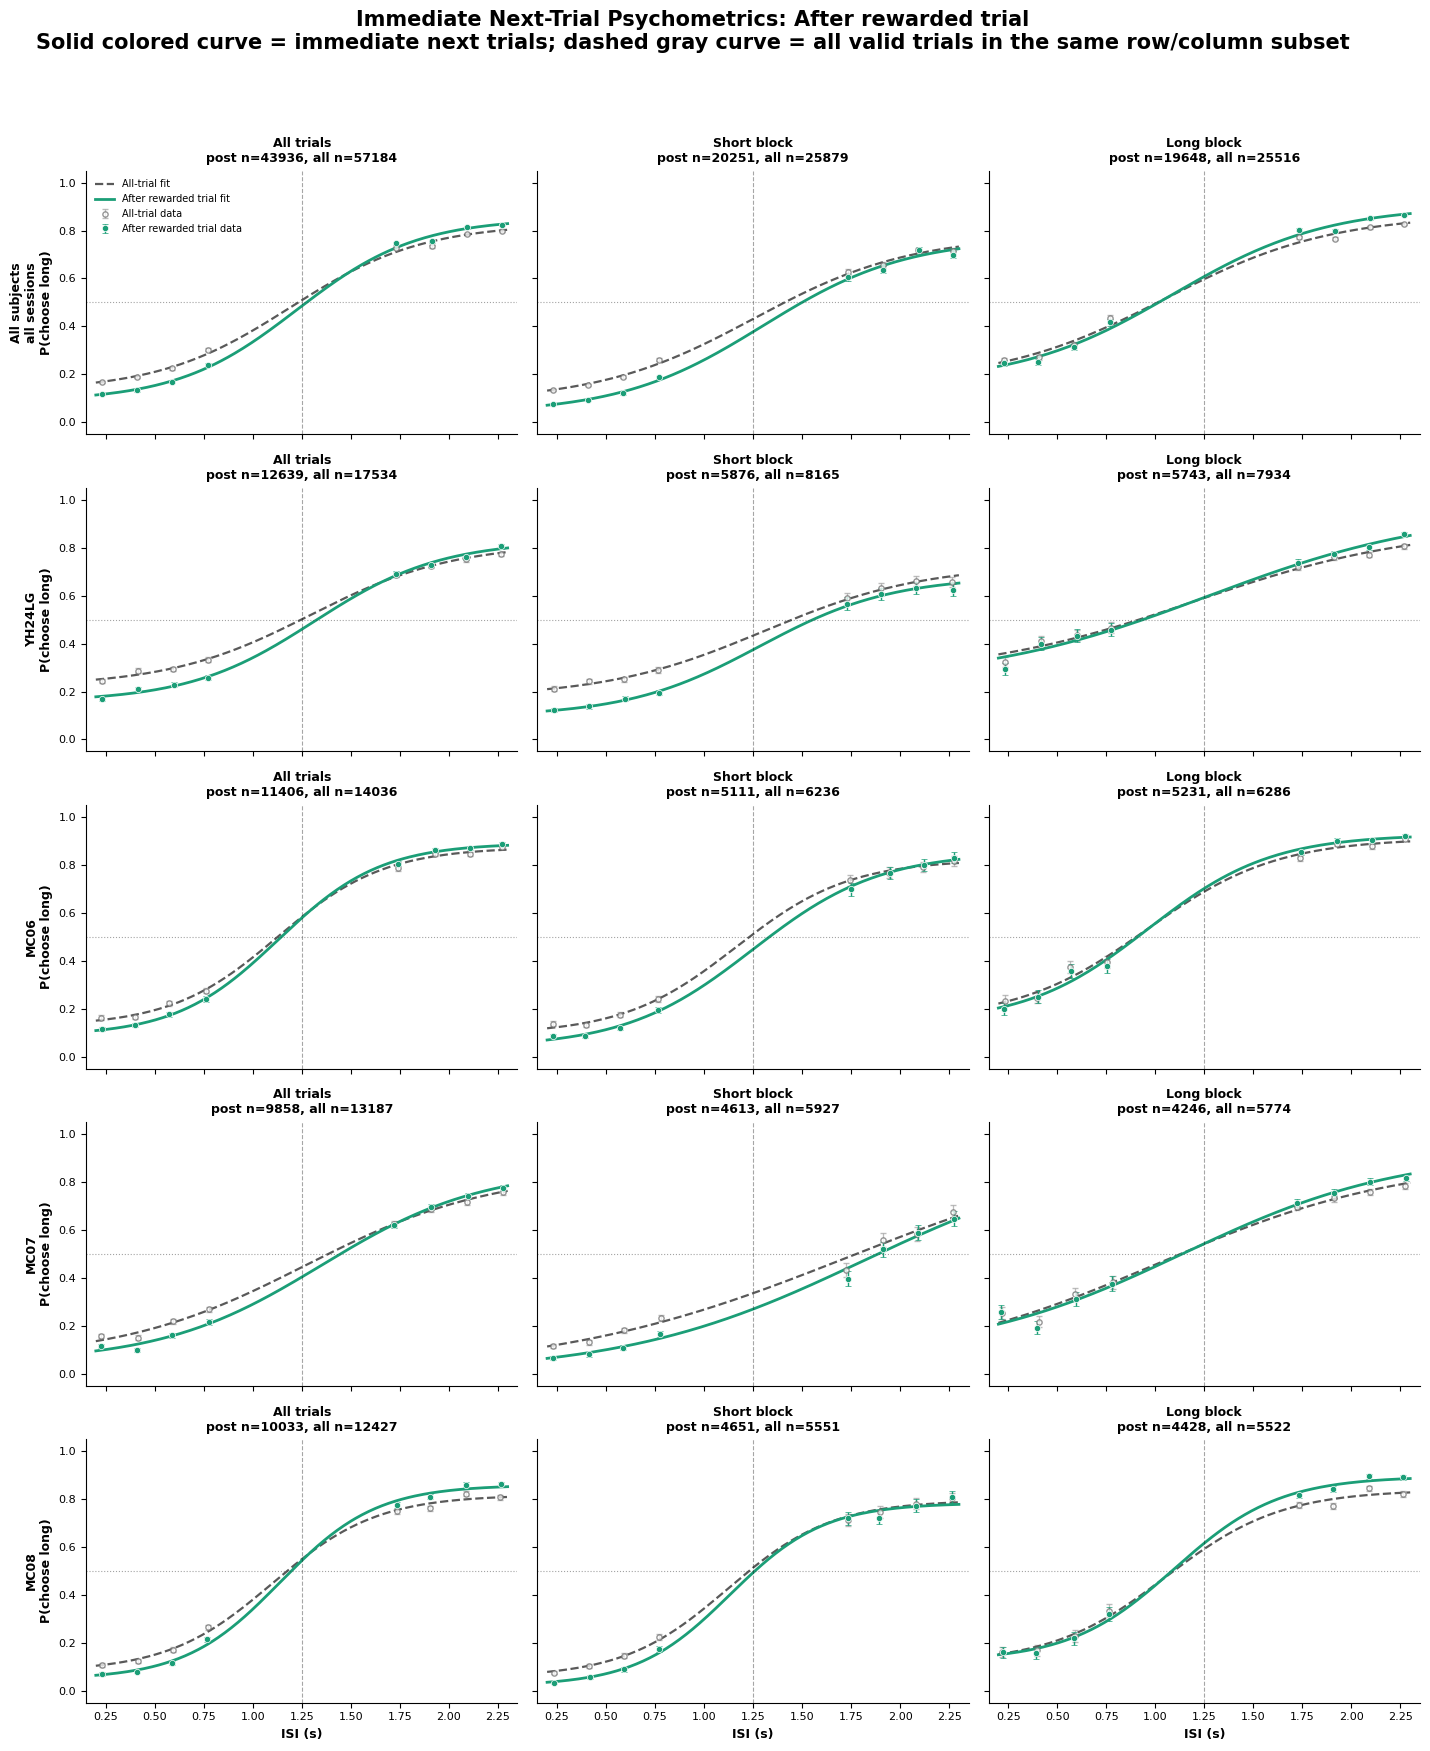

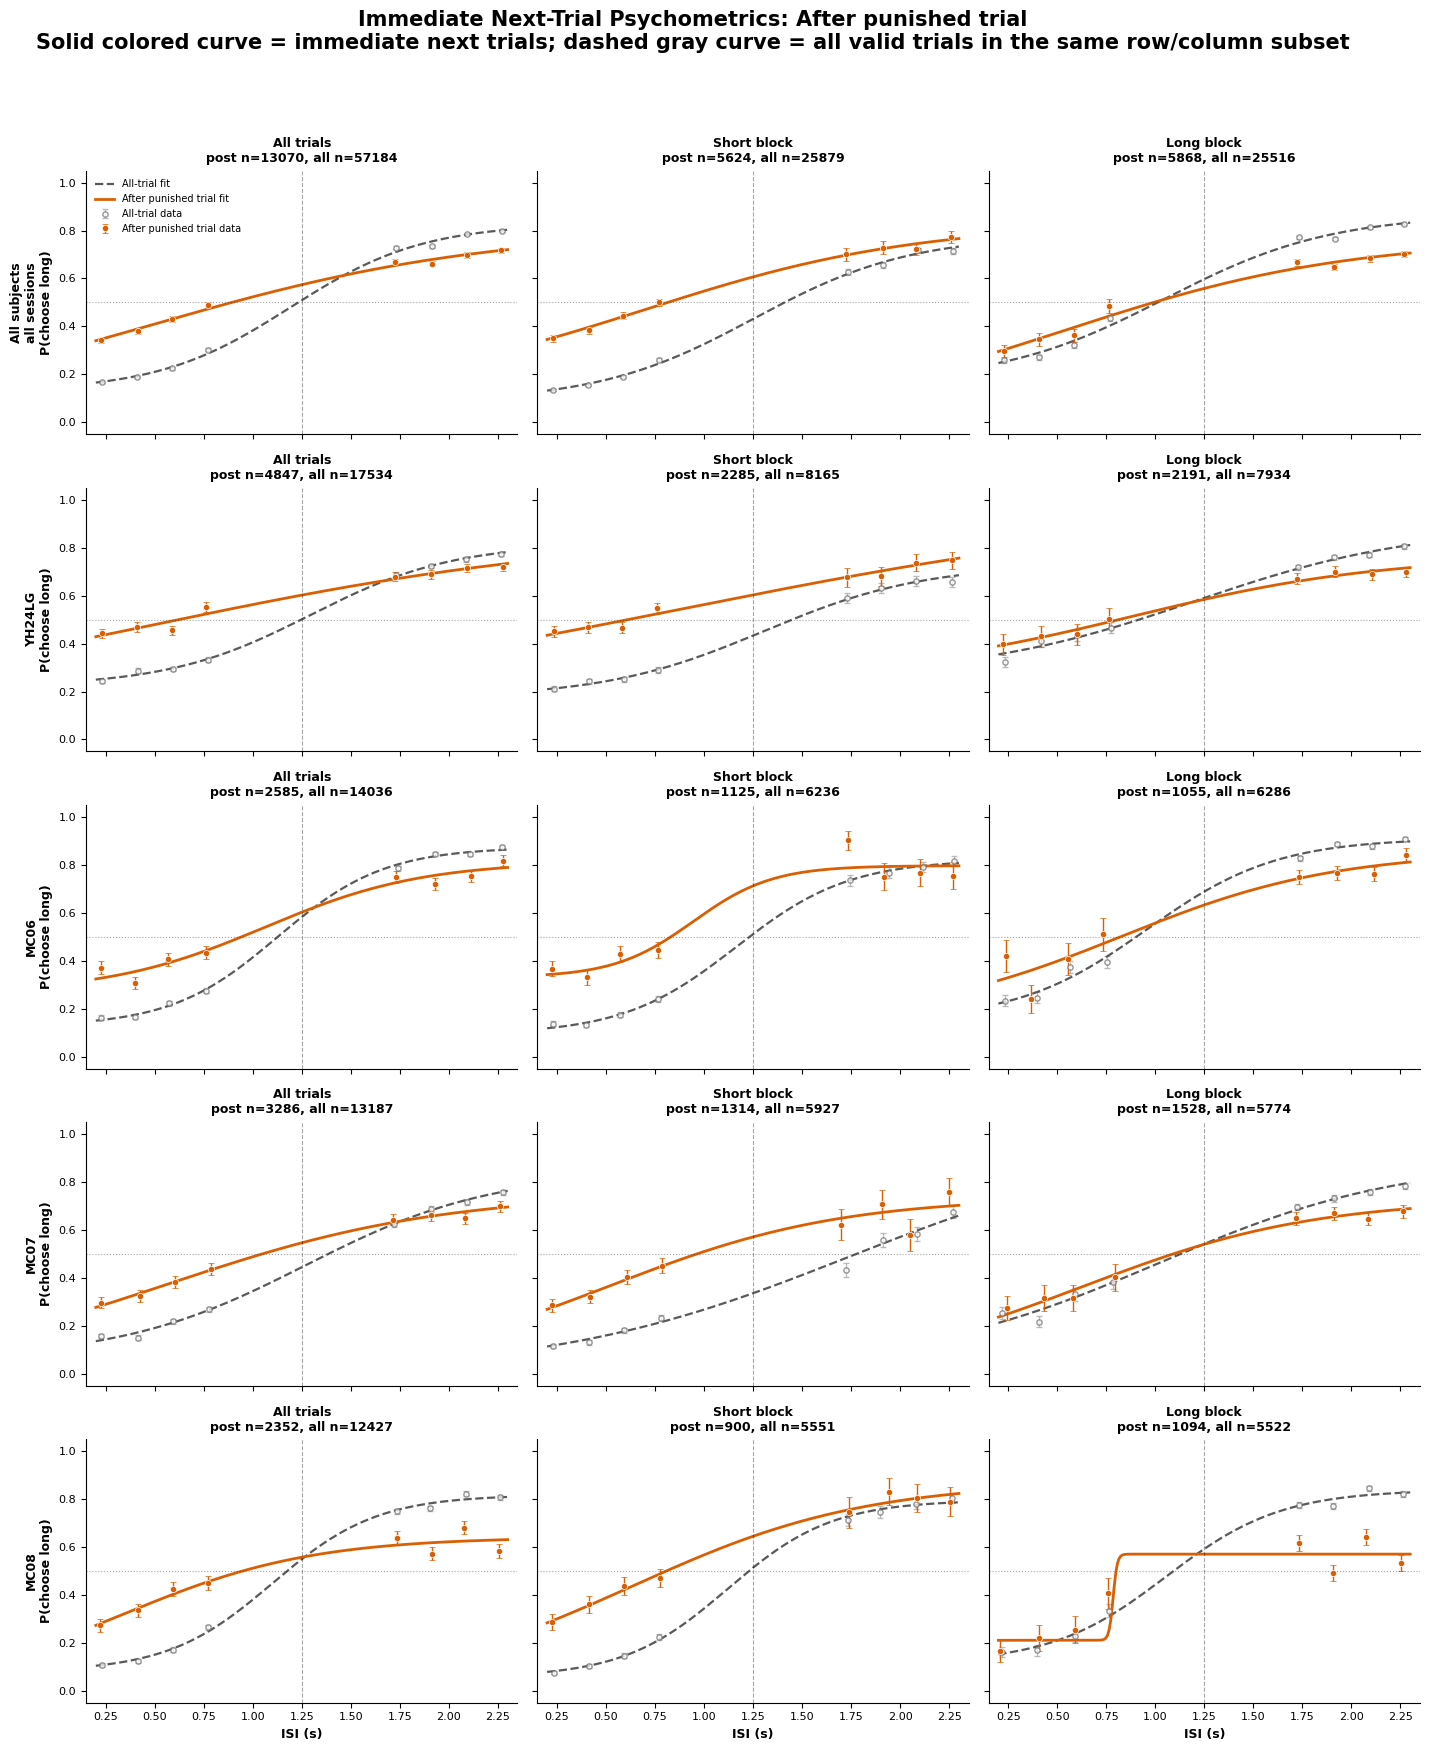

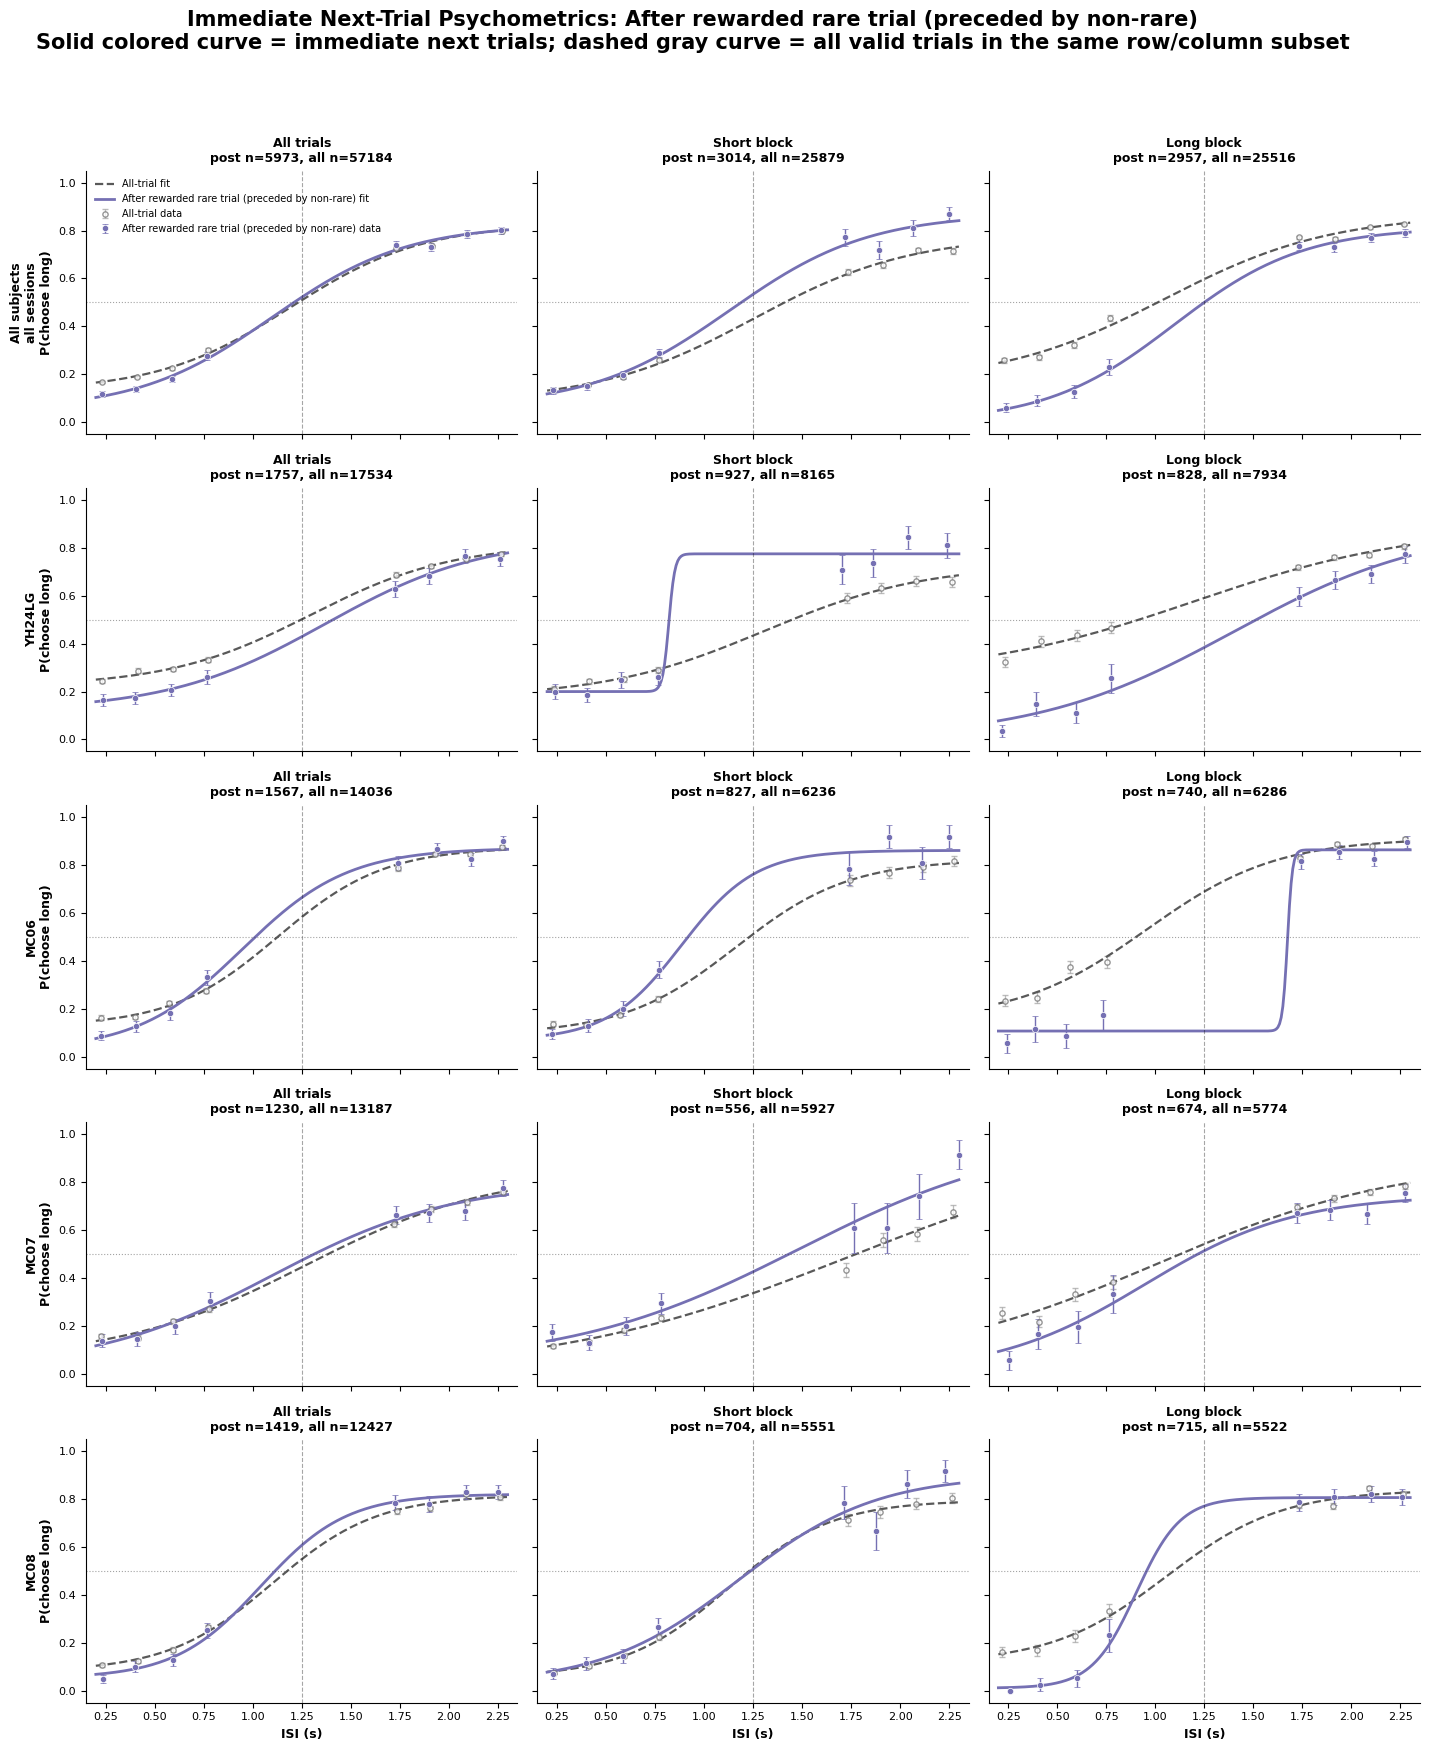

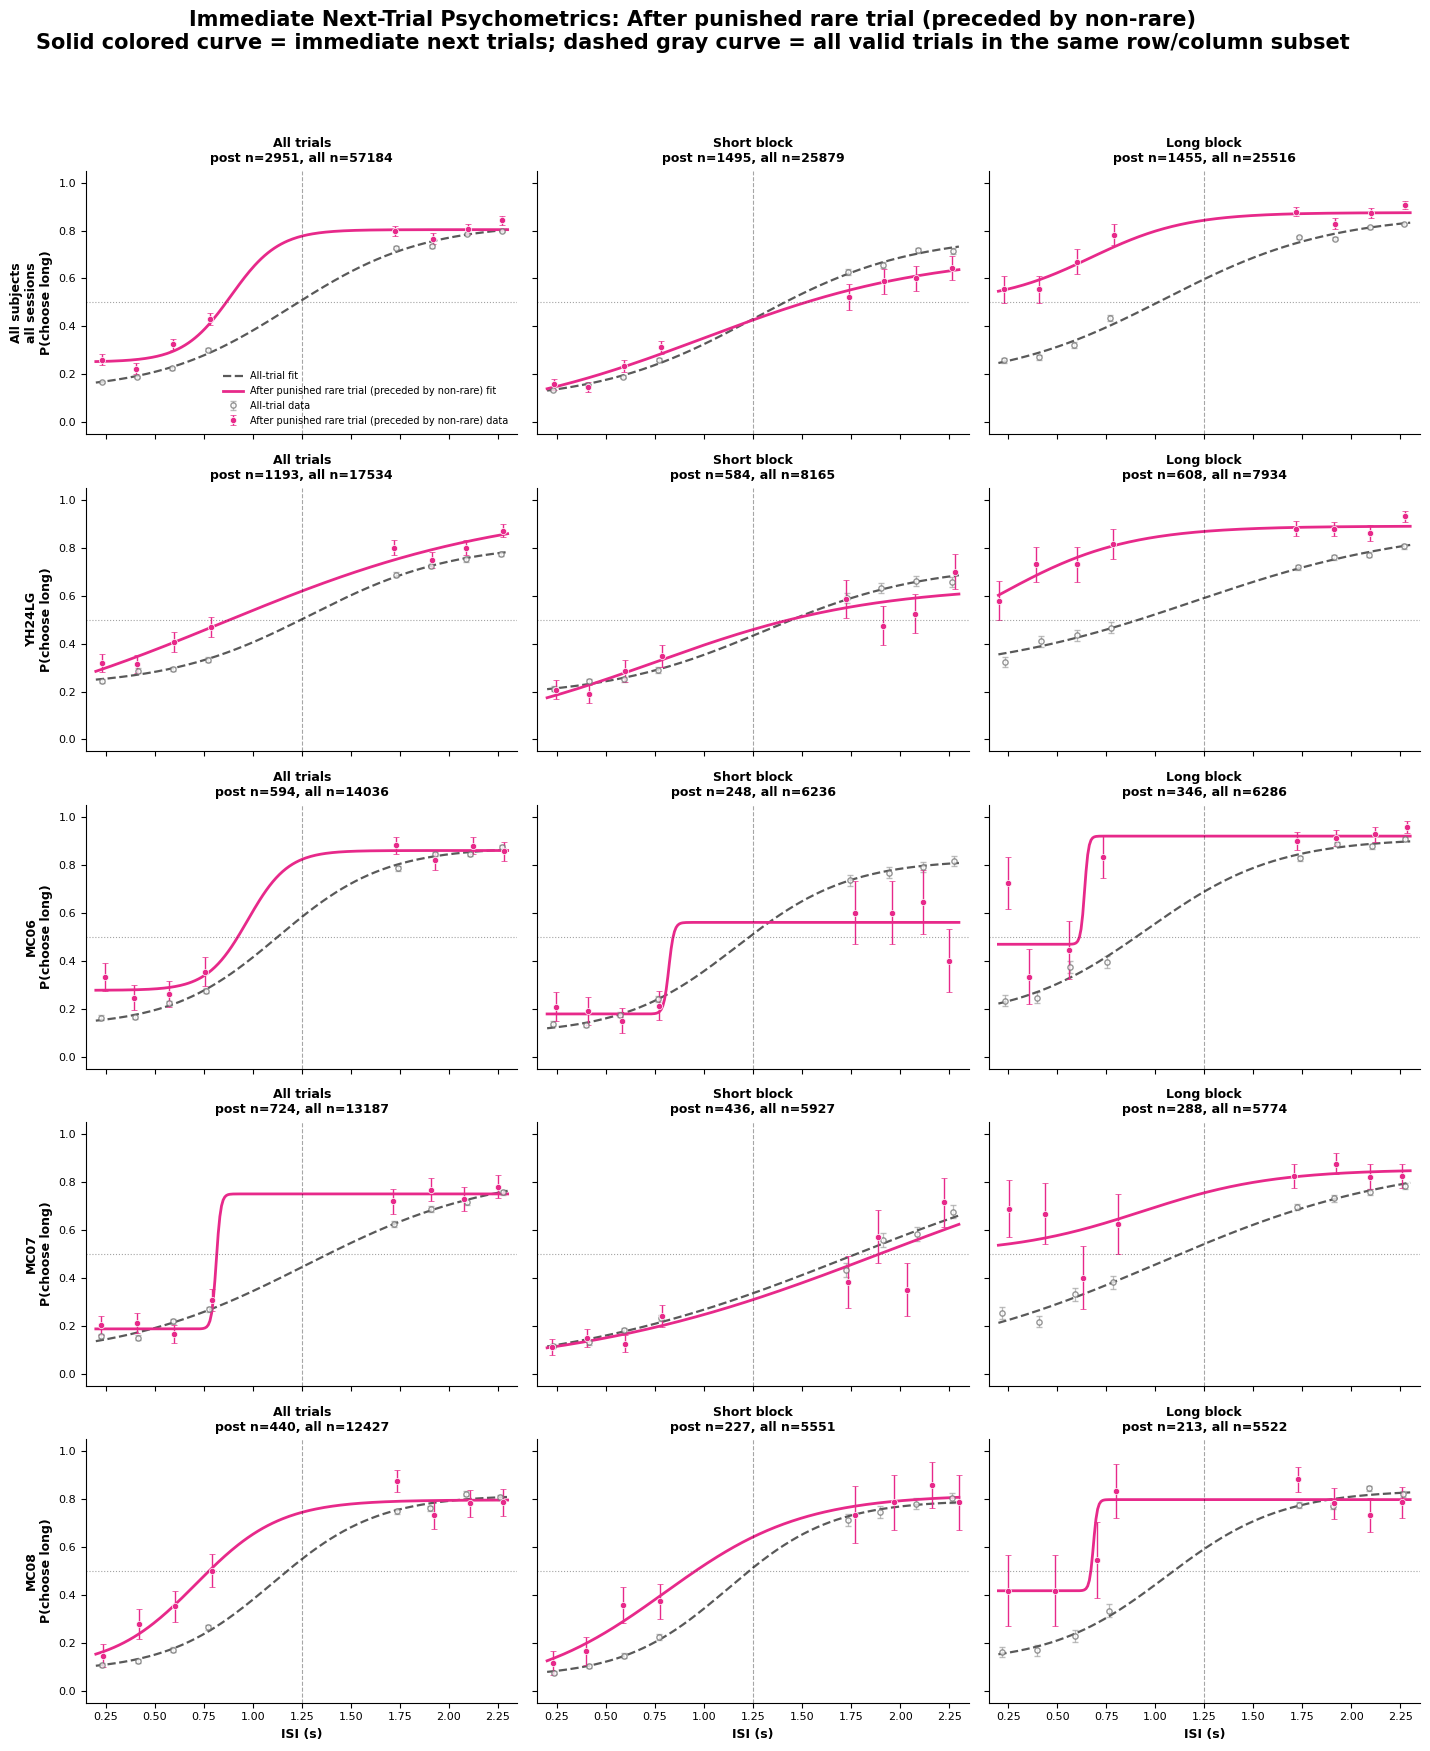

Saved /home/ihsan/Desktop/data/Georgia_Tech/2AFC/Figures_behavior/Mega_pdf/immediate_post_outcome_psychometrics.pdf
                                            page                       row      column  anchor_n  baseline_n  anchor_pse  baseline_pse
                            After rewarded trial All subjects all sessions  All trials     43936       57184    1.225384      1.192456
                            After rewarded trial All subjects all sessions Short block     20251       25879    1.301044      1.255054
                            After rewarded trial All subjects all sessions  Long block     19648       25516    1.088282      1.050101
                            After rewarded trial                    YH24LG  All trials     12639       17534    1.315266      1.294676
                            After rewarded trial                    YH24LG Short block      5876        8165    1.281960      1.307511
                            After rewarded trial                    YH24LG

,baseline_n,anchor_n,baseline_pse,baseline_slope,baseline_log_likelihood,anchor_pse,anchor_slope,anchor_log_likelihood,page,row,column,subject,block_type
0,57184,43936,1.192456,2.959845,-30529.406089,1.225384,3.266809,-21031.265600,After rewarded trial,All subjects all sessions,All trials,All,All
1,25879,20251,1.255054,2.501534,-13126.520132,1.301044,2.742711,-8519.889830,After rewarded trial,All subjects all sessions,Short block,All,1
2,25516,19648,1.050101,2.358048,-13556.617204,1.088282,2.546223,-9577.738835,After rewarded trial,All subjects all sessions,Long block,All,2
3,17534,12639,1.294676,2.747981,-10299.390535,1.315266,3.109559,-6827.225544,After rewarded trial,YH24LG,All trials,YH24LG,All
4,8165,5876,1.307511,2.440619,-4754.717012,1.281960,2.958434,-2884.843999,After rewarded trial,YH24LG,Short block,YH24LG,1
5,7934,5743,1.201319,1.760953,-4570.429701,1.269246,1.691304,-3141.311955,After rewarded trial,YH24LG,Long block,YH24LG,2
6,14036,11406,1.127776,3.669383,-6620.491298,1.131207,3.828584,-4852.806537,After rewarded trial,MC06,All trials,MC06,All
7,6236,5111,1.164264,3.460029,-2903.463931,1.247647,3.079968,-2026.028747,After rewarded trial,MC06,Short block,MC06,1
8,6286,5231,0.958112,3.018833,-2682.214483,0.964370,3.198860,-2056.316480,After rewarded trial,MC06,Long block,MC06,2
9,13187,9858,1.269217,2.102766,-7227.097525,1.351642,2.442487,-4930.440686,After rewarded trial,MC07,All trials,MC07,All


In [1]:
# Immediate post-outcome psychometrics: rewarded and punished anchors
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy.optimize import curve_fit
from scipy.special import expit

POST_OUTCOME_CSV_PATH = "/home/ihsan/Desktop/data/Georgia_Tech/2AFC/Codes/Behavior/New_version/all_subjects_final_data.csv"
POST_OUTCOME_PDF_PATH = "/home/ihsan/Desktop/data/Georgia_Tech/2AFC/Figures_behavior/Mega_pdf/immediate_post_outcome_psychometrics.pdf"
POST_OUTCOME_N_BINS_PER_TYPE = 4
POST_OUTCOME_MIN_FIT_TRIALS = 10

POST_OUTCOME_REWARDED = {"Reward", "RewardNaive", "ChangingMindReward"}
POST_OUTCOME_PUNISHED = {"Punish", "PunishNaive"}

POST_OUTCOME_ROWS = [
    ("All subjects\nall sessions", None),
    ("YH24LG", "YH24LG"),
    ("MC06", "MC06"),
    ("MC07", "MC07"),
    ("MC08", "MC08"),
]
POST_OUTCOME_COLUMNS = [
    ("All trials", None),
    ("Short block", 1),
    ("Long block", 2),
]
POST_OUTCOME_PAGE_SPECS = [
    ("After rewarded trial", POST_OUTCOME_REWARDED, "#1b9e77", False),
    ("After punished trial", POST_OUTCOME_PUNISHED, "#d95f02", False),
    ("After rewarded rare trial (preceded by non-rare)", POST_OUTCOME_REWARDED, "#7570b3", True),
    ("After punished rare trial (preceded by non-rare)", POST_OUTCOME_PUNISHED, "#e7298a", True),
]


def post_outcome_logist(x, alpha, beta, lam, gamma):
    return lam + (1 - lam - gamma) * expit(beta * (x - alpha))


def post_outcome_add_session_key(df):
    df = df.copy()
    if "session_uid" in df.columns:
        df["post_outcome_session"] = df["session_uid"].astype(str)
    elif {"subject", "subject_session_idx"}.issubset(df.columns):
        df["post_outcome_session"] = (
            df["subject"].astype(str) + "_S" + df["subject_session_idx"].astype(str)
        )
    elif {"subject", "session_idx"}.issubset(df.columns):
        df["post_outcome_session"] = (
            df["subject"].astype(str) + "_S" + df["session_idx"].astype(str)
        )
    elif "session_idx" in df.columns:
        df["post_outcome_session"] = df["session_idx"].astype(str)
    else:
        df["post_outcome_session"] = "session_1"
    return df


def post_outcome_add_target_choice(df):
    df = df.copy()
    choice = df["lick_side"].astype(str).str.strip().str.lower()
    valid_choice = choice.isin(["left", "right"])

    normal = pd.Series(False, index=df.index)
    reverse = pd.Series(False, index=df.index)
    if "Contingency_idx" in df.columns:
        contingency_idx = pd.to_numeric(df["Contingency_idx"], errors="coerce")
        normal = normal | contingency_idx.eq(1)
        reverse = reverse | contingency_idx.eq(2)
    if "Contingency" in df.columns:
        contingency_text = df["Contingency"].astype(str).str.lower()
        reverse = reverse | contingency_text.str.contains("reverse", na=False)
        normal = normal | contingency_text.str.contains("normal", na=False)

    # If contingency metadata is absent, use the normal mapping: long choice is right.
    unknown = ~(normal | reverse)
    normal = normal | unknown

    df["target_choice"] = np.nan
    df.loc[normal & valid_choice, "target_choice"] = choice[normal & valid_choice].eq("right").astype(int)
    df.loc[reverse & valid_choice, "target_choice"] = choice[reverse & valid_choice].eq("left").astype(int)
    return df


def prepare_post_outcome_dataframe(csv_path=POST_OUTCOME_CSV_PATH):
    required = {"subject", "trial_isi", "trial_type", "block_type", "outcome", "lick_side"}
    df = pd.read_csv(csv_path).copy()
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    df["_source_order"] = np.arange(len(df))
    for column in ["trial_isi", "trial_type", "block_type", "warm_up", "Contingency_idx"]:
        if column in df.columns:
            df[column] = pd.to_numeric(df[column], errors="coerce")

    if "warm_up" in df.columns:
        df = df[df["warm_up"].fillna(0).eq(0)].copy()

    df = post_outcome_add_session_key(df)

    # Build raw-sequence anchor metadata before removing trials with unusable choices.
    # A rare short trial is trial_type 1 in a long block; a rare long trial is
    # trial_type 2 in a short block. Shifts are strictly within session.
    df = df.sort_values(["post_outcome_session", "_source_order"]).copy()
    df["post_outcome_is_rare"] = (
        (df["block_type"].eq(2) & df["trial_type"].eq(1))
        | (df["block_type"].eq(1) & df["trial_type"].eq(2))
    )
    raw_group = df.groupby("post_outcome_session", sort=False)
    df["raw_prev_outcome"] = raw_group["outcome"].shift(1)
    df["raw_prev_is_rare"] = raw_group["post_outcome_is_rare"].shift(1)
    df["raw_prev_prev_is_rare"] = raw_group["post_outcome_is_rare"].shift(2)
    df["raw_prev_order"] = raw_group["_source_order"].shift(1)
    df["raw_prev_prev_order"] = raw_group["_source_order"].shift(2)

    df = post_outcome_add_target_choice(df)
    df = df.dropna(subset=["trial_isi", "trial_type", "block_type", "target_choice"]).copy()
    df["target_choice"] = df["target_choice"].astype(int)
    df["trial_type"] = df["trial_type"].astype(int)
    df["block_type"] = df["block_type"].astype(int)

    df = df.sort_values(["post_outcome_session", "_source_order"]).copy()
    df["prev_outcome"] = df.groupby("post_outcome_session", sort=False)["outcome"].shift(1)
    df["prev_trial_order"] = df.groupby("post_outcome_session", sort=False)["_source_order"].shift(1)
    return df


def post_outcome_boundary(data, default=1.25):
    if "isi_devider" not in data.columns:
        return default
    values = pd.to_numeric(data["isi_devider"], errors="coerce").dropna()
    return float(values.median()) if not values.empty else default


def post_outcome_fit_data(data, boundary=1.25, min_trials=POST_OUTCOME_MIN_FIT_TRIALS):
    data = data.dropna(subset=["trial_isi", "target_choice"]).copy()
    if len(data) < min_trials or data["target_choice"].nunique() < 2:
        return np.full(4, np.nan), np.nan

    x = data["trial_isi"].to_numpy(dtype=float)
    y = data["target_choice"].to_numpy(dtype=float)
    x_min = float(np.nanmin(x))
    x_max = float(np.nanmax(x))
    if not np.isfinite(x_min) or not np.isfinite(x_max) or x_min == x_max:
        return np.full(4, np.nan), np.nan

    p0 = [float(np.clip(boundary, x_min, x_max)), 10.0, 0.05, 0.05]
    bounds = ([x_min, 0.0, 0.0, 0.0], [x_max, 100.0, 0.5, 0.5])
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            popt, _ = curve_fit(
                post_outcome_logist,
                x,
                y,
                p0=p0,
                bounds=bounds,
                maxfev=10000,
            )
        y_pred = np.clip(post_outcome_logist(x, *popt), 1e-5, 1 - 1e-5)
        log_likelihood = float(np.sum(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred)))
        return popt, log_likelihood
    except (RuntimeError, ValueError, FloatingPointError):
        return np.full(4, np.nan), np.nan


def post_outcome_binned_stats(data, n_bins_per_type=POST_OUTCOME_N_BINS_PER_TYPE):
    rows = []
    data = data.dropna(subset=["trial_isi", "target_choice"]).copy()
    for trial_type in [1, 2]:
        tt_data = data[data["trial_type"].eq(trial_type)].copy()
        if tt_data.empty:
            continue
        n_bins = min(max(int(n_bins_per_type), 1), len(tt_data))
        ranked_isi = tt_data["trial_isi"].rank(method="first")
        try:
            bins = pd.qcut(ranked_isi, q=n_bins, duplicates="drop")
        except ValueError:
            continue
        for _, group in tt_data.groupby(bins, observed=False):
            if group.empty:
                continue
            rows.append(
                {
                    "trial_type": trial_type,
                    "isi_mean": group["trial_isi"].mean(),
                    "p_long": group["target_choice"].mean(),
                    "p_sem": group["target_choice"].sem() if len(group) > 1 else 0.0,
                    "n_trials": len(group),
                }
            )
    return pd.DataFrame(rows).sort_values("isi_mean") if rows else pd.DataFrame()


def post_outcome_filter_row(data, subject):
    if subject is None:
        return data.copy()
    return data[data["subject"].astype(str).eq(subject)].copy()


def post_outcome_filter_column(data, block_type):
    if block_type is None:
        return data.copy()
    return data[data["block_type"].eq(block_type)].copy()


def post_outcome_anchor_trials(data, anchor_outcomes, rare_anchor=False):
    if not rare_anchor:
        # Preserve the original selection logic for pages 1 and 2.
        return data[data["prev_outcome"].isin(anchor_outcomes)].copy()

    # Current row is trial +1, raw_prev is the rare outcome anchor (trial 0),
    # and raw_prev_prev is trial -1, which must explicitly be non-rare.
    consecutive = (
        data["_source_order"].sub(data["raw_prev_order"]).eq(1)
        & data["raw_prev_order"].sub(data["raw_prev_prev_order"]).eq(1)
    )
    mask = (
        data["raw_prev_outcome"].isin(anchor_outcomes)
        & data["raw_prev_is_rare"].eq(True)
        & data["raw_prev_prev_is_rare"].eq(False)
        & consecutive
    )
    return data[mask].copy()


def post_outcome_style_axis(ax, x_min=None, x_max=None):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim(-0.05, 1.05)
    if x_min is not None and x_max is not None and x_min < x_max:
        ax.set_xlim(x_min, x_max)
    ax.axhline(0.5, color="0.2", linestyle=":", linewidth=0.8, alpha=0.45)
    ax.tick_params(axis="both", labelsize=8)


def post_outcome_plot_psychometric(
    ax,
    baseline_data,
    anchor_data,
    anchor_label,
    anchor_color,
    panel_title,
    overall_data=None,
    show_legend=False,
):
    boundary = post_outcome_boundary(baseline_data if not baseline_data.empty else anchor_data)
    raw_sources = [baseline_data, anchor_data]
    if overall_data is not None:
        raw_sources.append(overall_data)
    raw_isi = pd.concat([source['trial_isi'] for source in raw_sources], ignore_index=True)
    raw_isi = pd.to_numeric(raw_isi, errors='coerce').dropna()
    x_min, x_max = float(raw_isi.min()), float(raw_isi.max())
    x_fit = np.linspace(x_min, x_max, 250) if x_min < x_max else np.array([x_min])

    baseline_fit, baseline_ll = post_outcome_fit_data(baseline_data, boundary=boundary)
    anchor_fit, anchor_ll = post_outcome_fit_data(anchor_data, boundary=boundary)
    overall_fit, overall_ll = (
        post_outcome_fit_data(overall_data, boundary=boundary)
        if overall_data is not None
        else (np.full(4, np.nan), np.nan)
    )

    # Block panels keep their existing block baseline and add the row-level
    # all-blocks/all-trials fit as a third reference trace.
    if overall_data is not None and np.isfinite(overall_fit[0]):
        ax.plot(
            x_fit,
            post_outcome_logist(x_fit, *overall_fit),
            color="0.7",
            linewidth=1.5,
            linestyle=":",
            label="All blocks, all-trial fit" if show_legend else None,
        )

    baseline_stats = post_outcome_binned_stats(baseline_data)
    if not baseline_stats.empty:
        ax.errorbar(
            baseline_stats["isi_mean"],
            baseline_stats["p_long"],
            yerr=baseline_stats["p_sem"].fillna(0),
            fmt="o",
            markersize=3.8,
            color="0.45",
            ecolor="0.65",
            markerfacecolor="white",
            markeredgecolor="0.45",
            elinewidth=0.9,
            capsize=2,
            alpha=0.75,
            label=f"{panel_title} all-trial data" if show_legend else None,
        )
    if np.isfinite(baseline_fit[0]):
        ax.plot(
            x_fit,
            post_outcome_logist(x_fit, *baseline_fit),
            color="0.35",
            linewidth=1.6,
            linestyle="--",
            label=f"{panel_title} all-trial fit" if show_legend else None,
        )

    anchor_stats = post_outcome_binned_stats(anchor_data)
    if not anchor_stats.empty:
        ax.errorbar(
            anchor_stats["isi_mean"],
            anchor_stats["p_long"],
            yerr=anchor_stats["p_sem"].fillna(0),
            fmt="o",
            markersize=4.5,
            color=anchor_color,
            ecolor=anchor_color,
            markeredgecolor="white",
            markeredgewidth=0.5,
            elinewidth=1.0,
            capsize=2.5,
            label=f"{anchor_label} data" if show_legend else None,
        )
    if np.isfinite(anchor_fit[0]):
        ax.plot(
            x_fit,
            post_outcome_logist(x_fit, *anchor_fit),
            color=anchor_color,
            linewidth=2.0,
            label=f"{anchor_label} fit" if show_legend else None,
        )
    elif anchor_data.empty:
        ax.text(0.5, 0.5, "No anchor trials", transform=ax.transAxes, ha="center", va="center", fontsize=8)

    ax.axvline(boundary, color="k", linestyle="--", linewidth=0.8, alpha=0.35)
    baseline_count_label = "block all" if overall_data is not None else "all"
    overall_count = f", overall all n={len(overall_data)}" if overall_data is not None else ""
    ax.set_title(
        f"{panel_title}\npost n={len(anchor_data)}, {baseline_count_label} n={len(baseline_data)}{overall_count}",
        fontsize=9,
        fontweight="bold",
    )
    post_outcome_style_axis(ax, x_min, x_max)
    if show_legend:
        ax.legend(frameon=False, fontsize=7, loc="best")

    return {
        "baseline_n": int(len(baseline_data)),
        "anchor_n": int(len(anchor_data)),
        "baseline_pse": float(baseline_fit[0]) if np.isfinite(baseline_fit[0]) else np.nan,
        "baseline_slope": float(baseline_fit[1]) if np.isfinite(baseline_fit[1]) else np.nan,
        "baseline_log_likelihood": baseline_ll,
        "anchor_pse": float(anchor_fit[0]) if np.isfinite(anchor_fit[0]) else np.nan,
        "anchor_slope": float(anchor_fit[1]) if np.isfinite(anchor_fit[1]) else np.nan,
        "anchor_log_likelihood": anchor_ll,
        "overall_n": int(len(overall_data)) if overall_data is not None else np.nan,
        "overall_pse": float(overall_fit[0]) if np.isfinite(overall_fit[0]) else np.nan,
        "overall_slope": float(overall_fit[1]) if np.isfinite(overall_fit[1]) else np.nan,
        "overall_log_likelihood": overall_ll,
    }


def make_post_outcome_psychometric_pdf(
    csv_path=POST_OUTCOME_CSV_PATH,
    output_path=POST_OUTCOME_PDF_PATH,
    show=True,
):
    data = prepare_post_outcome_dataframe(csv_path)
    fit_rows = []
    output_path = Path(output_path)

    with PdfPages(output_path) as pdf:
        for page_label, anchor_outcomes, anchor_color, rare_anchor in POST_OUTCOME_PAGE_SPECS:
            fig, axes = plt.subplots(
                nrows=len(POST_OUTCOME_ROWS),
                ncols=len(POST_OUTCOME_COLUMNS),
                figsize=(15, 18),
                sharex=True,
                sharey=True,
            )
            fig.suptitle(
                f"Immediate Next-Trial Psychometrics: {page_label}\n"
                "Solid colored = immediate next trials; dashed gray = same-column all trials; dotted light gray = all-blocks/all-trials reference",
                fontsize=15,
                fontweight="bold",
                y=0.995,
            )

            for row_index, (row_label, subject) in enumerate(POST_OUTCOME_ROWS):
                row_data = post_outcome_filter_row(data, subject)
                for col_index, (column_label, block_type) in enumerate(POST_OUTCOME_COLUMNS):
                    ax = axes[row_index, col_index]
                    baseline_data = post_outcome_filter_column(row_data, block_type)
                    anchor_data = post_outcome_anchor_trials(
                        baseline_data, anchor_outcomes, rare_anchor=rare_anchor
                    )
                    stats_row = post_outcome_plot_psychometric(
                        ax,
                        baseline_data,
                        anchor_data,
                        page_label,
                        anchor_color,
                        column_label,
                        overall_data=row_data if block_type is not None else None,
                        show_legend=(row_index == 0),
                    )
                    stats_row.update(
                        {
                            "page": page_label,
                            "row": row_label.replace("\n", " "),
                            "column": column_label,
                            "subject": "All" if subject is None else subject,
                            "block_type": "All" if block_type is None else block_type,
                        }
                    )
                    fit_rows.append(stats_row)

                    if col_index == 0:
                        ax.set_ylabel(f"{row_label}\nP(choose long)", fontsize=9, fontweight="bold")
                    if row_index == len(POST_OUTCOME_ROWS) - 1:
                        ax.set_xlabel("ISI (s)", fontsize=9, fontweight="bold")

            fig.tight_layout(rect=[0.035, 0.025, 0.995, 0.965])
            pdf.savefig(fig, dpi=600, bbox_inches="tight")
            if show:
                plt.show()
            else:
                plt.close(fig)

    fit_stats = pd.DataFrame(fit_rows)
    print(f"Saved {output_path.resolve()}")
    print(fit_stats[["page", "row", "column", "anchor_n", "baseline_n", "anchor_pse", "baseline_pse"]].to_string(index=False))
    return output_path, fit_stats


post_outcome_pdf_path, post_outcome_fit_stats = make_post_outcome_psychometric_pdf(show=True)
try:
    display(post_outcome_fit_stats)
except NameError:
    pass


In [ ]:
# Pooled-trial and equal-session psychometrics by subject
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.backends.backend_pdf import PdfPages
from scipy.optimize import curve_fit
from scipy.special import expit

PG_DATA_PATH = Path('all_subjects_final_data.csv')
PG_OUTPUT_PATH = Path('pooled_grand_subject_psychometrics.pdf')
PG_XLIM = (0.1, 2.4)
PG_BOUNDARY = 1.25
PG_N_BINS = 4
PG_SUBJECT_ROWS = [
    ('All subjects — all sessions', None),
    ('YH24LG', 'YH24LG'),
    ('MC06', 'MC06'),
    ('MC07', 'MC07'),
    ('MC08', 'MC08'),
]
PG_BLOCKS = [('Neutral', 0, 'black'), ('Short', 1, '#BCAE3E'), ('Long', 2, 'blue')]
PG_COMMON_COLOR, PG_RARE_COLOR, PG_RT_COLOR = 'green', 'darkorange', 'purple'

def pg_logistic(x, alpha, beta, lam, gamma):
    return lam + (1 - lam - gamma) * expit(beta * (x - alpha))

def pg_prepare_data(path=PG_DATA_PATH):
    data = pd.read_csv(path).copy()
    required = {'subject', 'trial_isi', 'trial_type', 'block_type', 'lick_side'}
    missing = required.difference(data.columns)
    if missing:
        raise ValueError(f'Missing required columns: {sorted(missing)}')
    for column in ['trial_isi', 'trial_type', 'block_type', 'lick_reaction_time']:
        if column in data.columns:
            data[column] = pd.to_numeric(data[column], errors='coerce')
    choice = data['lick_side'].astype(str).str.strip().str.lower()
    if 'Contingency' in data.columns:
        contingency = data['Contingency'].astype(str)
        normal = contingency.str.contains('Normal - Short/Left', na=False)
        reverse = contingency.str.contains('Reverse - Long/Left', na=False)
    else:
        contingency_idx = pd.to_numeric(data.get('Contingency_idx', 1), errors='coerce')
        normal, reverse = contingency_idx.eq(1), contingency_idx.eq(2)
    normal = normal | ~(normal | reverse)
    data['target_choice'] = np.nan
    data.loc[normal, 'target_choice'] = choice[normal].eq('right').astype(float)
    data.loc[reverse, 'target_choice'] = choice[reverse].eq('left').astype(float)
    data = data.dropna(subset=['trial_isi', 'trial_type', 'block_type', 'target_choice']).copy()
    if 'session_uid' in data.columns:
        data['pg_session'] = data['session_uid'].astype(str)
    elif {'subject', 'subject_session_idx'}.issubset(data.columns):
        data['pg_session'] = data['subject'].astype(str) + '_S' + data['subject_session_idx'].astype(str)
    else:
        data['pg_session'] = data['subject'].astype(str) + '_S' + data['session_idx'].astype(str)
    data['is_common'] = np.nan
    data.loc[(data['block_type'].eq(1) & data['trial_type'].eq(1)) |
             (data['block_type'].eq(2) & data['trial_type'].eq(2)), 'is_common'] = 1
    data.loc[(data['block_type'].eq(1) & data['trial_type'].eq(2)) |
             (data['block_type'].eq(2) & data['trial_type'].eq(1)), 'is_common'] = 0
    return data

def pg_fit(data, mode='pooled'):
    fit_data = data.dropna(subset=['trial_isi', 'target_choice']).copy()
    if mode == 'grand':
        fit_data = fit_data.groupby(['pg_session', 'trial_isi'], as_index=False)['target_choice'].mean()
    if len(fit_data) < 10 or fit_data['target_choice'].nunique() < 2:
        return np.full(4, np.nan), np.full(4, np.nan)
    x = fit_data['trial_isi'].to_numpy(float)
    y = fit_data['target_choice'].to_numpy(float)
    try:
        popt, pcov = curve_fit(
            pg_logistic, x, y, p0=[PG_BOUNDARY, 10, 0.05, 0.05],
            bounds=([x.min(), 0, 0, 0], [x.max(), 100, 0.5, 0.5]), maxfev=20000,
        )
        return popt, np.sqrt(np.diag(pcov))
    except (RuntimeError, ValueError, FloatingPointError):
        return np.full(4, np.nan), np.full(4, np.nan)

def pg_binned_stats(data, value_column='target_choice', mode='pooled', n_bins=PG_N_BINS):
    rows = []
    for trial_type in [1, 2]:
        part = data[data['trial_type'].eq(trial_type)].dropna(subset=['trial_isi', value_column]).copy()
        if part.empty:
            continue
        q = min(n_bins, len(part))
        try:
            part['_pg_bin'] = pd.qcut(part['trial_isi'].rank(method='first'), q=q, duplicates='drop')
        except ValueError:
            continue
        if mode == 'grand':
            units = part.groupby(['pg_session', '_pg_bin'], observed=True).agg(
                isi=('trial_isi', 'mean'), value=(value_column, 'mean')
            ).reset_index()
            grouped = units.groupby('_pg_bin', observed=True)
            for _, group in grouped:
                rows.append({'isi': group['isi'].mean(), 'mean': group['value'].mean(),
                             'sem': group['value'].sem() if len(group) > 1 else 0.0})
        else:
            for _, group in part.groupby('_pg_bin', observed=True):
                rows.append({'isi': group['trial_isi'].mean(), 'mean': group[value_column].mean(),
                             'sem': group[value_column].sem() if len(group) > 1 else 0.0})
    return pd.DataFrame(rows).sort_values('isi') if rows else pd.DataFrame()

def pg_has_negative_lick(value):
    if pd.isna(value):
        return False
    try:
        values = ast.literal_eval(value) if isinstance(value, str) else value
    except (ValueError, SyntaxError):
        return False
    values = values if isinstance(values, (list, tuple, np.ndarray)) else [values]
    for item in values:
        try:
            if pd.notna(item) and float(item) < 0:
                return True
        except (TypeError, ValueError):
            continue
    return False

def pg_rt_data(data):
    rt = data.dropna(subset=['lick_reaction_time']).copy()
    columns = [c for c in ['all_lick_start_times_from_choice', 'all_lick_reaction_times'] if c in rt.columns]
    if columns:
        negative = pd.Series(False, index=rt.index)
        for column in columns:
            negative |= rt[column].apply(pg_has_negative_lick)
        rt = rt.loc[~negative].copy()
    return rt

def pg_style_psychometric(ax, title):
    ax.set_xlim(*PG_XLIM)
    ax.set_ylim(-0.05, 1.05)
    ax.axvline(PG_BOUNDARY, color='k', linestyle='--', alpha=0.3, linewidth=0.8)
    ax.axhline(0.5, color='k', linestyle='--', alpha=0.3, linewidth=0.8)
    ax.set_xlabel('ISI (s)')
    ax.set_ylabel('P(Choose Long-Associated Response)')
    ax.set_title(title, fontsize=9)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False); ax.grid(False)

def pg_plot_curve(ax, data, mode, color, label, linestyle='-', plot_data=True):
    if plot_data:
        stats = pg_binned_stats(data, mode=mode)
        if not stats.empty:
            ax.errorbar(stats['isi'], stats['mean'], yerr=stats['sem'].fillna(0), fmt='o',
                        color=color, alpha=0.7, markersize=3.5, capsize=2)
    popt, perr = pg_fit(data, mode)
    if np.isfinite(popt[0]):
        x_fit = np.linspace(PG_XLIM[0], PG_XLIM[1], 250)
        ax.plot(x_fit, pg_logistic(x_fit, *popt), color=color, linestyle=linestyle,
                linewidth=1.8, label=f'{label} (n={len(data):,})')
    return popt, perr

def pg_plot_psychometric_row(axes, data, mode):
    pg_plot_curve(axes[0], data, mode, 'black', 'All')
    pg_style_psychometric(axes[0], 'All blocks')
    for name, block_type, color in PG_BLOCKS:
        pg_plot_curve(axes[1], data[data['block_type'].eq(block_type)], mode, color, name)
    pg_style_psychometric(axes[1], 'Neutral / short / long overlay')
    pg_plot_curve(axes[2], data[data['block_type'].eq(1)], mode, '#BCAE3E', 'Short block')
    pg_style_psychometric(axes[2], 'Short block')
    pg_plot_curve(axes[3], data[data['block_type'].eq(2)], mode, 'blue', 'Long block')
    pg_style_psychometric(axes[3], 'Long block')
    pg_plot_curve(axes[4], data[data['is_common'].eq(1)], mode, PG_COMMON_COLOR, 'Common')
    pg_plot_curve(axes[4], data[data['is_common'].eq(0)], mode, PG_RARE_COLOR, 'Rare')
    pg_style_psychometric(axes[4], 'Common versus rare')
    rt = pg_rt_data(data)
    rt_stats = pg_binned_stats(rt, value_column='lick_reaction_time', mode=mode)
    if not rt_stats.empty:
        axes[5].errorbar(rt_stats['isi'], rt_stats['mean'], yerr=rt_stats['sem'].fillna(0),
                         fmt='o-', color=PG_RT_COLOR, markersize=3.5, capsize=2)
    axes[5].set_xlim(*PG_XLIM); axes[5].set_xlabel('ISI (s)'); axes[5].set_ylabel('Reaction time (s)')
    axes[5].set_title('Reaction time', fontsize=9)
    axes[5].spines['top'].set_visible(False); axes[5].spines['right'].set_visible(False); axes[5].grid(False)
    for ax in axes[:5]:
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(handles, labels, frameon=False, fontsize=5.5, loc='best')

def pg_pooled_parameter_table(data):
    rows = []
    for name, block_type, color in PG_BLOCKS:
        popt, perr = pg_fit(data[data['block_type'].eq(block_type)], 'pooled')
        rows.append({'Block': name, 'Color': color,
                     'PSE': popt[0], 'PSE_err': perr[0], 'Slope': popt[1], 'Slope_err': perr[1],
                     'Lower lapse': popt[2], 'Lower lapse_err': perr[2],
                     'Upper lapse': popt[3], 'Upper lapse_err': perr[3]})
    return pd.DataFrame(rows)

def pg_session_parameter_table(data):
    rows = []
    for session, session_data in data.groupby('pg_session', sort=False):
        for name, block_type, color in PG_BLOCKS:
            popt, _ = pg_fit(session_data[session_data['block_type'].eq(block_type)], 'pooled')
            if np.isfinite(popt[0]):
                rows.append({'Session': session, 'Block': name, 'Color': color,
                             'PSE': popt[0], 'Slope': popt[1],
                             'Lower lapse': popt[2], 'Upper lapse': popt[3]})
    return pd.DataFrame(rows)

def pg_plot_parameter_row(axes, data, mode):
    parameters = ['PSE', 'Slope', 'Lower lapse', 'Upper lapse']
    pooled = pg_pooled_parameter_table(data) if mode == 'pooled' else None
    sessions = pg_session_parameter_table(data) if mode == 'grand' else None
    for ax, parameter in zip(axes[:4], parameters):
        for x, (name, _, color) in enumerate(PG_BLOCKS):
            if mode == 'pooled':
                row = pooled[pooled['Block'].eq(name)].iloc[0]
                mean, sem = row[parameter], row[f'{parameter}_err']
            else:
                values = sessions.loc[sessions['Block'].eq(name), parameter].dropna()
                mean = values.mean() if len(values) else np.nan
                sem = values.sem() if len(values) > 1 else (0.0 if len(values) else np.nan)
            ax.errorbar(x, mean, yerr=sem, fmt='o', color=color, markersize=6, capsize=4)
        ax.set_xticks(range(3), ['Neutral', 'Short', 'Long'], rotation=20)
        ax.set_title(f'{parameter} across sessions' if mode == 'grand' else f'{parameter} — pooled fit', fontsize=9)
        ax.set_ylabel(parameter)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False); ax.grid(False)
        if parameter == 'PSE':
            ax.axhline(PG_BOUNDARY, color='k', linestyle='--', alpha=0.4, linewidth=0.8)

def pg_make_page(data, mode):
    fig = plt.figure(figsize=(54, 27))
    gs = gridspec.GridSpec(5, 10, figure=fig, hspace=0.62, wspace=0.40)
    page_name = 'Pooled trials' if mode == 'pooled' else 'Grand average — sessions weighted equally'
    fig.suptitle(f'{page_name}: psychometrics by subject', fontsize=18, fontweight='bold', y=0.997)
    for subject_index, (row_label, subject) in enumerate(PG_SUBJECT_ROWS):
        row_data = data if subject is None else data[data['subject'].eq(subject)].copy()
        psych_axes = [fig.add_subplot(gs[subject_index, column]) for column in range(6)]
        parameter_axes = [fig.add_subplot(gs[subject_index, column]) for column in range(6, 10)]
        pg_plot_psychometric_row(psych_axes, row_data, mode)
        pg_plot_parameter_row(parameter_axes, row_data, mode)
        psych_axes[0].text(-0.34, 1.23, row_label, transform=psych_axes[0].transAxes,
                           fontsize=12, fontweight='bold', ha='left', va='bottom')
    fig.subplots_adjust(left=0.045, right=0.99, top=0.985, bottom=0.025)
    return fig

def run_pooled_grand_subject_psychometrics(
    csv_path=PG_DATA_PATH, output_path=PG_OUTPUT_PATH, show=True
):
    data = pg_prepare_data(csv_path)
    pooled_page = pg_make_page(data, 'pooled')
    grand_page = pg_make_page(data, 'grand')
    output_path = Path(output_path)
    with PdfPages(output_path) as pdf:
        pdf.savefig(pooled_page, dpi=600, bbox_inches='tight')
        pdf.savefig(grand_page, dpi=600, bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close(pooled_page); plt.close(grand_page)
    print(f'Saved: {output_path.resolve()}')
    return output_path

pooled_grand_subject_pdf = run_pooled_grand_subject_psychometrics()


In [ ]:
# Joint block-effect psychometrics: shared-slope and block-specific-slope models
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.backends.backend_pdf import PdfPages
from scipy.optimize import least_squares
from scipy.special import expit

JB_DATA_PATH = Path('all_subjects_final_data.csv')
JB_OUTPUT_PATH = Path('pooled_grand_subject_joint_block_psychometrics.pdf')
JB_XLIM = (0.1, 2.4)
JB_BOUNDARY = 1.25
JB_N_BINS = 4
JB_SUBJECT_ROWS = [
    ('All subjects — all sessions', None),
    ('YH24LG', 'YH24LG'),
    ('MC06', 'MC06'),
    ('MC07', 'MC07'),
    ('MC08', 'MC08'),
]
JB_BLOCKS = [('neutral', 'Neutral', 0, 'black'),
             ('short', 'Short', 1, '#BCAE3E'),
             ('long', 'Long', 2, 'blue')]


def logistic_block(x, block, alpha_neutral, delta_long, delta_short,
                   beta, lam_neutral, lam_short, lam_long,
                   gamma_neutral, gamma_short, gamma_long):
    alpha = np.where(
        block == 'long',
        alpha_neutral + delta_long,
        np.where(
            block == 'short',
            alpha_neutral + delta_short,
            alpha_neutral
        )
    )
    lam = np.where(block == 'long', lam_long,
                   np.where(block == 'short', lam_short, lam_neutral))
    gamma = np.where(block == 'long', gamma_long,
                     np.where(block == 'short', gamma_short, gamma_neutral))
    return lam + (1 - lam - gamma) * expit(beta * (x - alpha))


def logistic_block_full(x, block,
                        alpha_neutral, delta_alpha_long, delta_alpha_short,
                        beta_neutral, delta_beta_long, delta_beta_short,
                        lam_neutral, lam_short, lam_long,
                        gamma_neutral, gamma_short, gamma_long):
    is_long = (block == 'long').astype(float)
    is_short = (block == 'short').astype(float)

    alpha = (
        alpha_neutral
        - delta_alpha_long * is_long
        - delta_alpha_short * is_short
    )

    beta = (
        beta_neutral
        - delta_beta_long * is_long
        - delta_beta_short * is_short
    )

    lam = np.where(block == 'long', lam_long,
                   np.where(block == 'short', lam_short, lam_neutral))
    gamma = np.where(block == 'long', gamma_long,
                     np.where(block == 'short', gamma_short, gamma_neutral))
    return lam + (1 - lam - gamma) * expit(beta * (x - alpha))


def jb_prepare_data(path=JB_DATA_PATH):
    data = pd.read_csv(path).copy()
    required = {'subject', 'trial_isi', 'trial_type', 'block_type', 'lick_side'}
    missing = required.difference(data.columns)
    if missing:
        raise ValueError(f'Missing required columns: {sorted(missing)}')
    for column in ['trial_isi', 'trial_type', 'block_type']:
        data[column] = pd.to_numeric(data[column], errors='coerce')
    choice = data['lick_side'].astype(str).str.strip().str.lower()
    if 'Contingency' in data.columns:
        contingency = data['Contingency'].astype(str)
        normal = contingency.str.contains('Normal - Short/Left', na=False)
        reverse = contingency.str.contains('Reverse - Long/Left', na=False)
    else:
        contingency_idx = pd.to_numeric(data.get('Contingency_idx', 1), errors='coerce')
        normal, reverse = contingency_idx.eq(1), contingency_idx.eq(2)
    normal = normal | ~(normal | reverse)
    data['target_choice'] = np.nan
    data.loc[normal, 'target_choice'] = choice[normal].eq('right').astype(float)
    data.loc[reverse, 'target_choice'] = choice[reverse].eq('left').astype(float)
    data['jb_block'] = data['block_type'].map({0: 'neutral', 1: 'short', 2: 'long'})
    data = data.dropna(subset=['trial_isi', 'trial_type', 'jb_block', 'target_choice']).copy()
    if 'session_uid' in data.columns:
        data['jb_session'] = data['session_uid'].astype(str)
    elif {'subject', 'subject_session_idx'}.issubset(data.columns):
        data['jb_session'] = data['subject'].astype(str) + '_S' + data['subject_session_idx'].astype(str)
    else:
        data['jb_session'] = data['subject'].astype(str) + '_S' + data['session_idx'].astype(str)
    return data


def jb_fit_units(data, mode):
    columns = ['trial_isi', 'jb_block', 'target_choice']
    fit_data = data.dropna(subset=columns).copy()
    if mode == 'grand':
        fit_data = (
            fit_data.groupby(['jb_session', 'jb_block', 'trial_isi'], as_index=False)
            ['target_choice'].mean()
        )
    return fit_data


def jb_covariance(result, n_observations):
    n_parameters = len(result.x)
    if result.jac.size == 0 or n_observations <= n_parameters:
        return np.full((n_parameters, n_parameters), np.nan)
    try:
        rss = float(np.sum(result.fun ** 2))
        return np.linalg.pinv(result.jac.T @ result.jac) * rss / (n_observations - n_parameters)
    except np.linalg.LinAlgError:
        return np.full((n_parameters, n_parameters), np.nan)


def jb_fit(data, mode='pooled', model='shared'):
    fit_data = jb_fit_units(data, mode)
    n_parameters = 10 if model == 'shared' else 12
    if len(fit_data) < max(20, n_parameters + 2) or fit_data['target_choice'].nunique() < 2:
        return np.full(n_parameters, np.nan), np.full((n_parameters, n_parameters), np.nan)
    x = fit_data['trial_isi'].to_numpy(float)
    block = fit_data['jb_block'].to_numpy(str)
    y = fit_data['target_choice'].to_numpy(float)
    if model == 'shared':
        function = logistic_block
        p0 = [JB_BOUNDARY, 0, 0, 10, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05]
        lower = [JB_XLIM[0], -2.3, -2.3, 0.001, 0, 0, 0, 0, 0, 0]
        upper = [JB_XLIM[1], 2.3, 2.3, 100, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5]
    else:
        function = logistic_block_full
        p0 = [JB_BOUNDARY, 0, 0, 10, 0, 0, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05]
        lower = [JB_XLIM[0], -2.3, -2.3, 0.001, -100, -100, 0, 0, 0, 0, 0, 0]
        upper = [JB_XLIM[1], 2.3, 2.3, 100, 100, 100, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5]
    try:
        result = least_squares(
            lambda parameters: function(x, block, *parameters) - y,
            x0=p0, bounds=(lower, upper), max_nfev=30000,
        )
        return result.x, jb_covariance(result, len(y))
    except (RuntimeError, ValueError, FloatingPointError):
        return np.full(n_parameters, np.nan), np.full((n_parameters, n_parameters), np.nan)


def jb_linear_se(covariance, weights):
    weights = np.asarray(weights, dtype=float)
    variance = float(weights @ covariance @ weights)
    return np.sqrt(max(variance, 0)) if np.isfinite(variance) else np.nan


def jb_derived_parameters(parameters, covariance, model):
    if not np.isfinite(parameters[0]):
        return pd.DataFrame()
    if model == 'shared':
        alpha_weights = {
            'neutral': [1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
            'short': [1, 0, 1, 0, 0, 0, 0, 0, 0, 0],
            'long': [1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        }
        beta_weights = {
            block: [0, 0, 0, 1, 0, 0, 0, 0, 0, 0] for block in alpha_weights
        }
        lower_lapse_weights = {
            'neutral': [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
            'short': [0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
            'long': [0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
        }
        upper_lapse_weights = {
            'neutral': [0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
            'short': [0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
            'long': [0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
        }
    else:
        alpha_weights = {
            'neutral': [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
            'short': [1, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
            'long': [1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        }
        beta_weights = {
            'neutral': [0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
            'short': [0, 0, 0, 1, 0, -1, 0, 0, 0, 0, 0, 0],
            'long': [0, 0, 0, 1, -1, 0, 0, 0, 0, 0, 0, 0],
        }
        lower_lapse_weights = {
            'neutral': [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
            'short': [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
            'long': [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
        }
        upper_lapse_weights = {
            'neutral': [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
            'short': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
            'long': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
        }
    rows = []
    for block, label, _, color in JB_BLOCKS:
        alpha_vector = np.asarray(alpha_weights[block], dtype=float)
        beta_vector = np.asarray(beta_weights[block], dtype=float)
        lower_lapse_vector = np.asarray(lower_lapse_weights[block], dtype=float)
        upper_lapse_vector = np.asarray(upper_lapse_weights[block], dtype=float)
        rows.append({
            'Block': block, 'Label': label, 'Color': color,
            'PSE': float(alpha_vector @ parameters),
            'PSE_SE': jb_linear_se(covariance, alpha_vector),
            'Slope': float(beta_vector @ parameters),
            'Slope_SE': jb_linear_se(covariance, beta_vector),
            'Lower lapse': float(lower_lapse_vector @ parameters),
            'Lower lapse_SE': jb_linear_se(covariance, lower_lapse_vector),
            'Upper lapse': float(upper_lapse_vector @ parameters),
            'Upper lapse_SE': jb_linear_se(covariance, upper_lapse_vector),
        })
    return pd.DataFrame(rows)


def jb_binned_stats(data, mode, n_bins=JB_N_BINS):
    rows = []
    for trial_type in [1, 2]:
        part = data[data['trial_type'].eq(trial_type)].copy()
        if part.empty:
            continue
        q = min(n_bins, len(part))
        try:
            part['_jb_bin'] = pd.qcut(part['trial_isi'].rank(method='first'), q=q, duplicates='drop')
        except ValueError:
            continue
        if mode == 'grand':
            units = part.groupby(['jb_session', '_jb_bin'], observed=True).agg(
                isi=('trial_isi', 'mean'), value=('target_choice', 'mean')
            ).reset_index()
            for _, group in units.groupby('_jb_bin', observed=True):
                rows.append({'isi': group['isi'].mean(), 'mean': group['value'].mean(),
                             'sem': group['value'].sem() if len(group) > 1 else 0.0})
        else:
            for _, group in part.groupby('_jb_bin', observed=True):
                rows.append({'isi': group['trial_isi'].mean(), 'mean': group['target_choice'].mean(),
                             'sem': group['target_choice'].sem() if len(group) > 1 else 0.0})
    return pd.DataFrame(rows).sort_values('isi') if rows else pd.DataFrame()


def jb_style_curve_axis(ax, title):
    ax.set_xlim(*JB_XLIM); ax.set_ylim(-0.05, 1.05)
    ax.axvline(JB_BOUNDARY, color='k', linestyle='--', alpha=0.3, linewidth=0.8)
    ax.axhline(0.5, color='k', linestyle='--', alpha=0.3, linewidth=0.8)
    ax.set_xlabel('ISI (s)'); ax.set_ylabel('P(Choose Long-Associated Response)')
    ax.set_title(title, fontsize=9)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False); ax.grid(False)


def jb_plot_joint_curves(ax, data, mode, model):
    parameters, covariance = jb_fit(data, mode=mode, model=model)
    derived = jb_derived_parameters(parameters, covariance, model)
    function = logistic_block if model == 'shared' else logistic_block_full
    x_fit = np.linspace(JB_XLIM[0], JB_XLIM[1], 250)
    for block, label, block_type, color in JB_BLOCKS:
        block_data = data[data['block_type'].eq(block_type)]
        stats = jb_binned_stats(block_data, mode)
        if not stats.empty:
            ax.errorbar(stats['isi'], stats['mean'], yerr=stats['sem'].fillna(0), fmt='o',
                        color=color, alpha=0.65, markersize=3.2, capsize=2)
        if np.isfinite(parameters[0]):
            block_fit = np.full(len(x_fit), block, dtype=object)
            ax.plot(x_fit, function(x_fit, block_fit, *parameters), color=color,
                    linewidth=1.8, label=f'{label} (n={len(block_data):,})')
    if not derived.empty:
        lapse_text = '\n'.join(
            f"{row['Label']}: λ={row['Lower lapse']:.3f}, γ={row['Upper lapse']:.3f}"
            for _, row in derived.iterrows()
        )
        ax.text(0.02, 0.03, lapse_text,
                transform=ax.transAxes, fontsize=6, va='bottom')
    ax.legend(frameon=False, fontsize=5.5, loc='best')
    return parameters, covariance, derived


def jb_plot_parameter(ax, derived, parameter, title):
    if not derived.empty:
        for x, (_, row) in enumerate(derived.iterrows()):
            ax.errorbar(x, row[parameter], yerr=row[f'{parameter}_SE'], fmt='o',
                        color=row['Color'], markersize=6, capsize=4)
    ax.set_xticks(range(3), ['Neutral', 'Short', 'Long'], rotation=20)
    ax.set_ylabel(parameter); ax.set_title(title, fontsize=9)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False); ax.grid(False)
    if parameter == 'PSE':
        ax.axhline(JB_BOUNDARY, color='k', linestyle='--', alpha=0.4, linewidth=0.8)


def jb_make_model_page(data, model):
    fig = plt.figure(figsize=(54, 27))
    gs = gridspec.GridSpec(5, 10, figure=fig, hspace=0.62, wspace=0.42)
    if model == 'shared':
        model_title = 'Block-specific PSE and lapse rates with shared slope'
        formula = (r'$P(\mathrm{Long}\mid x,b)=\lambda_b+(1-\lambda_b-\gamma_b)'
                   r'\,\sigma[\beta(x-\alpha_b)]$;  '
                   r'$\alpha_N=\alpha_0,\;\alpha_L=\alpha_0+\delta_L,\;'
                   r'\alpha_S=\alpha_0+\delta_S$')
    else:
        model_title = 'Block-specific PSE, slope, and lapse rates'
        formula = (r'$P(\mathrm{Long}\mid x,b)=\lambda_b+(1-\lambda_b-\gamma_b)'
                   r'\,\sigma[\beta_b(x-\alpha_b)]$;  '
                   r'$\alpha_L=\alpha_N-\delta\alpha_L,\;\alpha_S=\alpha_N-\delta\alpha_S,\;'
                   r'\beta_L=\beta_N-\delta\beta_L,\;\beta_S=\beta_N-\delta\beta_S$')
    fig.suptitle(
        f'{model_title}: pooled and equal-session psychometrics by subject\n{formula}',
        fontsize=16, fontweight='bold', y=0.997,
    )
    summary_rows = []
    for row_index, (row_label, subject) in enumerate(JB_SUBJECT_ROWS):
        row_data = data if subject is None else data[data['subject'].eq(subject)].copy()
        axes = [fig.add_subplot(gs[row_index, column]) for column in range(10)]
        for mode, curve_ax, pse_ax, slope_ax, lower_lapse_ax, upper_lapse_ax in [
            ('pooled', axes[0], axes[2], axes[4], axes[6], axes[8]),
            ('grand', axes[1], axes[3], axes[5], axes[7], axes[9]),
        ]:
            _, _, derived = jb_plot_joint_curves(curve_ax, row_data, mode, model)
            mode_label = 'Pooled trials' if mode == 'pooled' else 'Sessions weighted equally'
            jb_style_curve_axis(curve_ax, mode_label)
            jb_plot_parameter(pse_ax, derived, 'PSE', f'{mode_label} — fitted PSE')
            jb_plot_parameter(slope_ax, derived, 'Slope', f'{mode_label} — fitted slope')
            jb_plot_parameter(lower_lapse_ax, derived, 'Lower lapse',
                              f'{mode_label} — fitted lower lapse')
            jb_plot_parameter(upper_lapse_ax, derived, 'Upper lapse',
                              f'{mode_label} — fitted upper lapse')
            if not derived.empty:
                table = derived.copy()
                table.insert(0, 'Mode', mode)
                table.insert(0, 'Subject', row_label)
                table.insert(0, 'Model', model)
                summary_rows.append(table)
        axes[0].text(-0.32, 1.22, row_label, transform=axes[0].transAxes,
                     fontsize=12, fontweight='bold', ha='left', va='bottom')
    fig.subplots_adjust(left=0.05, right=0.99, top=0.955, bottom=0.03)
    summary = pd.concat(summary_rows, ignore_index=True) if summary_rows else pd.DataFrame()
    return fig, summary


def run_joint_block_psychometrics(csv_path=JB_DATA_PATH, output_path=JB_OUTPUT_PATH, show=True):
    data = jb_prepare_data(csv_path)
    shared_page, shared_stats = jb_make_model_page(data, 'shared')
    full_page, full_stats = jb_make_model_page(data, 'full')
    output_path = Path(output_path)
    with PdfPages(output_path) as pdf:
        pdf.savefig(shared_page, dpi=600, bbox_inches='tight')
        pdf.savefig(full_page, dpi=600, bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close(shared_page); plt.close(full_page)
    fit_stats = pd.concat([shared_stats, full_stats], ignore_index=True)
    print(f'Saved: {output_path.resolve()}')
    return output_path, fit_stats


joint_block_pdf, joint_block_fit_stats = run_joint_block_psychometrics(show=True)
try:
    display(joint_block_fit_stats)
except NameError:
    pass


In [ ]:
# Outcome-matched psychometrics after Rare!-Common* and Common!-Rare* sequences
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.lines import Line2D
from scipy.optimize import curve_fit
from scipy.optimize import minimize as som_minimize

SOM_DATA_PATH = 'all_subjects_final_data.csv'
SOM_OUTPUT_PATH = 'sequence_outcome_matched_psychometrics.pdf'
SOM_REPEATS = 100
SOM_SEED = 20260722
SOM_BLOCKS = [('Short', 1, '#BCAE3E'), ('Long', 2, 'blue')]
SOM_BANG_OUTCOMES = ['Rewarded', 'Punished']
SOM_STAR_OUTCOMES = ['Rewarded', 'Punished']
SOM_SUBJECT_ROWS = [
    ('All', None),
    ('YH24', 'YH24LG'),
    ('MC06', 'MC06'),
    ('MC07', 'MC07'),
    ('MC08', 'MC08'),
]
SOM_REWARD_OUTCOMES = {'Reward', 'RewardNaive'}
SOM_PUNISH_OUTCOMES = {'Punish', 'PunishNaive'}


def som_logistic(x, alpha, beta, lower_lapse, upper_lapse):
    return lower_lapse + (1 - lower_lapse - upper_lapse) / (1 + np.exp(-beta * (x - alpha)))


def som_outcome_class(value):
    if value in SOM_REWARD_OUTCOMES:
        return 'Rewarded'
    if value in SOM_PUNISH_OUTCOMES:
        return 'Punished'
    return np.nan


def som_add_target_choice(data):
    data = data.copy()
    choice = data['lick_side'].astype(str).str.strip().str.lower()
    valid = choice.isin(['left', 'right'])
    if 'Contingency' in data.columns:
        contingency = data['Contingency'].astype(str)
        normal = contingency.str.contains('Normal - Short/Left', na=False)
        reverse = contingency.str.contains('Reverse - Long/Left', na=False)
    else:
        contingency_idx = pd.to_numeric(data.get('Contingency_idx'), errors='coerce')
        normal = contingency_idx.eq(1)
        reverse = contingency_idx.eq(2)
    unknown = ~(normal | reverse)
    normal = normal | unknown
    data['target_choice'] = np.nan
    data.loc[normal & valid, 'target_choice'] = choice[normal & valid].eq('right').astype(int)
    data.loc[reverse & valid, 'target_choice'] = choice[reverse & valid].eq('left').astype(int)
    return data


def som_prepare_sequence_trials(csv_path=SOM_DATA_PATH):
    required = ['subject', 'trial_type', 'trial_isi', 'block_type', 'lick_side', 'outcome']
    optional = ['session_uid', 'session_idx', 'Contingency', 'Contingency_idx']
    header = pd.read_csv(csv_path, nrows=0).columns
    usecols = [column for column in required + optional if column in header]
    data = pd.read_csv(csv_path, usecols=usecols).copy()
    missing = [column for column in required if column not in data.columns]
    if missing:
        raise ValueError(f"Missing required column(s): {', '.join(missing)}")
    data['_source_row'] = np.arange(len(data))
    if 'session_uid' in data.columns:
        data['session_key'] = data['session_uid'].astype(str)
    elif 'session_idx' in data.columns:
        data['session_key'] = data['subject'].astype(str) + '_S' + data['session_idx'].astype(str)
    else:
        data['session_key'] = data['subject'].astype(str) + '_S1'
    for column in ['trial_type', 'trial_isi', 'block_type']:
        data[column] = pd.to_numeric(data[column], errors='coerce')
    data = som_add_target_choice(data)
    data['outcome_class'] = data['outcome'].map(som_outcome_class)
    data['is_common'] = np.nan
    data.loc[data['block_type'].eq(1) & data['trial_type'].eq(1), 'is_common'] = 1
    data.loc[data['block_type'].eq(1) & data['trial_type'].eq(2), 'is_common'] = 0
    data.loc[data['block_type'].eq(2) & data['trial_type'].eq(2), 'is_common'] = 1
    data.loc[data['block_type'].eq(2) & data['trial_type'].eq(1), 'is_common'] = 0
    data['block_instance'] = (
        data.groupby('session_key', sort=False)['block_type']
        .transform(lambda values: values.ne(values.shift()).cumsum())
    )

    rows = []
    block_data = data[data['block_type'].isin([1, 2])].copy()
    for (_, _), block in block_data.groupby(['session_key', 'block_instance'], sort=False):
        block = block.sort_values('_source_row').reset_index(drop=True)
        if len(block) < 3:
            continue
        block_type = int(block['block_type'].iloc[0])
        block_name = 'Short' if block_type == 1 else 'Long'
        expected_bang_common = 1 if block_type == 1 else 0
        expected_star_common = 0 if block_type == 1 else 1
        sequence_label = 'Common! - Rare*' if block_type == 1 else 'Rare! - Common*'
        for position in range(len(block) - 2):
            bang = block.iloc[position]
            star = block.iloc[position + 1]
            next_trial = block.iloc[position + 2]
            if bang['is_common'] != expected_bang_common or star['is_common'] != expected_star_common:
                continue
            if pd.isna(bang['outcome_class']) or pd.isna(star['outcome_class']):
                continue
            if pd.isna(next_trial['trial_isi']) or pd.isna(next_trial['target_choice']):
                continue
            rows.append({
                'subject': str(next_trial['subject']),
                'session_key': next_trial['session_key'],
                'Block': block_name,
                'block_type': block_type,
                'Sequence': sequence_label,
                'BangOutcome': bang['outcome_class'],
                'StarOutcome': star['outcome_class'],
                'trial_isi': float(next_trial['trial_isi']),
                'target_choice': int(next_trial['target_choice']),
                'bang_source_row': int(bang['_source_row']),
                'star_source_row': int(star['_source_row']),
                'next_source_row': int(next_trial['_source_row']),
            })
    sequence_trials = pd.DataFrame(rows)
    if sequence_trials.empty:
        raise ValueError('No usable Rare!-Common* or Common!-Rare* sequences were found.')
    return sequence_trials


def som_balance_plan(data):
    expected = pd.MultiIndex.from_product(
        [['Short', 'Long'], SOM_BANG_OUTCOMES, SOM_STAR_OUTCOMES],
        names=['Block', 'BangOutcome', 'StarOutcome'],
    )
    plan = {}
    for subject, subject_data in data.groupby('subject', sort=False):
        counts = subject_data.groupby(['Block', 'BangOutcome', 'StarOutcome']).size().reindex(expected, fill_value=0)
        per_cell = int(counts.min())
        if per_cell > 0:
            plan[str(subject)] = per_cell
    if not plan:
        raise ValueError('At least one subject needs trials in all 8 block × ! outcome × * outcome cells.')
    return plan


def som_balanced_draw(data, plan, rng):
    pieces = []
    for subject, per_cell in plan.items():
        subject_data = data[data['subject'].eq(subject)]
        for block_name, _, _ in SOM_BLOCKS:
            for bang_outcome in SOM_BANG_OUTCOMES:
                for star_outcome in SOM_STAR_OUTCOMES:
                    cell = subject_data[
                        subject_data['Block'].eq(block_name)
                        & subject_data['BangOutcome'].eq(bang_outcome)
                        & subject_data['StarOutcome'].eq(star_outcome)
                    ]
                    positions = rng.choice(len(cell), size=per_cell, replace=False)
                    pieces.append(cell.iloc[positions])
    return pd.concat(pieces, ignore_index=True)


def som_fit_prediction(data, x_grid):
    if len(data) < 5 or data['target_choice'].nunique() < 2:
        return None
    x = data['trial_isi'].to_numpy(dtype=float)
    y = data['target_choice'].to_numpy(dtype=float)

    def negative_log_likelihood(parameters):
        probability = np.clip(som_logistic(x, *parameters), 1e-8, 1 - 1e-8)
        return -np.sum(y * np.log(probability) + (1 - y) * np.log(1 - probability))

    result = som_minimize(
        negative_log_likelihood,
        x0=np.array([1.25, 10.0, 0.05, 0.05]),
        method='L-BFGS-B',
        bounds=[(0.2, 2.5), (0.0, 100.0), (0.0, 0.5), (0.0, 0.5)],
        options={'maxiter': 400, 'ftol': 1e-9},
    )
    if not result.success or not np.all(np.isfinite(result.x)):
        return None
    return som_logistic(x_grid, *result.x)


def som_sampled_predictions(data, repeats=SOM_REPEATS, seed=SOM_SEED):
    plan = som_balance_plan(data)
    x_min = float(data['trial_isi'].min())
    x_max = float(data['trial_isi'].max())
    x_grid = np.linspace(x_min, x_max, 200)
    predictions = {
        bang: {block: [] for block, _, _ in SOM_BLOCKS}
        for bang in SOM_BANG_OUTCOMES
    }
    sample_sizes = {
        bang: {block: [] for block, _, _ in SOM_BLOCKS}
        for bang in SOM_BANG_OUTCOMES
    }
    rng = np.random.default_rng(seed)
    for _ in range(repeats):
        draw = som_balanced_draw(data, plan, rng)
        for bang_outcome in SOM_BANG_OUTCOMES:
            bang_data = draw[draw['BangOutcome'].eq(bang_outcome)]
            for block_name, _, _ in SOM_BLOCKS:
                fit_data = bang_data[bang_data['Block'].eq(block_name)]
                prediction = som_fit_prediction(fit_data, x_grid)
                if prediction is not None:
                    predictions[bang_outcome][block_name].append(prediction)
                    sample_sizes[bang_outcome][block_name].append(len(fit_data))
    return x_grid, predictions, sample_sizes, plan


def som_style_axis(ax, title):
    ax.axvline(1.25, color='black', linestyle='--', linewidth=0.8, alpha=0.3)
    ax.axhline(0.5, color='black', linestyle='--', linewidth=0.8, alpha=0.3)
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel('ISI of trial after sequence (s)')
    ax.set_ylabel('P(Choose Long-Associated Response)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)


def som_plot_sampled_block(ax, x_grid, prediction_list, color, label, sample_sizes):
    if not prediction_list:
        return
    matrix = np.vstack(prediction_list)
    for prediction in matrix:
        ax.plot(x_grid, prediction, color=color, linewidth=0.65, alpha=0.055)
    lower, median, upper = np.percentile(matrix, [2.5, 50, 97.5], axis=0)
    ax.fill_between(x_grid, lower, upper, color=color, alpha=0.12, linewidth=0)
    median_n = int(np.median(sample_sizes)) if sample_sizes else 0
    ax.plot(
        x_grid, median, color=color, linewidth=2.5,
        label=f'{label}; {len(matrix)} fits; N={median_n}/sample',
    )


def som_make_page(sequence_trials, bang_outcome, prepared_rows, repeats=SOM_REPEATS, seed=SOM_SEED):
    fig, axes = plt.subplots(5, 3, figsize=(18, 24), sharex=True, sharey=True)
    fig.suptitle(
        f'Outcome-matched sequence psychometrics — ! trial {bang_outcome}\n'
        f'100 repeated stratified draws; ! and * outcomes jointly balanced 50/50 before page split',
        fontsize=15, fontweight='bold', y=0.995,
    )
    balance_rows = []
    column_blocks = {'All': ['Short', 'Long'], 'Short': ['Short'], 'Long': ['Long']}
    block_colors = {name: color for name, _, color in SOM_BLOCKS}
    block_labels = {
        'Short': 'Short: Common! - Rare*',
        'Long': 'Long: Rare! - Common*',
    }
    for row_index, (row_label, subject) in enumerate(SOM_SUBJECT_ROWS):
        prepared = prepared_rows.get(row_label)
        if prepared is None:
            for ax in axes[row_index]:
                ax.text(0.5, 0.5, 'No usable trials', transform=ax.transAxes, ha='center', va='center')
            continue
        x_grid, predictions, sample_sizes, plan = prepared
        balance_rows.extend([{'Row': row_label, 'Subject': key, 'TrialsPerJointCell': value} for key, value in plan.items()])
        for column_index, column_name in enumerate(['All', 'Short', 'Long']):
            ax = axes[row_index, column_index]
            for block_name in column_blocks[column_name]:
                som_plot_sampled_block(
                    ax, x_grid, predictions[bang_outcome][block_name],
                    block_colors[block_name], block_labels[block_name],
                    sample_sizes[bang_outcome][block_name],
                )
            som_style_axis(ax, f'{row_label} — {column_name} Blocks')
            handles, labels = ax.get_legend_handles_labels()
            if handles:
                ax.legend(handles, labels, frameon=False, fontsize=7, loc='best')
    fig.tight_layout(rect=[0, 0, 1, 0.975])
    return fig, pd.DataFrame(balance_rows)


def run_sequence_outcome_matched_psychometrics(
    csv_path=SOM_DATA_PATH, output_path=SOM_OUTPUT_PATH, repeats=SOM_REPEATS,
    seed=SOM_SEED, show=True,
):
    sequence_trials = som_prepare_sequence_trials(csv_path)
    prepared_rows = {}
    for row_index, (row_label, subject) in enumerate(SOM_SUBJECT_ROWS):
        row_data = sequence_trials if subject is None else sequence_trials[sequence_trials['subject'].eq(subject)]
        if row_data.empty:
            continue
        try:
            prepared_rows[row_label] = som_sampled_predictions(
                row_data, repeats=repeats, seed=seed + row_index
            )
        except ValueError as error:
            print(f'{row_label}: {error}')
    figures = []
    balance_tables = []
    for page_index, bang_outcome in enumerate(SOM_BANG_OUTCOMES):
        figure, balance_table = som_make_page(
            sequence_trials, bang_outcome, prepared_rows, repeats=repeats, seed=seed + page_index * 1000
        )
        figures.append(figure)
        balance_table['BangOutcomePage'] = bang_outcome
        balance_tables.append(balance_table)
    output_path = Path(output_path)
    with PdfPages(output_path) as pdf:
        for figure in figures:
            pdf.savefig(figure, dpi=600, bbox_inches='tight')
    balance_summary = pd.concat(balance_tables, ignore_index=True)
    counts = sequence_trials.groupby(['subject', 'Block', 'BangOutcome', 'StarOutcome']).size().rename('Trials').reset_index()
    print('Raw usable sequence counts:')
    print(counts.to_string(index=False))
    print('\nTrials drawn per subject × block × ! outcome × * outcome in every repeat:')
    print(balance_summary.drop_duplicates(['Row', 'Subject', 'TrialsPerJointCell']).to_string(index=False))
    print(f'\nSaved: {output_path.resolve()}')
    if show:
        plt.show()
    else:
        for figure in figures:
            plt.close(figure)
    return output_path, sequence_trials, balance_summary


sequence_outcome_matched_result = run_sequence_outcome_matched_psychometrics()
